# RAG vs. No-RAG — Multi-Family LLM Evaluation
## Notebook 05 — Analysis & Visualisation

Computes all metrics and generates figures for the journal paper:

**Metrics:**
- **Exact Match** — lookup questions (account code identification)
- **Semantic Similarity** — describe questions (cosine, cached)
- **Hallucination Rate** — nonexistent account numbers in responses
- **Average Latency** — inference time per query

**Figures:**
1. EM by family and condition
2. Semantic Similarity by family and condition
3. Hallucination Rate by family and condition
4. Cross-lingual gap: Corpus A vs B, nomic vs qwen3 (ablation)
5. Quality/VRAM tradeoff across all models


In [33]:
import json, re
from pathlib import Path

ROOT   = Path(".")          # po potrebi promijenite, npr. Path("/home/korisnik/rad")
NEEDLE = "Cross-lingual gap"

def probe(src: str) -> str:
    """Kratka dijagnostika po kojoj se prepoznaje prava verzija ćelije."""
    tags = []
    m = re.search(r"figsize\s*=\s*\(([^)]*)\)", src)
    tags.append(f"figsize=({m.group(1)})" if m else "figsize=?")
    if "xaxis.grid(False)" in src.replace(" ", ""):
        tags.append("xaxis.grid=False")
    elif "xaxis.grid" in src:
        tags.append("xaxis.grid=True")
    else:
        tags.append("xaxis.grid neodređen")
    tags.append("suptitle" if "suptitle" in src else "bez suptitle")
    tags.append("fig.legend" if "fig.legend" in src else "legenda po panelu")
    tags.append("naslov+podnaslov zajedno"
                if re.search(r"Cross-lingual gap\\n", src) else "PODNASLOV ODVOJEN")
    tags.append("edgecolors" if "edgecolors" in src else "bez edgecolors")
    fs = sorted({float(x) for x in re.findall(r"fontsize\s*=\s*([\d.]+)", src)})
    tags.append(f"fontsize={fs}" if fs else "fontsize=default")
    out = re.findall(r"savefig\(\s*f?[\"']([^\"']+)", src)
    tags.append("savefig=" + (", ".join(out) if out else "?"))
    return " | ".join(tags)

hits = 0
for p in sorted(ROOT.rglob("*.ipynb")):
    if ".ipynb_checkpoints" in str(p):
        continue
    try:
        nb = json.loads(p.read_text(encoding="utf-8", errors="replace"))
    except Exception as e:
        print(f"!! {p}: {e}")
        continue
    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue
        src = "".join(cell.get("source", []))
        if NEEDLE in src:
            hits += 1
            print(f"\n{p}  [ćelija {i}]")
            print("   " + probe(src))

for p in sorted(ROOT.rglob("*.py")):
    try:
        src = p.read_text(encoding="utf-8", errors="replace")
    except Exception:
        continue
    if NEEDLE in src and "NEEDLE" not in src:
        hits += 1
        print(f"\n{p}  [.py]")
        print("   " + probe(src))

print(f"\nUkupno pronađeno: {hits}")
print("Tražite redak s: PODNASLOV ODVOJEN  +  fig.legend  +  krupniji fontsize")


J05_analyze.ipynb  [ćelija 20]
   figsize=(14, 5) | xaxis.grid neodređen | suptitle | legenda po panelu | naslov+podnaslov zajedno | bez edgecolors | fontsize=[8.0, 13.0] | savefig={FIGURES_DIR}/fig4_ablation_crosslingual.png

J05_analyze.ipynb  [ćelija 48]
   figsize=(22, 5) | xaxis.grid=True | suptitle | fig.legend | naslov+podnaslov zajedno | edgecolors | fontsize=[6.5, 8.0, 8.5, 9.0, 11.0, 12.0, 13.0] | savefig={FIGURES_DIR}/fig2_fabrication.png, {FIGURES_DIR}/fig2_fabrication.pdf, {FIGURES_DIR}/fig3_ablation_crosslingual.png, {FIGURES_DIR}/fig3_ablation_crosslingual.pdf, {FIGURES_DIR}/fig6_equivalence.png, {FIGURES_DIR}/fig6_equivalence.pdf

Ukupno pronađeno: 2
Tražite redak s: PODNASLOV ODVOJEN  +  fig.legend  +  krupniji fontsize


In [34]:
import json
nb  = json.loads(open("J05_analyze.ipynb", encoding="utf-8").read())
src = "".join(nb["cells"][48]["source"])
print(f"--- ćelija 48: {len(src)} znakova, {src.count(chr(10))+1} redaka ---\n")
for n, line in enumerate(src.split("\n"), 1):
    print(f"{n:4d} | {line}")

--- ćelija 48: 7974 znakova, 199 redaka ---

   1 | # ══════════════════════════════════════════════════════════════════════════════
   2 | # ĆELIJA O — Ispravljena statistička analiza: McNemar + TOST ekvivalentnost
   3 | #
   4 | # Ispravlja tri problema u prethodnoj analizi (ćelija B):
   5 | #   1. uparivanje po tekstu pitanja sažimalo je 8 duplih pitanja (530 → 522)
   6 | #   2. testovi su izvedeni nad blagim EM-om, a rad koristi strogi
   7 | #   3. neznačajnost je predstavljena kao dokaz ekvivalentnosti
   8 | #
   9 | # Dodaje: broj nesukladnih parova, bootstrap CI razlike, TOST uz zadanu granicu.
  10 | #
  11 | # Radi iz postojećih checkpointa — NEMA poziva Ollami.
  12 | # ══════════════════════════════════════════════════════════════════════════════
  13 | 
  14 | import re
  15 | import json
  16 | import numpy as np
  17 | import pandas as pd
  18 | from statsmodels.stats.contingency_tables import mcnemar
  19 | 
  20 | rng = np.random.default_rng(42)
  21 | 
  22 | # ──

In [35]:
import json
from pathlib import Path

NB = Path("J05_analyze.ipynb")
nb = json.loads(NB.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue
    src = "".join(cell.get("source", []))
    if "fig3_ablation_crosslingual" in src and "savefig" in src:
        print(f"=== {NB} | ćelija {i} | {len(src)} znakova ===\n")
        for n, line in enumerate(src.split("\n"), 1):
            print(f"{n:4d} | {line}")
        break
else:
    print("Nije pronađeno — provjerite naziv bilježnice.")

=== J05_analyze.ipynb | ćelija 50 | 8942 znakova ===

   1 | # ══════════════════════════════════════════════════════════════════════════════
   2 | # ĆELIJA P — Slika 2 (fabriciranje), Slika 3 (ablacija), Slika 6 (ekvivalentnost)
   3 | #
   4 | # Slika 2  iz outcome_taxonomy.csv  — prelazi s halucinacije na fabriciranje
   5 | # Slika 3  iz strict_em.csv         — ablacija Corpusa B, strogi EM
   6 | # Slika 6  iz equivalence_tests.csv — forest plot intervala pouzdanosti
   7 | #
   8 | # Preduvjet: izvršene ćelije K (strict_df), N (outcome_df), O (pair_df).
   9 | # ══════════════════════════════════════════════════════════════════════════════
  10 | 
  11 | import os
  12 | import numpy as np
  13 | import pandas as pd
  14 | import matplotlib
  15 | import matplotlib.pyplot as plt
  16 | import seaborn as sns
  17 | 
  18 | matplotlib.rcParams["figure.dpi"] = 120
  19 | sns.set_theme(style="whitegrid", palette="muted")
  20 | 
  21 | # ── Učitaj ako nije u memoriji ───────────────

In [2]:
pip install statsmodels --break-system-packages   

DEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/opt_einsum-3.4.0-py3.12.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
DEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/lightning_utilities-0.14.3-py3.12.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
DEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/dill-0.3.9-py3.12.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
DEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/looseversion-1.3.0-py3.12.egg is deprecated. pip 25.1 will enforce 

---
## ⚙️ Configuration

In [3]:
# ── CONFIGURATION — edit only this cell ──────────────────────────────────────

OLLAMA_BASE_URL = "http://100.119.36.113:11434"   # ← set your server IP

DATA_DIR    = "data"
CHROMA_DIR  = f"{DATA_DIR}/chroma_db"
RESULTS_DIR = f"{DATA_DIR}/results"
FIGURES_DIR = f"{DATA_DIR}/figures"

TOP_K       = 5
TEMPERATURE = 0
MAX_TOKENS  = 512

# ── Embedding models ───────────────────────────────────────────────────────────
EMBED_MODELS = {
    "nomic":   "nomic-embed-text",       # English-optimised
    "qwen3s":  "qwen3-embedding:0.6b",   # Multilingual lightweight
    "qwen3m":  "qwen3-embedding:4b",     # Multilingual mid-size
}

# ── ChromaDB collections ───────────────────────────────────────────────────────
COLLECTIONS = {
    "rag_a":        ("corpus_a_nomic",    "nomic"),
    "rag_b_nomic":  ("corpus_b_nomic",    "nomic"),
    "rag_b_qwen3s": ("corpus_b_qwen3s",   "qwen3s"),
    "rag_b_qwen3m": ("corpus_b_qwen3m",   "qwen3m"),
}
# Format: condition → (collection_name, embed_key)

CONDITIONS = ["no_rag", "rag_a", "rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"]

COND_LABELS = {
    "no_rag":        "No RAG",
    "rag_a":         "RAG-A (EN, nomic)",
    "rag_b_nomic":   "RAG-B (HR, nomic)",
    "rag_b_qwen3s":  "RAG-B (HR, qwen3-0.6b)",
    "rag_b_qwen3m":  "RAG-B (HR, qwen3-4b)",
}

# ── Model families ─────────────────────────────────────────────────────────────
MODELS = {
    "Qwen3.5": [
        "qwen3.5:0.8b", "qwen3.5:2b", "qwen3.5:4b", "qwen3.5:9b",
        "qwen3.5:27b",  "qwen3.5:35b", "qwen3.5:122b",
    ],
    "Llama": [
        "llama3.2:1b", "llama3.2:3b", "llama3.1:8b", "llama3.3:70b",
    ],
    "Gemma": [
        "gemma3:1b", "gemma3:4b", "gemma3:12b", "gemma3:27b",
    ],
    "Phi": [
        "phi4-mini:latest", "phi4:latest",
    ],
    "DeepSeek": [
        "deepseek-r1:1.5b", "deepseek-r1:7b", "deepseek-r1:14b",
        "deepseek-r1:32b",  "deepseek-r1:70b",
    ],
}
ALL_MODELS = [m for family in MODELS.values() for m in family]

MODEL_PARAMS = {
    "qwen3.5:0.8b":0.8,  "qwen3.5:2b":2,    "qwen3.5:4b":4,
    "qwen3.5:9b":9,      "qwen3.5:27b":27,   "qwen3.5:35b":35,
    "qwen3.5:122b":122,
    "llama3.2:1b":1,     "llama3.2:3b":3,    "llama3.1:8b":8,
    "llama3.3:70b":70,
    "gemma3:1b":1,       "gemma3:4b":4,      "gemma3:12b":12,
    "gemma3:27b":27,
    "phi4-mini:latest":3.8,     "phi4:latest":14,
    "deepseek-r1:1.5b":1.5, "deepseek-r1:7b":7,  "deepseek-r1:14b":14,
    "deepseek-r1:32b":32,   "deepseek-r1:70b":70,
}

import os
for d in [DATA_DIR, CHROMA_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

total_calls = len(ALL_MODELS) * len(CONDITIONS) * 1060
print("✓ Configuration loaded")
print(f"  Models:      {len(ALL_MODELS)}  ({', '.join(MODELS.keys())})")
print(f"  Conditions:  {len(CONDITIONS)}")
print(f"  Questions:   1,060")
print(f"  Total calls: {total_calls:,}")
print()
print("  Embedding models:")
for k, v in EMBED_MODELS.items():
    print(f"    {k:8s}: {v}")


✓ Configuration loaded
  Models:      22  (Qwen3.5, Llama, Gemma, Phi, DeepSeek)
  Conditions:  5
  Questions:   1,060
  Total calls: 116,600

  Embedding models:
    nomic   : nomic-embed-text
    qwen3s  : qwen3-embedding:0.6b
    qwen3m  : qwen3-embedding:4b


---
## 📦 Dependencies

In [4]:
import subprocess
subprocess.run(
    ["pip", "install", "-q", "--root-user-action=ignore",
     "pandas", "matplotlib", "seaborn", "numpy", "requests", "scipy"],
    capture_output=True
)
print("✓ OK")


✓ OK


---
## 📥 Load checkpoints

In [5]:
import json, os, re
import numpy as np
import pandas as pd
import requests
import matplotlib; matplotlib.rcParams["figure.dpi"] = 120
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine
from collections import Counter

sns.set_theme(style="whitegrid", palette="muted")

def checkpoint_path(model, condition):
    safe = model.replace(":","_").replace(".","_")
    return f"{RESULTS_DIR}/{safe}_{condition}.json"

all_results = {}
missing     = []
for model in ALL_MODELS:
    all_results[model] = {}
    for cond in CONDITIONS:
        path = checkpoint_path(model, cond)
        if os.path.exists(path):
            with open(path) as f:
                all_results[model][cond] = json.load(f)
        else:
            missing.append(f"{model}/{cond}")

total_loaded = sum(len(v) for v in all_results.values())
print(f"✓ Loaded {total_loaded} checkpoint files")
if missing:
    print(f"  ⚠ Missing ({len(missing)}): {missing[:5]}{'...' if len(missing)>5 else ''}")
else:
    print("  All checkpoints present")


✓ Loaded 110 checkpoint files
  All checkpoints present


---
## 📐 Compute metrics

In [6]:
# Valid accounts for hallucination detection
with open("accounts.jsonl") as f:
    _raw = [json.loads(l) for l in f if l.strip()]
VALID_ACCOUNTS = set()
for d in _raw:
    a = json.loads(next(c for c in d["conversations"]
                        if c["role"] == "assistant")["content"])
    VALID_ACCOUNTS.add(a.get("account_number",""))

CACHE_PATH = f"{RESULTS_DIR}/sem_sim_cache.json"

def load_cache():
    if os.path.exists(CACHE_PATH):
        with open(CACHE_PATH) as f: return json.load(f)
    return {}

def save_cache(cache):
    with open(CACHE_PATH, "w") as f: json.dump(cache, f, indent=2)

def get_embedding_for_sim(text):
    r = requests.post(
        f"{OLLAMA_BASE_URL}/api/embeddings",
        json={"model": EMBED_MODELS["nomic"], "prompt": text},
        timeout=30
    )
    r.raise_for_status()
    return r.json()["embedding"]

def sem_sim(text1, text2):
    if not text1 or not text2: return 0.0
    try:
        e1 = get_embedding_for_sim(text1)
        e2 = get_embedding_for_sim(text2)
        return round(1 - cosine(e1, e2), 4)
    except: return 0.0

cache = load_cache()
print(f"✓ Semantic similarity cache: {len(cache)} entries")
print(f"  Valid accounts: {len(VALID_ACCOUNTS)}")


✓ Semantic similarity cache: 8690 entries
  Valid accounts: 522


In [7]:
from tqdm import tqdm

def improved_exact_match(response, ground_truth):
    if not response: return False
    if isinstance(ground_truth, str):
        try: ground_truth = json.loads(ground_truth)
        except: return False
    if not isinstance(ground_truth, dict): return False
    expected = str(ground_truth.get("account_number","")).strip()
    if not expected: return False
    found = re.findall(r"(?<![\d])\b(\d{3,4})\b(?![\d])", response)
    return expected in found
'''
def compute_metrics(model, condition, results):
    lookup_em    = []
    describe_sim = []
    hallucinations = []
    latencies    = []

    for r in results:
        q_type   = r["q_type"]
        response = r["response"]
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"],str)                  else r["ground_truth"]
        except: gt = {}
        latencies.append(r["latency_sec"])
        found    = re.findall(r"(?<![\d])\b(\d{3,4})\b(?![\d])", response)
        hallucinations.append(any(n not in VALID_ACCOUNTS for n in found) if found else False)
        if q_type == "lookup":
            lookup_em.append(improved_exact_match(response, gt))
        else:
            gt_text   = gt.get("english_name", gt.get("name",""))
            cache_key = f"{model}|{condition}|{r['question'][:50]}"
            if cache_key not in cache:
                cache[cache_key] = sem_sim(response, gt_text)
                save_cache(cache)
            describe_sim.append(cache[cache_key])

    return {
        "model":        model,
        "condition":    condition,
        "family":       next((f for f, ms in MODELS.items() if model in ms), "?"),
        "params_b":     MODEL_PARAMS.get(model, 0),
        "em_lookup":    round(np.mean(lookup_em)*100, 2)  if lookup_em   else 0,
        "sem_sim_desc": round(np.mean(describe_sim), 4)   if describe_sim else 0,
        "hallucination":round(np.mean(hallucinations)*100, 2),
        "avg_latency":  round(np.mean(latencies), 3),
        "n_lookup":     len(lookup_em),
        "n_describe":   len(describe_sim),
    }
'''


def compute_metrics(model, condition, results):
    lookup_em    = []
    describe_sim = []
    hallucinations = []
    latencies    = []

    for r in results:
        q_type   = r["q_type"]
        response = r["response"]
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except:
            gt = {}

        latencies.append(r["latency_sec"])

        # ── Hallucination — preračunato iz sirovog odgovora ───────────────────
        # Ignoriramo snimljeni r["hallucination"] koji je bio izračunat
        # s nepotpunim VALID_ACCOUNTS (522 konta).
        # Koristimo prošireni VALID_ACCOUNTS (2464 konta iz accounts.jsonl + Corpus B).
        #found = re.findall(r"(?<![\\d])\\b(\\d{3,4})\\b(?![\\d])", response)
        found = re.findall(r"(?<!\d)\b(\d{3,4})\b(?!\d)", response)
        '''
        hall  = any(n not in VALID_ACCOUNTS for n in found) if found else False
        '''
        # Halucinacija samo ako NIJEDAN od pronađenih brojeva nije u VALID_ACCOUNTS
        # Ako model navede barem jedan ispravan konto uz dodatne reference, nije halucinacija
        #NOVOOOOO DODANOOOOO
        hall  = bool(found) and all(n not in VALID_ACCOUNTS for n in found)

        hallucinations.append(hall)

        if q_type == "lookup":
            lookup_em.append(improved_exact_match(response, gt))
        else:
            gt_text   = gt.get("english_name", gt.get("name", ""))
            cache_key = f"{model}|{condition}|{r['question'][:50]}"
            if cache_key not in cache:
                cache[cache_key] = sem_sim(response, gt_text)
                save_cache(cache)
            describe_sim.append(cache[cache_key])

    return {
        "model":        model,
        "condition":    condition,
        "family":       next((f for f, ms in MODELS.items() if model in ms), "?"),
        "params_b":     MODEL_PARAMS.get(model, 0),
        "em_lookup":    round(np.mean(lookup_em)*100, 2)  if lookup_em   else 0,
        "sem_sim_desc": round(np.mean(describe_sim), 4)   if describe_sim else 0,
        "hallucination":round(np.mean(hallucinations)*100, 2),
        "avg_latency":  round(np.mean(latencies), 3),
        "n_lookup":     len(lookup_em),
        "n_describe":   len(describe_sim),
    }

print("Computing metrics (semantic similarity cached after first run)...")
metrics_list = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond in all_results.get(model, {}):
            m = compute_metrics(model, cond, all_results[model][cond])
            metrics_list.append(m)

df = pd.DataFrame(metrics_list)
print(f"\n✓ Metrics computed: {len(df)} rows")

Computing metrics (semantic similarity cached after first run)...


<>:13: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_613/1996715019.py:13: SyntaxWarning: invalid escape sequence '\d'
  '''



✓ Metrics computed: 110 rows


---
## 📊 Summary table

In [8]:
# Pivot tables
for metric, label in [("em_lookup","Exact Match — Lookup (%)"),
                       ("sem_sim_desc","Semantic Similarity — Describe"),
                       ("hallucination","Hallucination Rate (%)")]:
    piv = df.pivot_table(index="model", columns="condition",
                         values=metric, aggfunc="first")
    # Reorder columns
    piv = piv[[c for c in CONDITIONS if c in piv.columns]]
    print(f"\n=== {label} ===")
    print(piv.round(2).to_string())

df.to_csv(f"{RESULTS_DIR}/full_metrics.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/full_metrics.csv")



=== Exact Match — Lookup (%) ===
condition         no_rag  rag_a  rag_b_nomic  rag_b_qwen3s  rag_b_qwen3m
model                                                                   
deepseek-r1:1.5b    0.00  92.64        19.06         36.23         36.42
deepseek-r1:14b     0.19  96.98        28.30         81.89         78.11
deepseek-r1:32b     0.38  97.17        33.21         82.64         82.64
deepseek-r1:70b     0.75  97.55        36.98         85.09         85.47
deepseek-r1:7b      0.19  95.66        33.58         73.21         73.02
gemma3:12b          0.38  97.17        28.87         82.83         83.02
gemma3:1b           0.00  83.77        11.89         48.49         44.91
gemma3:27b          0.19  97.36        36.23         86.04         85.47
gemma3:4b           0.00  96.23        27.17         77.55         75.85
llama3.1:8b         0.00  96.79        23.40         72.08         66.79
llama3.2:1b         0.00  78.68        17.55         28.68         33.96
llama3.2:3b      

---
## 📈 Figure 1 — Exact Match by family and condition

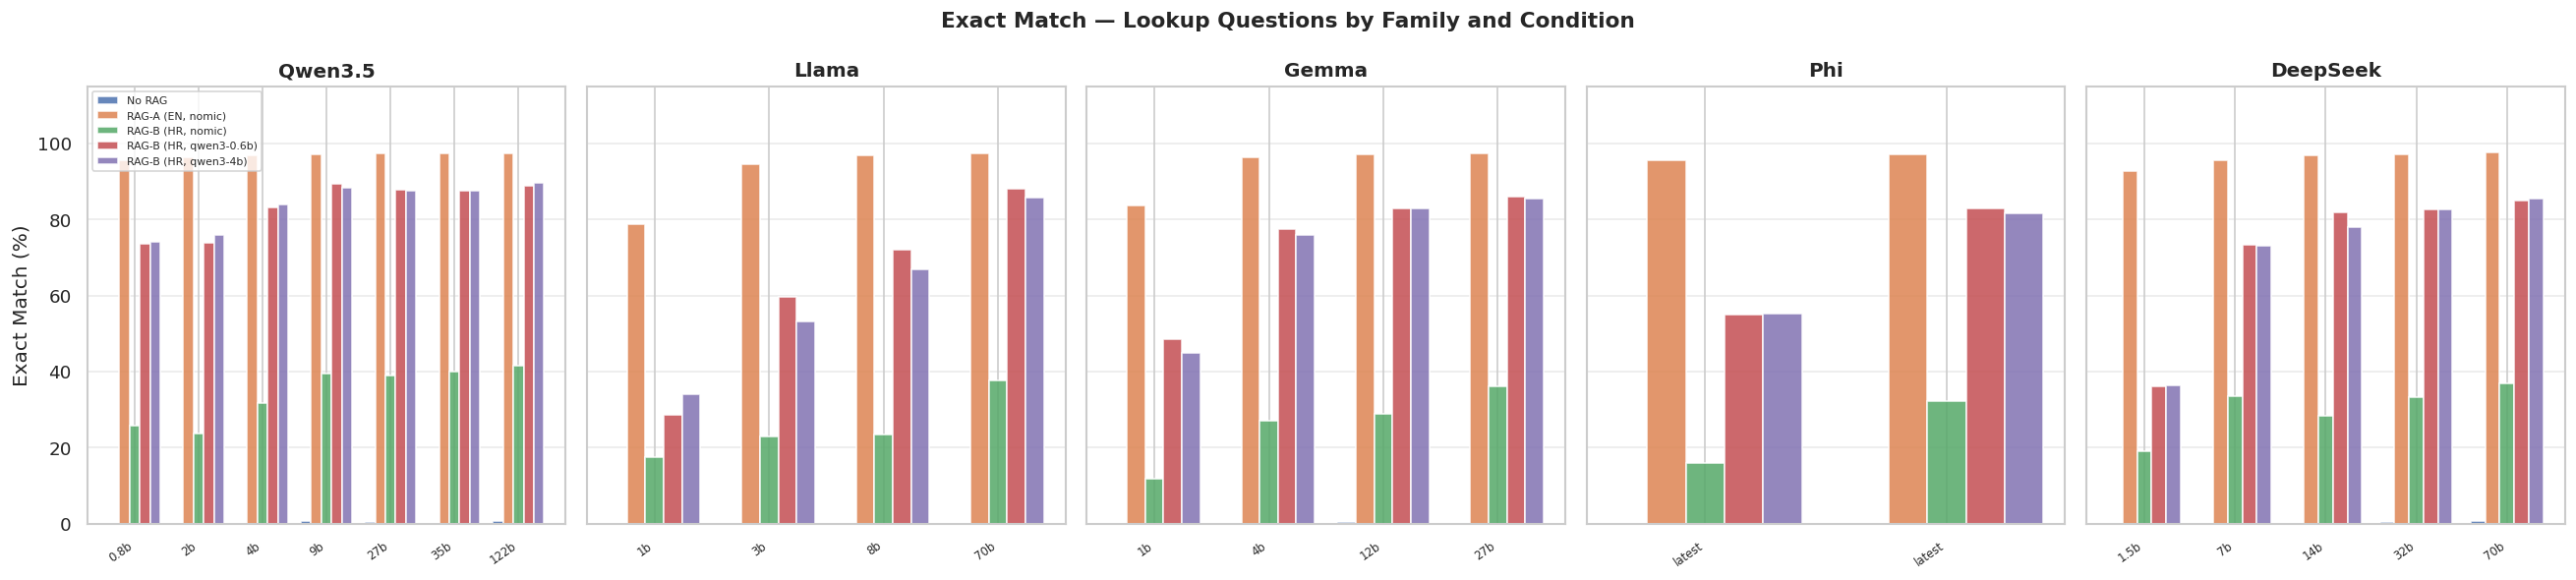

✓ Saved fig1


In [9]:
colors = {
    "no_rag":       "#4C72B0",
    "rag_a":        "#DD8452",
    "rag_b_nomic":  "#55A868",
    "rag_b_qwen3s": "#C44E52",
    "rag_b_qwen3m": "#8172B2",
}

fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Exact Match — Lookup Questions by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    fdf = df[df["family"] == family]
    x   = range(len(family_models))
    w   = 0.16
    for i, cond in enumerate(CONDITIONS):
        vals = []
        for m in family_models:
            v = fdf[(fdf["model"]==m)&(fdf["condition"]==cond)]["em_lookup"].values
            vals.append(v[0] if len(v) else 0)
        ax.bar([xi + i*w for xi in x], vals, w,
               label=COND_LABELS[cond], color=colors[cond], alpha=0.85)
    labels = [m.split(":")[-1] if ":" in m else m for m in family_models]
    ax.set_xticks([xi + 2*w for xi in x])
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=7)
    ax.set_title(family, fontweight="bold")
    ax.set_ylim(0, 115)
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Exact Match (%)")
axes[0].legend(loc="upper left", fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig1_em_by_family.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig1")


---
## 📈 Figure 2 — Semantic Similarity by family and condition

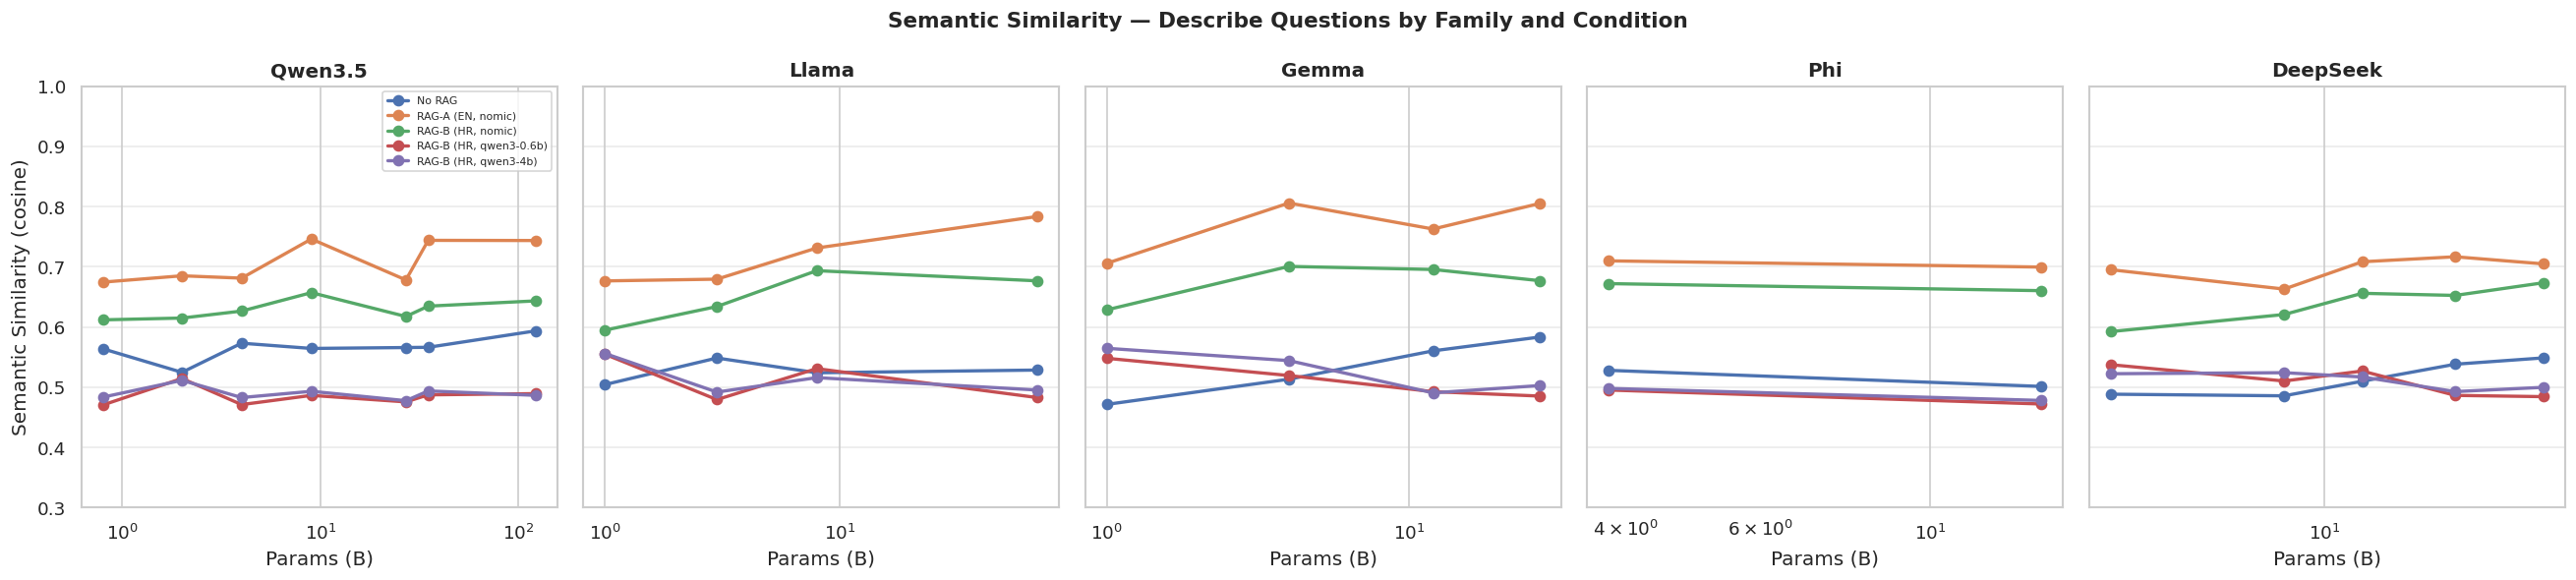

✓ Saved fig2


In [10]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Semantic Similarity — Describe Questions by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    fdf    = df[df["family"] == family]
    params = [MODEL_PARAMS.get(m, 0) for m in family_models]
    for cond in CONDITIONS:
        vals = []
        for m in family_models:
            v = fdf[(fdf["model"]==m)&(fdf["condition"]==cond)]["sem_sim_desc"].values
            vals.append(v[0] if len(v) else 0)
        ax.plot(params, vals, marker="o", label=COND_LABELS[cond],
                color=colors[cond], linewidth=2, markersize=6)
    ax.set_title(family, fontweight="bold")
    ax.set_xlabel("Params (B)")
    ax.set_xscale("log")
    ax.set_ylim(0.3, 1.0)
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Semantic Similarity (cosine)")
axes[0].legend(fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig2_semsim_by_family.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig2")


---
## 📈 Figure 3 — Hallucination Rate

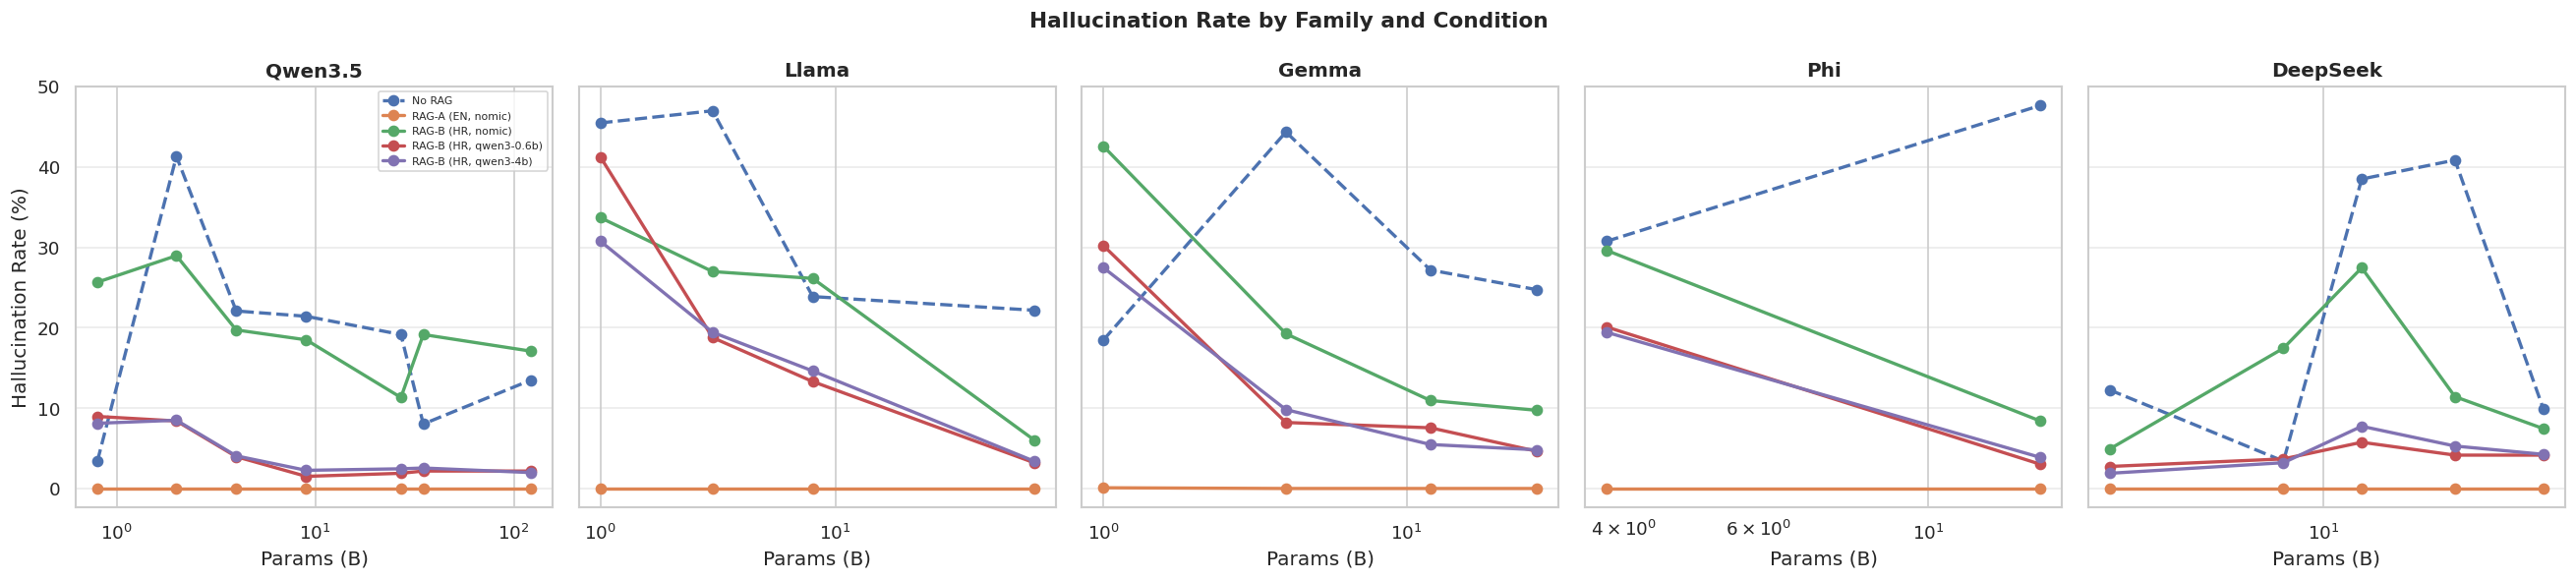

✓ Saved fig3


In [11]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Hallucination Rate by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    fdf    = df[df["family"] == family]
    params = [MODEL_PARAMS.get(m, 0) for m in family_models]
    for cond in CONDITIONS:
        ls  = "--" if cond == "no_rag" else "-"
        vals = []
        for m in family_models:
            v = fdf[(fdf["model"]==m)&(fdf["condition"]==cond)]["hallucination"].values
            vals.append(v[0] if len(v) else 0)
        ax.plot(params, vals, marker="o", label=COND_LABELS[cond],
                color=colors[cond], linewidth=2, markersize=6, linestyle=ls)
    ax.set_title(family, fontweight="bold")
    ax.set_xlabel("Params (B)")
    ax.set_xscale("log")
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Hallucination Rate (%)")
axes[0].legend(fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig3_hallucination.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig3")


---
## 📈 Figure 4 — Ablation: Cross-lingual gap & embedding model effect

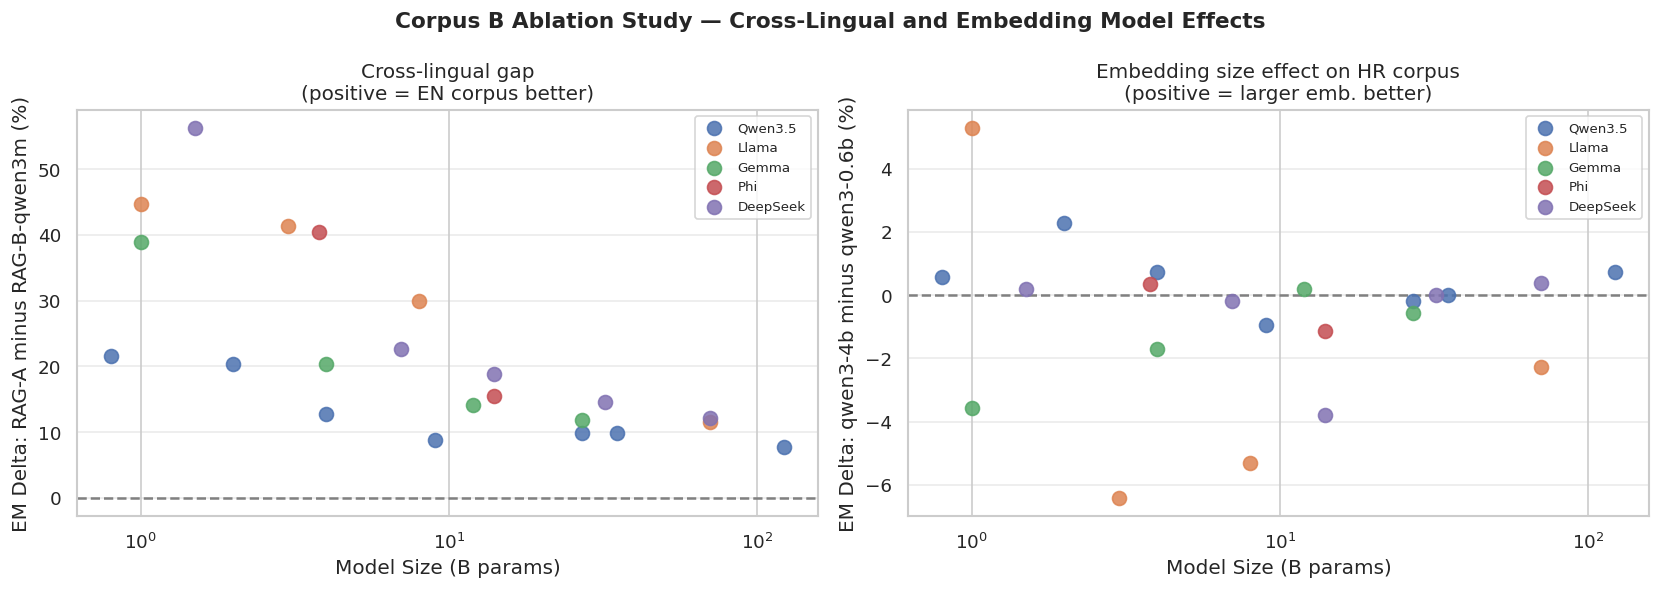

✓ Saved fig4


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Corpus B Ablation Study — Cross-Lingual and Embedding Model Effects",
             fontsize=13, fontweight="bold")
FAMILY_COLORS = {"Qwen3.5":"#4C72B0","Llama":"#DD8452",
                 "Gemma":"#55A868","Phi":"#C44E52","DeepSeek":"#8172B2"}

# Left: RAG-A vs RAG-B-qwen3m (best multilingual)
sub1 = df[df["condition"].isin(["rag_a","rag_b_qwen3m"])].copy()
piv1 = sub1.pivot_table(index=["model","family"], columns="condition",
                         values="em_lookup", aggfunc="first").reset_index()
if "rag_a" in piv1.columns and "rag_b_qwen3m" in piv1.columns:
    piv1["delta"]  = piv1["rag_a"] - piv1["rag_b_qwen3m"]
    piv1["params"] = piv1["model"].map(MODEL_PARAMS)
    for family in MODELS:
        fdf = piv1[piv1["family"]==family]
        axes[0].scatter(fdf["params"], fdf["delta"],
                        label=family, s=70,
                        color=FAMILY_COLORS.get(family,"gray"),
                        alpha=0.85, zorder=3)
    axes[0].axhline(0, color="gray", linestyle="--")
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Model Size (B params)")
    axes[0].set_ylabel("EM Delta: RAG-A minus RAG-B-qwen3m (%)")
    axes[0].set_title("Cross-lingual gap\n(positive = EN corpus better)")
    axes[0].legend(fontsize=8)
    axes[0].yaxis.grid(True, alpha=0.4)

# Right: qwen3s vs qwen3m on Corpus B (embedding size effect)
sub2 = df[df["condition"].isin(["rag_b_qwen3s","rag_b_qwen3m"])].copy()
piv2 = sub2.pivot_table(index=["model","family"], columns="condition",
                         values="em_lookup", aggfunc="first").reset_index()
if "rag_b_qwen3s" in piv2.columns and "rag_b_qwen3m" in piv2.columns:
    piv2["delta"]  = piv2["rag_b_qwen3m"] - piv2["rag_b_qwen3s"]
    piv2["params"] = piv2["model"].map(MODEL_PARAMS)
    for family in MODELS:
        fdf = piv2[piv2["family"]==family]
        axes[1].scatter(fdf["params"], fdf["delta"],
                        label=family, s=70,
                        color=FAMILY_COLORS.get(family,"gray"),
                        alpha=0.85, zorder=3)
    axes[1].axhline(0, color="gray", linestyle="--")
    axes[1].set_xscale("log")
    axes[1].set_xlabel("Model Size (B params)")
    axes[1].set_ylabel("EM Delta: qwen3-4b minus qwen3-0.6b (%)")
    axes[1].set_title("Embedding size effect on HR corpus\n(positive = larger emb. better)")
    axes[1].legend(fontsize=8)
    axes[1].yaxis.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig4_ablation_crosslingual.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig4")


---
## 📈 Figure 5 — Quality/VRAM tradeoff

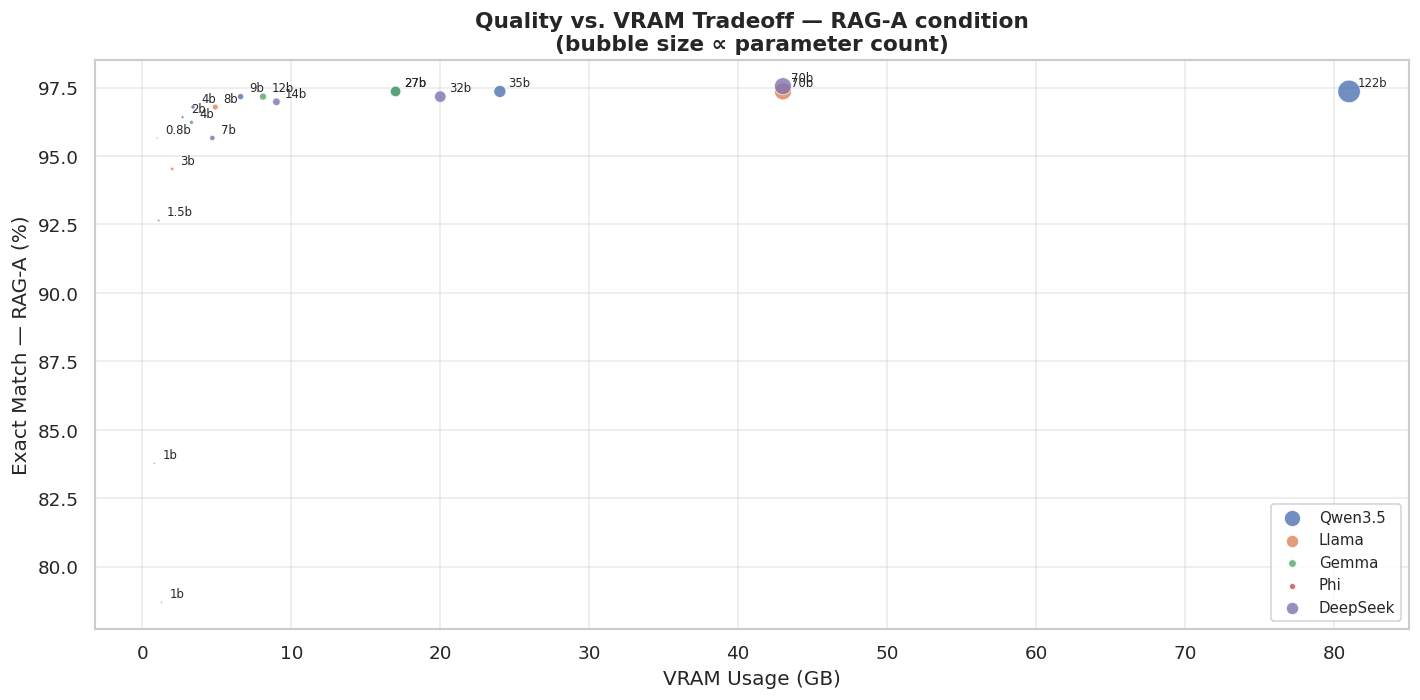

✓ Saved fig5


In [13]:
MODEL_VRAM = {
    "qwen3.5:0.8b":1.0, "qwen3.5:2b":2.7, "qwen3.5:4b":3.4,
    "qwen3.5:9b":6.6,   "qwen3.5:27b":17, "qwen3.5:35b":24,
    "qwen3.5:122b":81,
    "llama3.2:1b":1.3,  "llama3.2:3b":2.0,"llama3.1:8b":4.9,
    "llama3.3:70b":43,
    "gemma3:1b":0.8,    "gemma3:4b":3.3,  "gemma3:12b":8.1,
    "gemma3:27b":17,
    "phi4-mini":2.5,    "phi4":9.1,
    "deepseek-r1:1.5b":1.1,"deepseek-r1:7b":4.7,"deepseek-r1:14b":9.0,
    "deepseek-r1:32b":20,  "deepseek-r1:70b":43,
}

fig, ax = plt.subplots(figsize=(12, 6))
rag_a_df = df[df["condition"]=="rag_a"].copy()
rag_a_df["vram"] = rag_a_df["model"].map(MODEL_VRAM)

for family in MODELS:
    fdf = rag_a_df[rag_a_df["family"]==family]
    ax.scatter(fdf["vram"], fdf["em_lookup"],
               s=fdf["params_b"]*1.5,
               label=family,
               color=FAMILY_COLORS.get(family,"gray"),
               alpha=0.8, edgecolors="white", linewidth=0.5, zorder=3)
    for _, row in fdf.iterrows():
        label = row["model"].split(":")[-1] if ":" in row["model"] else row["model"]
        ax.annotate(label, (row["vram"], row["em_lookup"]),
                    xytext=(5,3), textcoords="offset points", fontsize=7)

ax.set_xlabel("VRAM Usage (GB)", fontsize=12)
ax.set_ylabel("Exact Match — RAG-A (%)", fontsize=12)
ax.set_title("Quality vs. VRAM Tradeoff — RAG-A condition\n"
             "(bubble size ∝ parameter count)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
ax.xaxis.grid(True, alpha=0.4)
ax.yaxis.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig5_quality_vram.png", bbox_inches="tight", dpi=150)
plt.show()
print("✓ Saved fig5")


---
## 📋 Final summary

In [14]:
print("=" * 80)
print("  FINAL RESULTS — RAG vs. No-RAG Multi-Family LLM Evaluation")
print("=" * 80)
header = (f"{'Model':<22} {'Family':<10} "
          f"{'NR':>6} {'A':>6} {'Bn':>7} {'Qs':>7} {'Qm':>7} "
          f"{'NR_H':>6} {'A_H':>5} {'Lat':>6}")
print(header)
print("-" * 80)

cond_map = {
    "no_rag":"NR", "rag_a":"A",
    "rag_b_nomic":"Bn", "rag_b_qwen3s":"Qs", "rag_b_qwen3m":"Qm"
}

for model in ALL_MODELS:
    family = next((f for f, ms in MODELS.items() if model in ms), "?")
    row    = df[df["model"] == model]
    def g(cond, col):
        v = row[row["condition"]==cond][col].values
        return v[0] if len(v) else float("nan")
    print(f"  {model:<20} {family:<10} "
          f"{g('no_rag','em_lookup'):>5.1f}% "
          f"{g('rag_a','em_lookup'):>5.1f}% "
          f"{g('rag_b_nomic','em_lookup'):>6.1f}% "
          f"{g('rag_b_qwen3s','em_lookup'):>6.1f}% "
          f"{g('rag_b_qwen3m','em_lookup'):>6.1f}% "
          f"{g('no_rag','hallucination'):>5.1f}% "
          f"{g('rag_a','hallucination'):>4.1f}% "
          f"{g('no_rag','avg_latency'):>5.2f}s")

print("=" * 80)
print(f"\n✓ All figures: {FIGURES_DIR}/")
print(f"✓ Full CSV:    {RESULTS_DIR}/full_metrics.csv")


  FINAL RESULTS — RAG vs. No-RAG Multi-Family LLM Evaluation
Model                  Family         NR      A      Bn      Qs      Qm   NR_H   A_H    Lat
--------------------------------------------------------------------------------
  qwen3.5:0.8b         Qwen3.5      0.0%  95.7%   25.7%   73.6%   74.2%   3.4%  0.0%  0.49s
  qwen3.5:2b           Qwen3.5      0.0%  96.4%   23.6%   73.8%   76.0%  41.3%  0.0%  0.49s
  qwen3.5:4b           Qwen3.5      0.2%  96.8%   31.7%   83.2%   84.0%  22.1%  0.0%  0.69s
  qwen3.5:9b           Qwen3.5      0.6%  97.2%   39.4%   89.2%   88.3%  21.4%  0.0%  0.80s
  qwen3.5:27b          Qwen3.5      0.4%  97.4%   39.1%   87.7%   87.5%  19.1%  0.0%  2.05s
  qwen3.5:35b          Qwen3.5      0.2%  97.4%   40.0%   87.5%   87.5%   8.0%  0.0%  0.88s
  qwen3.5:122b         Qwen3.5      0.8%  97.4%   41.5%   88.9%   89.6%  13.5%  0.0%  1.23s
  llama3.2:1b          Llama        0.0%  78.7%   17.6%   28.7%   34.0%  45.5%  0.0%  0.26s
  llama3.2:3b          Llama  

In [15]:
# Provjera da su potrebne varijable dostupne
print("df" in dir())
print("all_results" in dir())
print(f"df shape: {df.shape}" if "df" in dir() else "df NIJE definiran")

True
True
df shape: (110, 10)


## Reviewer Response — Retrieval Metrics (Recall@1, Recall@5, MRR)
 
Computed from `retrieved_ids` already stored in each checkpoint — no new
Ollama calls required. For lookup questions, we check whether the
ground-truth account number appears among the retrieved document IDs,
at rank 1 and within the top 5, and compute the Mean Reciprocal Rank.

In [16]:
 
def compute_retrieval_metrics(results):
    """
    For lookup questions only: checks whether the ground-truth account_number
    appears in the retrieved_ids list, and at what rank.
    Returns recall@1, recall@5, and MRR.
    """
    recall_at_1 = []
    recall_at_5 = []
    reciprocal_ranks = []
 
    for r in results:
        if r["q_type"] != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue
 
        retrieved = r.get("retrieved_ids", [])
        retrieved = [str(x).strip() for x in retrieved]
 
        if expected in retrieved:
            rank = retrieved.index(expected) + 1  # 1-indexed
            reciprocal_ranks.append(1.0 / rank)
            recall_at_1.append(1 if rank == 1 else 0)
            recall_at_5.append(1)
        else:
            reciprocal_ranks.append(0.0)
            recall_at_1.append(0)
            recall_at_5.append(0)
 
    n = len(reciprocal_ranks)
    if n == 0:
        return {"recall_at_1": None, "recall_at_5": None, "mrr": None, "n": 0}
 
    return {
        "recall_at_1": round(sum(recall_at_1) / n * 100, 2),
        "recall_at_5": round(sum(recall_at_5) / n * 100, 2),
        "mrr":         round(sum(reciprocal_ranks) / n, 4),
        "n": n,
    }
 
 
# Compute for every model x RAG condition (retrieval is condition-specific, not model-specific,
# but retrieved_ids were logged per model run so we report per model for completeness,
# then also show the condition-level aggregate since retrieval doesn't depend on the LLM).
retrieval_rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond == "no_rag":
            continue
        if cond in all_results.get(model, {}):
            m = compute_retrieval_metrics(all_results[model][cond])
            m["model"] = model
            m["condition"] = cond
            m["family"] = next((f for f, ms in MODELS.items() if model in ms), "?")
            retrieval_rows.append(m)
 
retrieval_df = pd.DataFrame(retrieval_rows)
 
# Since retrieval quality does not depend on the LLM being queried (only on the
# embedding model + corpus, both fixed per condition), aggregate across all models
# per condition to get the "true" retrieval-only metric, and report variance as a sanity check.
print("=== Retrieval Metrics by Condition (aggregated across all 22 models) ===")
agg = retrieval_df.groupby("condition")[["recall_at_1", "recall_at_5", "mrr"]].agg(["mean", "std"])
print(agg.round(3).to_string())
print()
print("Note: variance across models should be near-zero, since retrieval depends only on")
print("the embedding model and corpus, not on the generating LLM. Any variance here reflects")
print("logging artifacts (e.g., retrieval was re-run per model-condition pair).")
 
retrieval_df.to_csv(f"{RESULTS_DIR}/retrieval_metrics.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/retrieval_metrics.csv")
 

=== Retrieval Metrics by Condition (aggregated across all 22 models) ===
             recall_at_1        recall_at_5           mrr       
                    mean    std        mean    std   mean    std
condition                                                       
rag_a             92.640  0.000      97.360  0.000  0.948  0.000
rag_b_nomic        8.576  0.173      23.531  0.082  0.136  0.001
rag_b_qwen3m      45.470  0.000      80.000  0.000  0.583  0.000
rag_b_qwen3s      49.810  0.000      83.580  0.000  0.629  0.000

Note: variance across models should be near-zero, since retrieval depends only on
the embedding model and corpus, not on the generating LLM. Any variance here reflects
logging artifacts (e.g., retrieval was re-run per model-condition pair).

✓ Saved: data/results/retrieval_metrics.csv


## Reviewer Response — Statistical Significance (McNemar's Test)
 
Since temperature=0 makes each model's output deterministic, we cannot report
multi-run variance for a single model. However, comparisons BETWEEN models or
conditions on the same paired question set are a legitimate target for
McNemar's test, which is appropriate for paired binary (correct/incorrect)
outcomes. We report it for the "convergence" claims in Sections 6.6 and 7.1.

In [17]:

from statsmodels.stats.contingency_tables import mcnemar
 
def paired_em_arrays(model_a, model_b, condition):
    """Returns two aligned binary arrays of exact_match for the same question order."""
    res_a = all_results[model_a][condition]
    res_b = all_results[model_b][condition]
    # Align by question text to be safe against ordering differences
    lookup_a = {r["question"]: r["exact_match"] for r in res_a if r["q_type"] == "lookup"}
    lookup_b = {r["question"]: r["exact_match"] for r in res_b if r["q_type"] == "lookup"}
    common_qs = sorted(set(lookup_a) & set(lookup_b))
    a = [int(lookup_a[q]) for q in common_qs]
    b = [int(lookup_b[q]) for q in common_qs]
    return a, b
 
def mcnemar_test(model_a, model_b, condition):
    a, b = paired_em_arrays(model_a, model_b, condition)
    # 2x2 contingency table: [ [both correct, a correct b wrong], [a wrong b correct, both wrong] ]
    both_correct   = sum(1 for x, y in zip(a, b) if x == 1 and y == 1)
    a_only         = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    b_only         = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    both_wrong     = sum(1 for x, y in zip(a, b) if x == 0 and y == 0)
    table = [[both_correct, a_only], [b_only, both_wrong]]
    result = mcnemar(table, exact=True)
    return {
        "model_a": model_a, "model_b": model_b, "condition": condition,
        "em_a": round(sum(a)/len(a)*100, 2), "em_b": round(sum(b)/len(b)*100, 2),
        "n": len(a), "statistic": round(result.statistic, 4), "p_value": round(result.pvalue, 4),
        "significant_at_0.05": result.pvalue < 0.05,
    }
 
# Key convergence claims to validate - pick representative pairs spanning the
# claimed "plateau" region under rag_a, plus one clearly-different pair as a sanity check.
pairs_to_test = [
    ("qwen3.5:0.8b", "qwen3.5:122b", "rag_a"),      # smallest vs largest - claimed equal
    ("qwen3.5:4b",   "qwen3.5:27b",  "rag_a"),      # mid-range convergence claim
    ("llama3.1:8b",  "llama3.3:70b", "rag_a"),      # cross-size, same family
    ("qwen3.5:4b",   "gemma3:4b",    "rag_a"),      # cross-family, same size - architecture-independence claim
    ("qwen3.5:0.8b", "qwen3.5:2b",   "rag_a"),      # known outlier - should be significant
    ("qwen3.5:9b",   "gemma3:12b",   "rag_b_qwen3m"),  # RAG-B cross-family comparison
]
 
mcnemar_results = []
for model_a, model_b, cond in pairs_to_test:
    if model_a in all_results and cond in all_results[model_a] and \
       model_b in all_results and cond in all_results[model_b]:
        mcnemar_results.append(mcnemar_test(model_a, model_b, cond))
 
mcnemar_df = pd.DataFrame(mcnemar_results)
print("=== McNemar's Test - Key Pairwise EM Comparisons ===")
print(mcnemar_df.to_string(index=False))
print()
print("Interpretation: p < 0.05 indicates the EM difference between the pair is")
print("statistically significant and NOT attributable to chance, despite both being")
print("deterministic single runs - McNemar's test operates on the paired per-question")
print("outcomes, which is the appropriate unit of comparison here.")
 
mcnemar_df.to_csv(f"{RESULTS_DIR}/mcnemar_tests.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/mcnemar_tests.csv")
 

=== McNemar's Test - Key Pairwise EM Comparisons ===
     model_a      model_b    condition  em_a  em_b   n  statistic  p_value  significant_at_0.05
qwen3.5:0.8b qwen3.5:122b        rag_a 96.36 97.32 522        0.0   0.0625                False
  qwen3.5:4b  qwen3.5:27b        rag_a 97.13 97.32 522        0.0   1.0000                False
 llama3.1:8b llama3.3:70b        rag_a 97.32 97.32 522        0.0   1.0000                False
  qwen3.5:4b    gemma3:4b        rag_a 97.13 96.93 522        1.0   1.0000                False
qwen3.5:0.8b   qwen3.5:2b        rag_a 96.36 96.36 522        3.0   1.0000                False
  qwen3.5:9b   gemma3:12b rag_b_qwen3m 88.12 82.95 522        9.0   0.0001                 True

Interpretation: p < 0.05 indicates the EM difference between the pair is
statistically significant and NOT attributable to chance, despite both being
deterministic single runs - McNemar's test operates on the paired per-question
outcomes, which is the appropriate unit of co

## Reviewer Response — DeepSeek R1 Thinking-Trace Truncation
 
Checks what proportion of DeepSeek R1 responses were empty after stripping
`<think>` tags - a signal that the num_predict budget was exhausted by the
reasoning trace before a final answer was generated.

In [18]:
deepseek_models = MODELS["DeepSeek"]
 
truncation_rows = []
for model in deepseek_models:
    for cond in CONDITIONS:
        if cond not in all_results.get(model, {}):
            continue
        results = all_results[model][cond]
        total = len(results)
        empty = sum(1 for r in results if not r["response"].strip())
        very_short = sum(1 for r in results if 0 < len(r["response"].strip()) < 3)
        truncation_rows.append({
            "model": model, "condition": cond,
            "n": total,
            "empty_responses": empty,
            "empty_pct": round(empty / total * 100, 2),
            "very_short_responses": very_short,
            "very_short_pct": round(very_short / total * 100, 2),
        })
 
truncation_df = pd.DataFrame(truncation_rows)
print("=== DeepSeek R1 - Truncation / Empty Response Analysis ===")
print(truncation_df.to_string(index=False))
 
truncation_df.to_csv(f"{RESULTS_DIR}/deepseek_truncation.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/deepseek_truncation.csv")
print()
overall_empty_pct = truncation_df["empty_pct"].mean()
print(f"Average empty-response rate across DeepSeek R1 family: {overall_empty_pct:.2f}%")
 

=== DeepSeek R1 - Truncation / Empty Response Analysis ===
           model    condition    n  empty_responses  empty_pct  very_short_responses  very_short_pct
deepseek-r1:1.5b       no_rag 1060                0        0.0                     0             0.0
deepseek-r1:1.5b        rag_a 1060                0        0.0                     0             0.0
deepseek-r1:1.5b  rag_b_nomic 1060                0        0.0                     0             0.0
deepseek-r1:1.5b rag_b_qwen3s 1060                0        0.0                     0             0.0
deepseek-r1:1.5b rag_b_qwen3m 1060                0        0.0                     0             0.0
  deepseek-r1:7b       no_rag 1060                0        0.0                     0             0.0
  deepseek-r1:7b        rag_a 1060                0        0.0                     0             0.0
  deepseek-r1:7b  rag_b_nomic 1060                0        0.0                     0             0.0
  deepseek-r1:7b rag_b_qwen3s 10

## Reviewer Response — Fact-Checking Reported Values (Reviewer 3)
 
Recomputes the exact figures the text currently cites, to verify or correct:
1. Full list of models at 97.2-97.5% EM under RAG-A (text lists 7, reviewer says more)
2. No-RAG hallucination range (3.4 vs 3.5 discrepancy)
3. Which family actually has the 47.6% No-RAG hallucination max (Llama vs Phi)
4. DeepSeek R1 full hallucination range including the 32B outlier

In [19]:
no_rag_df = df[df["condition"] == "no_rag"].copy()
rag_a_df  = df[df["condition"] == "rag_a"].copy()
 
# 1. Models at 97.2-97.5% EM under RAG-A
high_performers = rag_a_df[rag_a_df["em_lookup"] >= 97.0].sort_values("em_lookup", ascending=False)
print("=== Models with EM >= 97.0% under RAG-A ===")
print(high_performers[["model", "family", "em_lookup"]].to_string(index=False))
print(f"\nTotal count: {len(high_performers)}")
 
print()
# 2. No-RAG hallucination overall range
print("=== No-RAG Hallucination - Overall Range ===")
print(f"Min: {no_rag_df['hallucination'].min():.2f}%  ({no_rag_df.loc[no_rag_df['hallucination'].idxmin(), 'model']})")
print(f"Max: {no_rag_df['hallucination'].max():.2f}%  ({no_rag_df.loc[no_rag_df['hallucination'].idxmax(), 'model']})")
 
print()
# 3. Which family has the max No-RAG hallucination value
print("=== No-RAG Hallucination by Family - Min/Max ===")
family_hall = no_rag_df.groupby("family")["hallucination"].agg(["min", "max"])
print(family_hall.round(2).to_string())
print()
print("Model with the overall maximum:")
max_row = no_rag_df.loc[no_rag_df["hallucination"].idxmax()]
print(f"  {max_row['model']} ({max_row['family']}): {max_row['hallucination']:.2f}%")
 
print()
# 4. DeepSeek R1 full No-RAG hallucination range (all 5 models)
print("=== DeepSeek R1 - No-RAG Hallucination, All 5 Models ===")
ds_hall = no_rag_df[no_rag_df["family"] == "DeepSeek"][["model", "hallucination"]].sort_values("hallucination")
print(ds_hall.to_string(index=False))
print(f"\nFull range: {ds_hall['hallucination'].min():.1f}% - {ds_hall['hallucination'].max():.1f}%")
print(f"Mean: {ds_hall['hallucination'].mean():.2f}%")
print()
print("NOTE: compare this full range/mean against the other four families' full")
print("ranges/means below before claiming DeepSeek R1 has the lowest hallucination.")
for fam in MODELS.keys():
    fam_hall = no_rag_df[no_rag_df["family"] == fam]["hallucination"]
    print(f"  {fam:10s}: mean={fam_hall.mean():.2f}%  range=[{fam_hall.min():.1f}, {fam_hall.max():.1f}]")
 

=== Models with EM >= 97.0% under RAG-A ===
          model   family  em_lookup
deepseek-r1:70b DeepSeek      97.55
    qwen3.5:27b  Qwen3.5      97.36
     gemma3:27b    Gemma      97.36
    qwen3.5:35b  Qwen3.5      97.36
   llama3.3:70b    Llama      97.36
   qwen3.5:122b  Qwen3.5      97.36
     qwen3.5:9b  Qwen3.5      97.17
     gemma3:12b    Gemma      97.17
    phi4:latest      Phi      97.17
deepseek-r1:32b DeepSeek      97.17

Total count: 10

=== No-RAG Hallucination - Overall Range ===
Min: 3.40%  (qwen3.5:0.8b)
Max: 47.64%  (phi4:latest)

=== No-RAG Hallucination by Family - Min/Max ===
            min    max
family                
DeepSeek   3.40  40.85
Gemma     18.49  44.34
Llama     22.17  46.98
Phi       30.75  47.64
Qwen3.5    3.40  41.32

Model with the overall maximum:
  phi4:latest (Phi): 47.64%

=== DeepSeek R1 - No-RAG Hallucination, All 5 Models ===
           model  hallucination
  deepseek-r1:7b           3.40
 deepseek-r1:70b           9.91
deepseek-r1:1.5b 

## Reviewer Response — Hallucination Summary Table
 
A dedicated table (parallel to Tables III/IV for EM and Semantic Similarity)
reporting exact hallucination percentages per model per condition.

In [20]:

pivot_hall_full = df.pivot_table(index=["family", "model"], columns="condition",
                                  values="hallucination", aggfunc="first")
pivot_hall_full = pivot_hall_full[[c for c in CONDITIONS if c in pivot_hall_full.columns]]
pivot_hall_full = pivot_hall_full.sort_index()
 
print("=== TABLE - Hallucination Rate by Model and Condition (%) ===")
print(pivot_hall_full.round(2).to_string())
 
pivot_hall_full.to_csv(f"{RESULTS_DIR}/hallucination_table.csv")
print(f"\n✓ Saved: {RESULTS_DIR}/hallucination_table.csv")

=== TABLE - Hallucination Rate by Model and Condition (%) ===
condition                  no_rag  rag_a  rag_b_nomic  rag_b_qwen3s  rag_b_qwen3m
family   model                                                                   
DeepSeek deepseek-r1:1.5b   12.26   0.00         4.91          2.74          1.89
         deepseek-r1:14b    38.49   0.00        27.45          5.75          7.74
         deepseek-r1:32b    40.85   0.00        11.42          4.15          5.28
         deepseek-r1:70b     9.91   0.00         7.45          4.15          4.25
         deepseek-r1:7b      3.40   0.00        17.45          3.68          3.21
Gemma    gemma3:12b         27.17   0.00        10.94          7.55          5.47
         gemma3:1b          18.49   0.09        42.55         30.19         27.45
         gemma3:27b         24.72   0.00         9.72          4.62          4.81
         gemma3:4b          44.34   0.00        19.25          8.21          9.81
Llama    llama3.1:8b        23.87   

## Reviewer Response — Negative Transfer Under RAG-B
 
Identifies models where Semantic Similarity under a RAG-B condition is LOWER
than the No-RAG baseline - i.e., retrieval actively hurts rather than helps.

In [21]:
neg_transfer_rows = []
for model in ALL_MODELS:
    no_rag_sim = df[(df["model"] == model) & (df["condition"] == "no_rag")]["sem_sim_desc"].values
    if len(no_rag_sim) == 0:
        continue
    baseline = no_rag_sim[0]
    for cond in ["rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"]:
        row = df[(df["model"] == model) & (df["condition"] == cond)]
        if len(row) == 0:
            continue
        sim = row["sem_sim_desc"].values[0]
        if sim < baseline:
            neg_transfer_rows.append({
                "model": model,
                "family": row["family"].values[0],
                "condition": cond,
                "no_rag_sim": baseline,
                "condition_sim": sim,
                "delta": round(sim - baseline, 4),
            })
 
neg_transfer_df = pd.DataFrame(neg_transfer_rows).sort_values("delta")
print("=== Negative Transfer - Semantic Similarity Lower Under RAG-B than No-RAG ===")
print(neg_transfer_df.to_string(index=False))
print(f"\nTotal instances of negative transfer: {len(neg_transfer_df)}")
print(f"Affected models: {neg_transfer_df['model'].nunique()} / {len(ALL_MODELS)}")
 
neg_transfer_df.to_csv(f"{RESULTS_DIR}/negative_transfer.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/negative_transfer.csv")
 

=== Negative Transfer - Semantic Similarity Lower Under RAG-B than No-RAG ===
           model   family    condition  no_rag_sim  condition_sim   delta
    qwen3.5:122b  Qwen3.5 rag_b_qwen3m      0.5937         0.4866 -0.1071
    qwen3.5:122b  Qwen3.5 rag_b_qwen3s      0.5937         0.4894 -0.1043
      qwen3.5:4b  Qwen3.5 rag_b_qwen3s      0.5732         0.4712 -0.1020
      gemma3:27b    Gemma rag_b_qwen3s      0.5834         0.4854 -0.0980
    qwen3.5:0.8b  Qwen3.5 rag_b_qwen3s      0.5638         0.4707 -0.0931
      qwen3.5:4b  Qwen3.5 rag_b_qwen3m      0.5732         0.4829 -0.0903
     qwen3.5:27b  Qwen3.5 rag_b_qwen3s      0.5660         0.4757 -0.0903
     qwen3.5:27b  Qwen3.5 rag_b_qwen3m      0.5660         0.4777 -0.0883
      gemma3:27b    Gemma rag_b_qwen3m      0.5834         0.5028 -0.0806
    qwen3.5:0.8b  Qwen3.5 rag_b_qwen3m      0.5638         0.4837 -0.0801
     qwen3.5:35b  Qwen3.5 rag_b_qwen3s      0.5664         0.4874 -0.0790
      qwen3.5:9b  Qwen3.5 rag_b_qw

In [22]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA G (ISPRAVLJENA) — Context Adherence, puni sadržaj konteksta
#
# ZAMJENJUJE prethodnu ćeliju G. Prethodna je koristila samo retrieved_ids,
# koji sadrži isključivo primarni ključ dokumenta. Corpus B dokumenti u tekstu
# nose i roditeljska konta (sintetičko, skupina), koja model legitimno citira.
# Ova verzija rekonstruira SVA konta vidljiva u dohvaćenom kontekstu.
#
# Radi iz postojećih checkpointa + corpus JSON — NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd

ACCOUNT_RE = re.compile(r"(?<!\d)\b(\d{3,4})\b(?!\d)")

# ── 1. Corpus B: ključ dokumenta → sva konta vidljiva u njegovom tekstu ───────
with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", encoding="utf-8") as f:
    _corpus_b = json.load(f)

CORPUS_B_VISIBLE = {}
for doc in _corpus_b:
    kljuc = str(doc["kljuc"]).strip()
    visible = set(ACCOUNT_RE.findall(doc["text"]))
    visible.add(kljuc)                      # ključ sam po sebi (npr. 2-znamenkasti)
    CORPUS_B_VISIBLE[kljuc] = visible

print(f"✓ Corpus B lookup: {len(CORPUS_B_VISIBLE)} dokumenata")
_example = next(k for k, v in CORPUS_B_VISIBLE.items() if len(v) > 1)
print(f"  Primjer — dokument {_example} čini vidljivima: "
      f"{sorted(CORPUS_B_VISIBLE[_example])}")

# ── 2. Corpus A: dokument sadrži samo vlastito konto ─────────────────────────
# Template je "Account number: XXX / English name / Croatian name",
# pa je retrieved_id ujedno i jedino konto u tekstu.

CORPUS_B_CONDITIONS = {"rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"}


def visible_accounts(retrieved_ids, condition):
    """Sva konta koja model stvarno vidi u dohvaćenom kontekstu."""
    visible = set()
    for rid in retrieved_ids:
        rid = str(rid).strip()
        if not rid:
            continue
        if condition in CORPUS_B_CONDITIONS:
            visible |= CORPUS_B_VISIBLE.get(rid, {rid})
        else:                                # rag_a
            visible.add(rid)
    return visible


def compute_context_adherence(results, condition):
    grounded            = []
    has_ungrounded      = []
    mentioned_any       = []
    ungrounded_but_real = []

    for r in results:
        response  = r.get("response", "")
        retrieved = r.get("retrieved_ids", [])
        found     = set(ACCOUNT_RE.findall(response))

        if not found:
            mentioned_any.append(0)
            continue

        mentioned_any.append(1)
        context = visible_accounts(retrieved, condition)
        outside = found - context

        grounded.append(0 if outside else 1)
        has_ungrounded.append(1 if outside else 0)
        ungrounded_but_real.append(
            1 if outside and outside.issubset(VALID_ACCOUNTS) else 0
        )

    n_mentions = len(grounded)
    n_total    = len(mentioned_any)

    return {
        "mention_rate":        round(np.mean(mentioned_any) * 100, 2) if n_total else 0.0,
        "grounded_pct":        round(np.mean(grounded) * 100, 2) if n_mentions else None,
        "ungrounded_pct":      round(np.mean(has_ungrounded) * 100, 2) if n_mentions else None,
        "ungrounded_but_real": round(np.mean(ungrounded_but_real) * 100, 2) if n_mentions else None,
        "n_with_mentions":     n_mentions,
    }


adherence_rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond == "no_rag":
            continue
        if cond not in all_results.get(model, {}):
            continue
        m = compute_context_adherence(all_results[model][cond], cond)
        m["model"]     = model
        m["condition"] = cond
        m["family"]    = next((f for f, ms in MODELS.items() if model in ms), "?")
        adherence_rows.append(m)

adherence_df = pd.DataFrame(adherence_rows)

print()
print("=== Context Adherence by Condition (mean across all 22 models) ===")
summary = adherence_df.groupby("condition")[
    ["grounded_pct", "ungrounded_pct", "ungrounded_but_real", "mention_rate"]
].mean().round(2)
summary = summary.reindex([c for c in CONDITIONS if c in summary.index])
print(summary.to_string())

print()
print("=== Grounded % by Model and Condition ===")
pivot_grounded = adherence_df.pivot_table(
    index=["family", "model"], columns="condition",
    values="grounded_pct", aggfunc="first"
)
pivot_grounded = pivot_grounded[[c for c in CONDITIONS if c in pivot_grounded.columns]]
print(pivot_grounded.round(2).to_string())

adherence_df.to_csv(f"{RESULTS_DIR}/context_adherence.csv", index=False)
pivot_grounded.to_csv(f"{RESULTS_DIR}/context_adherence_pivot.csv")
print(f"\n✓ Saved: {RESULTS_DIR}/context_adherence.csv")

print()
print("KEY FIGURES FOR THE PAPER:")
for cond in [c for c in CONDITIONS if c != "no_rag"]:
    if cond not in summary.index:
        continue
    row = summary.loc[cond]
    print(f"  {cond:14s}  grounded={row['grounded_pct']:.1f}%  "
          f"ungrounded={row['ungrounded_pct']:.1f}%  "
          f"(valid RRiF={row['ungrounded_but_real']:.1f}%)  "
          f"mention_rate={row['mention_rate']:.1f}%")

✓ Corpus B lookup: 2462 dokumenata
  Primjer — dokument 10000 čini vidljivima: ['100', '10000', '4699', '760']

=== Context Adherence by Condition (mean across all 22 models) ===
              grounded_pct  ungrounded_pct  ungrounded_but_real  mention_rate
condition                                                                    
rag_a                95.97            4.03                 3.98         96.24
rag_b_nomic          93.23            6.77                 6.33         84.93
rag_b_qwen3s         62.64           37.36                36.39         96.90
rag_b_qwen3m         59.84           40.16                39.72         96.17

=== Grounded % by Model and Condition ===
condition                  rag_a  rag_b_nomic  rag_b_qwen3s  rag_b_qwen3m
family   model                                                           
DeepSeek deepseek-r1:1.5b  95.98        90.36         53.19         49.32
         deepseek-r1:14b   96.21        94.33         62.44         59.87
         deeps

In [23]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA H — Dijagnostika: grounding po tipu pitanja + primjeri
#
# Cilj: utvrditi je li nizak grounding kod qwen3s/qwen3m stvarni nalaz
# ili artefakt (eho broja iz describe pitanja, suzdržavanje kod lošeg retrievala).
#
# Pokreni NAKON ispravljene ćelije G. Bez poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import numpy as np
import pandas as pd

ACCOUNT_RE = re.compile(r"(?<!\d)\b(\d{3,4})\b(?!\d)")


def question_accounts(question):
    """Konta koja se pojavljuju u samom tekstu pitanja (describe pitanja ih sadrže)."""
    return set(ACCOUNT_RE.findall(question or ""))


def adherence_by_qtype(results, condition):
    """Grounding rastavljen po tipu pitanja, sa i bez eha iz pitanja."""
    out = {}
    for q_type in ("lookup", "describe"):
        grounded_raw   = []   # kako smo mjerili do sada
        grounded_noecho = []  # nakon izuzimanja brojeva prisutnih u pitanju
        mention        = []

        for r in results:
            if r.get("q_type") != q_type:
                continue
            response = r.get("response", "")
            found    = set(ACCOUNT_RE.findall(response))

            if not found:
                mention.append(0)
                continue
            mention.append(1)

            context = visible_accounts(r.get("retrieved_ids", []), condition)
            echoed  = question_accounts(r.get("question", ""))

            outside_raw   = found - context
            outside_noecho = found - context - echoed

            grounded_raw.append(0 if outside_raw else 1)
            grounded_noecho.append(0 if outside_noecho else 1)

        out[f"{q_type}_mention_rate"]    = round(np.mean(mention) * 100, 2) if mention else 0.0
        out[f"{q_type}_grounded"]        = round(np.mean(grounded_raw) * 100, 2) if grounded_raw else None
        out[f"{q_type}_grounded_noecho"] = round(np.mean(grounded_noecho) * 100, 2) if grounded_noecho else None
    return out


rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond == "no_rag" or cond not in all_results.get(model, {}):
            continue
        m = adherence_by_qtype(all_results[model][cond], cond)
        m["model"], m["condition"] = model, cond
        rows.append(m)

qtype_df = pd.DataFrame(rows)

cols = ["lookup_grounded", "lookup_grounded_noecho", "lookup_mention_rate",
        "describe_grounded", "describe_grounded_noecho", "describe_mention_rate"]

print("=== Grounding po tipu pitanja (prosjek svih 22 modela) ===")
summary_q = qtype_df.groupby("condition")[cols].mean().round(2)
summary_q = summary_q.reindex([c for c in CONDITIONS if c in summary_q.index])
print(summary_q.to_string())

qtype_df.to_csv(f"{RESULTS_DIR}/adherence_by_qtype.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/adherence_by_qtype.csv")

# ── Primjeri ungrounded odgovora za ručnu provjeru ───────────────────────────
print("\n" + "=" * 78)
print("PRIMJERI UNGROUNDED ODGOVORA (rag_b_qwen3s, srednje velik model)")
print("=" * 78)

probe_model = "qwen3.5:9b" if "qwen3.5:9b" in all_results else ALL_MODELS[0]
probe_cond  = "rag_b_qwen3s"

shown = 0
for r in all_results.get(probe_model, {}).get(probe_cond, []):
    response = r.get("response", "")
    found    = set(ACCOUNT_RE.findall(response))
    if not found:
        continue
    context = visible_accounts(r.get("retrieved_ids", []), probe_cond)
    outside = found - context
    if not outside:
        continue

    echoed = question_accounts(r.get("question", ""))
    print(f"\n[{r.get('q_type')}] {r.get('question','')[:85]}")
    print(f"  GT            : {str(r.get('ground_truth',''))[:85]}")
    print(f"  Odgovor       : {response[:160]}")
    print(f"  Spomenuto     : {sorted(found)}")
    print(f"  U kontekstu   : {sorted(context)[:12]}{' ...' if len(context) > 12 else ''}")
    print(f"  IZVAN konteksta: {sorted(outside)}")
    print(f"  Od toga eho iz pitanja: {sorted(outside & echoed) or '—'}")
    shown += 1
    if shown >= 6:
        break

print(f"\n(prikazano {shown} primjera iz {probe_model} / {probe_cond})")

=== Grounding po tipu pitanja (prosjek svih 22 modela) ===
              lookup_grounded  lookup_grounded_noecho  lookup_mention_rate  describe_grounded  describe_grounded_noecho  describe_mention_rate
condition                                                                                                                                     
rag_a                   99.94                   99.94                99.26              91.62                     99.82                  93.22
rag_b_nomic             98.82                   98.82                75.72              88.72                     99.69                  94.13
rag_b_qwen3s            99.50                   99.50                95.99              26.49                     97.88                  97.80
rag_b_qwen3m            99.60                   99.60                95.74              20.46                     98.96                  96.59

✓ Saved: data/results/adherence_by_qtype.csv

PRIMJERI UNGROUNDED ODGOVORA (rag_b_

In [24]:
import json
with open("data/test_set.json") as f:
    ts = json.load(f)
for acc in ["608", "766"]:
    qs = [q for q in ts if isinstance(q["answer"], dict) 
          and q["answer"].get("account_number") == acc]
    print(f"Konto {acc}: {len(qs)} pitanja — {[q['q_type'] for q in qs]}")

Konto 608: 2 pitanja — ['lookup', 'describe']
Konto 766: 2 pitanja — ['lookup', 'describe']


In [25]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA J — Validacija cirkularnosti semantic similarity metrike
#
# Odgovara na: R1 issue 2, R2 issue 2
#
# Semantic similarity je u radu računan s nomic-embed-text, istim modelom kojim
# je indeksiran Corpus A. Recenzenti upozoravaju na cirkularnost. Ovdje istu
# metriku preračunavamo s qwen3-embedding:4b, koji NIJE korišten za Corpus A,
# pa je za RAG-A uvjet potpuno nezavisan.
#
# Trošak: ~2.300 embedding poziva (nekoliko minuta). LLM-ovi se NE pozivaju.
# ══════════════════════════════════════════════════════════════════════════════

import json
import os
import random
import numpy as np
import pandas as pd
import requests
from scipy.spatial.distance import cosine
from scipy.stats import pearsonr, spearmanr
from tqdm import tqdm

# ── Postavke ─────────────────────────────────────────────────────────────────
VALIDATION_CONDITION = "rag_a"          # jedini uvjet gdje je qwen3-4b nezavisan
VALIDATION_ENCODER   = EMBED_MODELS["qwen3m"]   # qwen3-embedding:4b
N_SAMPLE             = 100              # describe pitanja po modelu
RANDOM_SEED          = 42

VAL_CACHE_PATH = f"{RESULTS_DIR}/circularity_cache.json"

print(f"Nezavisni enkoder : {VALIDATION_ENCODER}")
print(f"Uvjet             : {VALIDATION_CONDITION}")
print(f"Uzorak            : {N_SAMPLE} describe pitanja po modelu")
print()
print("NAPOMENA: qwen3-embedding:4b je nezavisan SAMO za rag_a (Corpus A je")
print("indeksiran s nomic-embed-text). Za rag_b_qwen3m bio bi cirkularan.")
print()


# ── Cache da se ponovnim pokretanjem ne troše pozivi ─────────────────────────
def load_val_cache():
    if os.path.exists(VAL_CACHE_PATH):
        with open(VAL_CACHE_PATH) as f:
            return json.load(f)
    return {}


def save_val_cache(c):
    with open(VAL_CACHE_PATH, "w") as f:
        json.dump(c, f)


val_cache = load_val_cache()
print(f"Cache: {len(val_cache)} embeddinga\n")


def embed_validation(text):
    """Embedding nezavisnim enkoderom, s cacheom."""
    key = text[:300]
    if key in val_cache:
        return val_cache[key]
    r = requests.post(
        f"{OLLAMA_BASE_URL}/api/embeddings",
        json={"model": VALIDATION_ENCODER, "prompt": text},
        timeout=60,
    )
    r.raise_for_status()
    vec = r.json()["embedding"]
    val_cache[key] = vec
    return vec


def sim_validation(a, b):
    if not a or not b:
        return 0.0
    try:
        return round(1 - cosine(embed_validation(a), embed_validation(b)), 4)
    except Exception:
        return None


# ── Fiksni uzorak describe pitanja, isti za sve modele ───────────────────────
reference_model = ALL_MODELS[0]
all_describe = [
    r for r in all_results[reference_model][VALIDATION_CONDITION]
    if r.get("q_type") == "describe"
]
random.seed(RANDOM_SEED)
sample_questions = {
    r["question"] for r in random.sample(all_describe, min(N_SAMPLE, len(all_describe)))
}
print(f"Odabrano {len(sample_questions)} pitanja (seed={RANDOM_SEED})\n")


# ── Preračun po modelu ───────────────────────────────────────────────────────
rows = []
for model in tqdm(ALL_MODELS, desc="Modeli", ncols=72):
    results = all_results.get(model, {}).get(VALIDATION_CONDITION)
    if not results:
        continue

    sims_new = []
    for r in results:
        if r.get("q_type") != "describe" or r["question"] not in sample_questions:
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        gt_text = gt.get("english_name", gt.get("name", ""))
        s = sim_validation(r.get("response", ""), gt_text)
        if s is not None:
            sims_new.append(s)

    save_val_cache(val_cache)

    # Postojeća nomic vrijednost iz glavne analize
    nomic_row = df[(df["model"] == model) & (df["condition"] == VALIDATION_CONDITION)]
    nomic_val = nomic_row["sem_sim_desc"].values[0] if len(nomic_row) else None

    rows.append({
        "model":       model,
        "family":      next((f for f, ms in MODELS.items() if model in ms), "?"),
        "params_b":    MODEL_PARAMS.get(model, 0),
        "sim_nomic":   nomic_val,
        "sim_qwen3_4b": round(np.mean(sims_new), 4) if sims_new else None,
        "n":           len(sims_new),
    })

val_df = pd.DataFrame(rows).sort_values("params_b")

print("\n=== Semantic Similarity: nomic (rad) vs qwen3-embedding:4b (nezavisni) ===")
print(val_df[["model", "family", "params_b", "sim_nomic", "sim_qwen3_4b", "n"]]
      .to_string(index=False))

# ── Slažu li se dva enkodera? ────────────────────────────────────────────────
valid = val_df.dropna(subset=["sim_nomic", "sim_qwen3_4b"])
if len(valid) >= 3:
    pear_r, pear_p = pearsonr(valid["sim_nomic"], valid["sim_qwen3_4b"])
    spear_r, spear_p = spearmanr(valid["sim_nomic"], valid["sim_qwen3_4b"])

    print("\n" + "=" * 70)
    print("SLAGANJE IZMEĐU ENKODERA")
    print("=" * 70)
    print(f"  Pearson  r = {pear_r:.3f}  (p = {pear_p:.4f})")
    print(f"  Spearman r = {spear_r:.3f}  (p = {spear_p:.4f})")
    print(f"  n = {len(valid)} modela")

    # ── Drži li se nalaz o skaliranju s veličinom? ───────────────────────────
    size_nomic_r,  size_nomic_p  = spearmanr(valid["params_b"], valid["sim_nomic"])
    size_qwen_r,   size_qwen_p   = spearmanr(valid["params_b"], valid["sim_qwen3_4b"])

    print("\nKORELACIJA S VELIČINOM MODELA (Spearman):")
    print(f"  nomic        rho = {size_nomic_r:+.3f}  (p = {size_nomic_p:.4f})")
    print(f"  qwen3-emb:4b rho = {size_qwen_r:+.3f}  (p = {size_qwen_p:.4f})")
    print()
    if (size_nomic_r > 0) == (size_qwen_r > 0):
        print("  → Smjer se PODUDARA. Nalaz o skaliranju nije artefakt enkodera.")
    else:
        print("  → Smjer se NE podudara. Nalaz o skaliranju je osjetljiv na")
        print("    izbor enkodera i mora se u radu eksplicitno ograničiti.")

    print("\nREČENICE ZA RAD:")
    print(f"  Pearson r = {pear_r:.2f}, Spearman rho = {spear_r:.2f}, n = {len(valid)}")
    print(f"  Size-scaling: nomic rho = {size_nomic_r:+.2f}, "
          f"independent encoder rho = {size_qwen_r:+.2f}")

val_df.to_csv(f"{RESULTS_DIR}/circularity_validation.csv", index=False)
save_val_cache(val_cache)
print(f"\n✓ Saved: {RESULTS_DIR}/circularity_validation.csv")

Nezavisni enkoder : qwen3-embedding:4b
Uvjet             : rag_a
Uzorak            : 100 describe pitanja po modelu

NAPOMENA: qwen3-embedding:4b je nezavisan SAMO za rag_a (Corpus A je
indeksiran s nomic-embed-text). Za rag_b_qwen3m bio bi cirkularan.

Cache: 2290 embeddinga

Odabrano 100 pitanja (seed=42)



Modeli: 100%|███████████████████████████| 22/22 [01:10<00:00,  3.19s/it]



=== Semantic Similarity: nomic (rad) vs qwen3-embedding:4b (nezavisni) ===
           model   family  params_b  sim_nomic  sim_qwen3_4b   n
    qwen3.5:0.8b  Qwen3.5       0.8     0.6747        0.5755 103
     llama3.2:1b    Llama       1.0     0.6767        0.5954 103
       gemma3:1b    Gemma       1.0     0.7060        0.6748 103
deepseek-r1:1.5b DeepSeek       1.5     0.6953        0.5867 103
      qwen3.5:2b  Qwen3.5       2.0     0.6852        0.6014 103
     llama3.2:3b    Llama       3.0     0.6796        0.6124 103
phi4-mini:latest      Phi       3.8     0.7100        0.6469 103
       gemma3:4b    Gemma       4.0     0.8061        0.7428 103
      qwen3.5:4b  Qwen3.5       4.0     0.6813        0.5409 103
  deepseek-r1:7b DeepSeek       7.0     0.6631        0.5602 103
     llama3.1:8b    Llama       8.0     0.7314        0.6753 103
      qwen3.5:9b  Qwen3.5       9.0     0.7463        0.6835 103
      gemma3:12b    Gemma      12.0     0.7629        0.6563 103
     phi4:late

In [26]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA K — Strict Exact Match: izdvajanje KONAČNO predloženog konta
#
# Odgovara na: primjedbu o tome da EM mjeri prisutnost referentne šifre,
#              a ne točnost konačnog odgovora (i na R1 issue 1).
#
# Trenutni EM traži GT broj bilo gdje u odgovoru. Odgovor tipa
#   "Točan je konto 021, a ne 020."
# prolazi kao točan ako je GT = 020, iako ga model odbacuje.
#
# Ova ćelija izdvaja jedan konačno predloženi konto po odgovoru i računa
# strogi EM. Radi iz postojećih checkpointa — NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd

ACC = r"(\d{3,4})"

# ── Redoslijed heuristika za izdvajanje konačnog odgovora ────────────────────
# 1. Podebljani broj — modeli gotovo uvijek podebljaju konačni odgovor
BOLD_RE      = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
# 2. Eksplicitna formulacija odgovora
IS_RE        = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE      = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE   = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
# 3. Bilo koji samostalan 3–4 znamenkasti broj
ANY_RE       = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")


def extract_final_account(response):
    """
    Vraća (predlozeni_konto, metoda, svi_spomenuti).
    Metoda služi za dijagnostiku pouzdanosti izdvajanja.
    """
    if not response or not response.strip():
        return None, "empty", []

    all_found = ANY_RE.findall(response)

    for rx, name in ((BOLD_RE, "bold"), (IS_RE, "is-pattern"),
                     (CODE_RE, "code-pattern"), (ACCOUNT_RE, "account-pattern")):
        m = rx.search(response)
        if m:
            return m.group(1), name, all_found

    if all_found:
        return all_found[0], "first-number", all_found

    return None, "no-number", all_found


def strict_metrics(results):
    strict, lenient, ambiguous = [], [], []
    methods = []

    for r in results:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue

        response = r.get("response", "")
        proposed, method, all_found = extract_final_account(response)

        strict.append(1 if proposed == expected else 0)
        lenient.append(1 if expected in all_found else 0)
        ambiguous.append(1 if len(set(all_found)) > 1 else 0)
        methods.append(method)

    n = len(strict)
    if n == 0:
        return None

    return {
        "em_strict":      round(np.mean(strict) * 100, 2),
        "em_lenient":     round(np.mean(lenient) * 100, 2),
        "delta":          round((np.mean(lenient) - np.mean(strict)) * 100, 2),
        "ambiguous_pct":  round(np.mean(ambiguous) * 100, 2),
        "extract_bold_pct": round(methods.count("bold") / n * 100, 1),
        "extract_fallback_pct": round(methods.count("first-number") / n * 100, 1),
        "n": n,
    }


rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond not in all_results.get(model, {}):
            continue
        m = strict_metrics(all_results[model][cond])
        if m is None:
            continue
        m["model"], m["condition"] = model, cond
        m["family"] = next((f for f, ms in MODELS.items() if model in ms), "?")
        rows.append(m)

strict_df = pd.DataFrame(rows)

print("=== Strict vs. Lenient Exact Match (lookup) ===")
cols = ["model", "condition", "em_strict", "em_lenient", "delta", "ambiguous_pct"]
print(strict_df[cols].to_string(index=False))

print("\n=== Sažetak po uvjetu ===")
summary = strict_df.groupby("condition")[
    ["em_strict", "em_lenient", "delta", "ambiguous_pct",
     "extract_bold_pct", "extract_fallback_pct"]
].mean().round(2)
summary = summary.reindex([c for c in CONDITIONS if c in summary.index])
print(summary.to_string())

strict_df.to_csv(f"{RESULTS_DIR}/strict_em.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/strict_em.csv")

# ── Slučajevi gdje se stroga i blaga mjera razilaze — za ručnu provjeru ──────
print("\n" + "=" * 78)
print("PRIMJERI: lenient=TOČNO, strict=NETOČNO  (rag_a)")
print("=" * 78)

probe_cond = "rag_a"
shown = 0
for model in ALL_MODELS:
    if probe_cond not in all_results.get(model, {}):
        continue
    for r in all_results[model][probe_cond]:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        response = r.get("response", "")
        proposed, method, all_found = extract_final_account(response)

        if expected in all_found and proposed != expected:
            print(f"\n[{model}] GT={expected}  izdvojeno={proposed} ({method})")
            print(f"  Q: {r.get('question','')[:80]}")
            print(f"  A: {response[:220]}")
            shown += 1
            break
    if shown >= 8:
        break

print(f"\n(prikazano {shown} slučajeva neslaganja)")
print("\nRUČNA PROVJERA: pregledaj gornje primjere i procijeni je li")
print("izdvojeni konto doista konačni odgovor modela. Ako heuristika griješi,")
print("javi primjere pa prilagodimo redoslijed regexa.")

=== Strict vs. Lenient Exact Match (lookup) ===
           model    condition  em_strict  em_lenient  delta  ambiguous_pct
    qwen3.5:0.8b       no_rag       0.00        0.00   0.00           1.32
    qwen3.5:0.8b        rag_a      95.28       95.66   0.38           1.13
    qwen3.5:0.8b  rag_b_nomic      25.47       25.66   0.19           3.58
    qwen3.5:0.8b rag_b_qwen3s      73.58       73.58   0.00           0.75
    qwen3.5:0.8b rag_b_qwen3m      73.96       74.15   0.19           0.75
      qwen3.5:2b       no_rag       0.00        0.00   0.00           8.68
      qwen3.5:2b        rag_a      94.91       96.42   1.51           5.47
      qwen3.5:2b  rag_b_nomic      23.58       23.58   0.00           6.60
      qwen3.5:2b rag_b_qwen3s      73.40       73.77   0.38           2.64
      qwen3.5:2b rag_b_qwen3m      75.66       76.04   0.38           2.45
      qwen3.5:4b       no_rag       0.19        0.19   0.00           6.60
      qwen3.5:4b        rag_a      96.04       96.79

In [27]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA L — Dvosmislenost benchmarka: konta koja dijele isti engleski naziv
#
# Primjeri neslaganja strogog i blagog EM-a pokazuju da više konta dijeli
# identičan engleski naziv (213/257, 225/254, 061/111). Za takva lookup
# pitanja ne postoji jedinstven točan odgovor.
#
# Radi iz test_set.json — bez poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import json
import re
from collections import defaultdict
import numpy as np
import pandas as pd

with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    test_set = json.load(f)

# ── Mapiranje engleskog naziva → skup konta ──────────────────────────────────
name_to_accounts = defaultdict(set)
for q in test_set:
    a = q.get("answer")
    if not isinstance(a, dict):
        continue
    acc  = str(a.get("account_number", "")).strip()
    name = (a.get("english_name") or a.get("name") or "").strip().lower()
    if acc and name:
        name_to_accounts[name].add(acc)

ambiguous_names = {n: accs for n, accs in name_to_accounts.items() if len(accs) > 1}

print(f"Jedinstvenih engleskih naziva : {len(name_to_accounts)}")
print(f"Naziva s više od jednog konta : {len(ambiguous_names)}")
print()
print("Dvosmisleni nazivi:")
for n, accs in sorted(ambiguous_names.items()):
    print(f"  {sorted(accs)}  —  {n[:80]}")

# ── Koliko lookup pitanja pogađa ta dvosmislenost ────────────────────────────
ambiguous_accounts = set()
for accs in ambiguous_names.values():
    ambiguous_accounts |= accs

lookup_qs = [q for q in test_set if q.get("q_type") == "lookup"]
affected = [
    q for q in lookup_qs
    if isinstance(q.get("answer"), dict)
    and str(q["answer"].get("account_number", "")).strip() in ambiguous_accounts
]

print()
print(f"Lookup pitanja ukupno   : {len(lookup_qs)}")
print(f"Pogođenih dvosmislenošću: {len(affected)}  ({len(affected)/len(lookup_qs)*100:.2f}%)")

# ── Koliki udio razlike strogi/blagi otpada na ta pitanja ────────────────────
ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")


def extract_final(response):
    if not response or not response.strip():
        return None, []
    all_found = ANY_RE.findall(response)
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(response)
        if m:
            return m.group(1), all_found
    return (all_found[0] if all_found else None), all_found


rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond == "no_rag" or cond not in all_results.get(model, {}):
            continue
        disagree_amb, disagree_other = 0, 0
        for r in all_results[model][cond]:
            if r.get("q_type") != "lookup":
                continue
            try:
                gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                     else r["ground_truth"]
            except Exception:
                continue
            expected = str(gt.get("account_number", "")).strip()
            if not expected:
                continue
            proposed, all_found = extract_final(r.get("response", ""))
            # slučaj neslaganja: blagi točan, strogi netočan
            if expected in all_found and proposed != expected:
                if expected in ambiguous_accounts:
                    disagree_amb += 1
                else:
                    disagree_other += 1
        rows.append({
            "model": model, "condition": cond,
            "disagree_ambiguous": disagree_amb,
            "disagree_other": disagree_other,
            "total_disagree": disagree_amb + disagree_other,
        })

dis_df = pd.DataFrame(rows)
agg = dis_df.groupby("condition")[
    ["disagree_ambiguous", "disagree_other", "total_disagree"]
].sum()
agg["pct_from_ambiguity"] = (agg["disagree_ambiguous"] / agg["total_disagree"] * 100).round(1)
agg = agg.reindex([c for c in CONDITIONS if c in agg.index])

print()
print("=== Izvor razlike strogi vs. blagi EM ===")
print(agg.to_string())
print()
print("pct_from_ambiguity = udio neslaganja koji otpada na pitanja gdje")
print("više konta dijeli isti engleski naziv (dvosmislen benchmark),")
print("a ne na model koji odbacuje referentnu šifru.")

dis_df.to_csv(f"{RESULTS_DIR}/em_disagreement_source.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/em_disagreement_source.csv")

Jedinstvenih engleskih naziva : 522
Naziva s više od jednog konta : 8

Dvosmisleni nazivi:
  ['512', '542']  —  depreciation in selling costs amortizacija u troškovima prodaje
  ['803', '822']  —  income tax expense porez na dobitak (gubitak)
  ['225', '254']  —  liabilities for advances received obveze za predujmove
  ['213', '257']  —  liabilities towards associated undertakings obveze prema društvima povezanim sud
  ['801', '821']  —  loss before tax gubitak prije oporezivanja
  ['500', '530']  —  material used in management and administrative overheads materijal u troškovima 
  ['800', '820']  —  profit before tax dobitak prije oporezivanja
  ['804', '823']  —  profit or loss for the year dobitak ili gubitak razdoblja

Lookup pitanja ukupno   : 530
Pogođenih dvosmislenošću: 18  (3.40%)

=== Izvor razlike strogi vs. blagi EM ===
              disagree_ambiguous  disagree_other  total_disagree  pct_from_ambiguity
condition                                                              

Koristim strict_df iz memorije
Redaka: 110


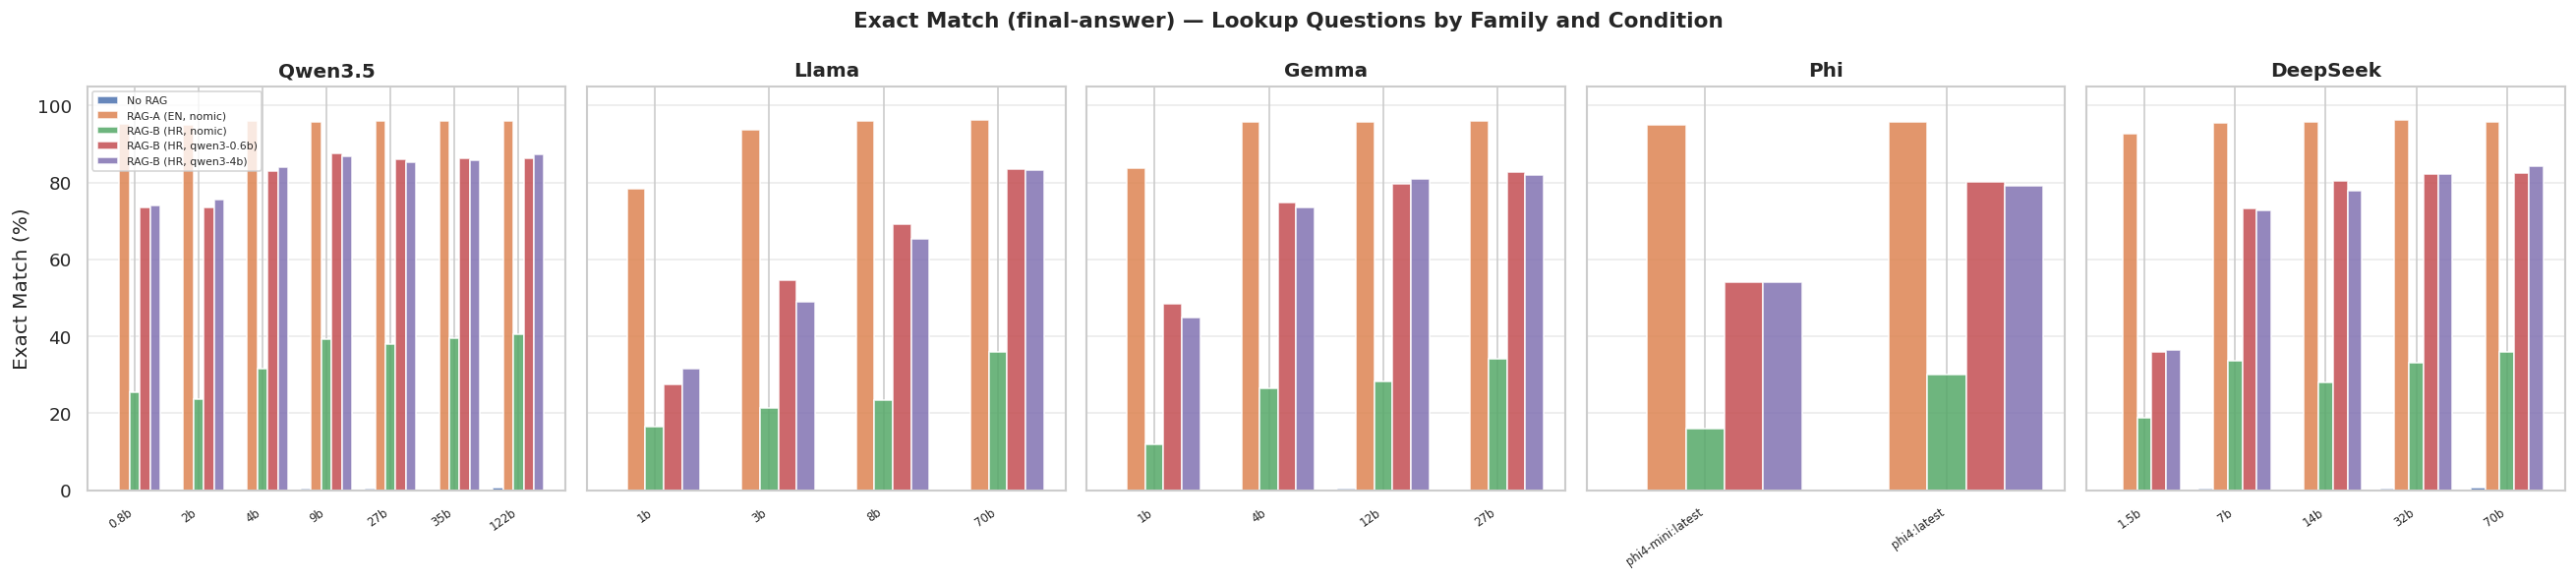

✓ fig1_em_by_family.png / .pdf


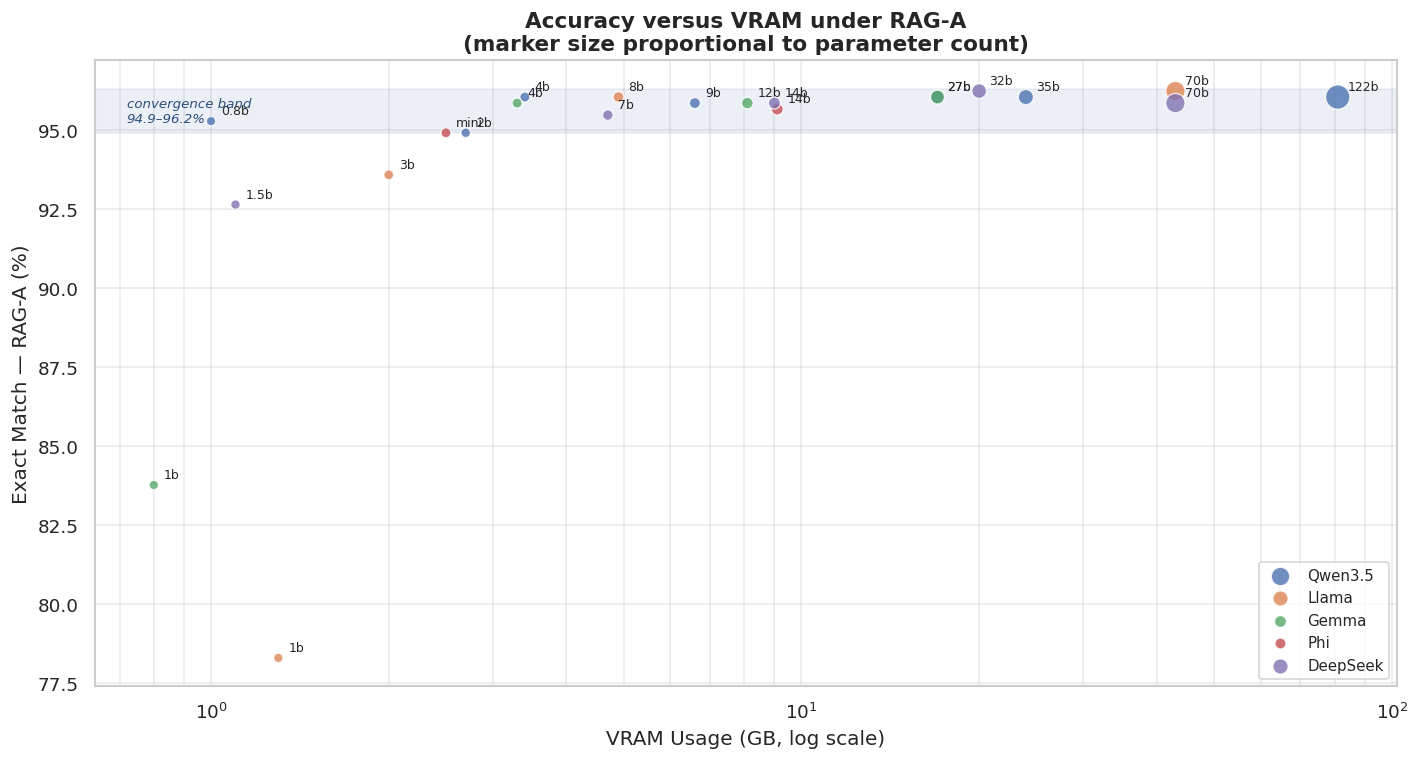

✓ fig5_quality_vram.png / .pdf

Modela u pojasu 95.0–96.3%: 16
          model   family  em_strict
   llama3.3:70b    Llama      96.23
deepseek-r1:32b DeepSeek      96.23
    qwen3.5:35b  Qwen3.5      96.04
     qwen3.5:4b  Qwen3.5      96.04
   qwen3.5:122b  Qwen3.5      96.04
    llama3.1:8b    Llama      96.04
     gemma3:27b    Gemma      96.04
    qwen3.5:27b  Qwen3.5      96.04
deepseek-r1:70b DeepSeek      95.85
     qwen3.5:9b  Qwen3.5      95.85
     gemma3:12b    Gemma      95.85
      gemma3:4b    Gemma      95.85
deepseek-r1:14b DeepSeek      95.85
    phi4:latest      Phi      95.66
 deepseek-r1:7b DeepSeek      95.47
   qwen3.5:0.8b  Qwen3.5      95.28


In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA M — Regeneracija Slika 1 i 5 iz STROGOG Exact Matcha
#
# Zamjenjuje izvorne ćelije za Figure 1 i Figure 5, koje su crtale iz
# em_lookup (blaga mjera). Ovdje se crta iz em_strict.
#
# Preduvjet: ćelija K je izvršena (strict_df u memoriji), ili postoji
#            data/results/strict_em.csv.
# ══════════════════════════════════════════════════════════════════════════════

import os
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="muted")

# ── Učitaj strogi EM ─────────────────────────────────────────────────────────
if "strict_df" not in dir():
    strict_df = pd.read_csv(f"{RESULTS_DIR}/strict_em.csv")
    print("Učitano iz strict_em.csv")
else:
    print("Koristim strict_df iz memorije")

print(f"Redaka: {len(strict_df)}")

COND_COLORS = {
    "no_rag":       "#4C72B0",
    "rag_a":        "#DD8452",
    "rag_b_nomic":  "#55A868",
    "rag_b_qwen3s": "#C44E52",
    "rag_b_qwen3m": "#8172B2",
}

FAMILY_COLORS = {
    "Qwen3.5":  "#4C72B0",
    "Llama":    "#DD8452",
    "Gemma":    "#55A868",
    "Phi":      "#C44E52",
    "DeepSeek": "#8172B2",
}

MODEL_VRAM = {
    "qwen3.5:0.8b": 1.0, "qwen3.5:2b": 2.7,  "qwen3.5:4b": 3.4,
    "qwen3.5:9b":   6.6, "qwen3.5:27b": 17.0, "qwen3.5:35b": 24.0,
    "qwen3.5:122b": 81.0,
    "llama3.2:1b":  1.3, "llama3.2:3b": 2.0,  "llama3.1:8b": 4.9,
    "llama3.3:70b": 43.0,
    "gemma3:1b":    0.8, "gemma3:4b":   3.3,  "gemma3:12b":  8.1,
    "gemma3:27b":   17.0,
    "phi4-mini:latest": 2.5, "phi4:latest": 9.1,
    "deepseek-r1:1.5b": 1.1, "deepseek-r1:7b":  4.7,
    "deepseek-r1:14b":  9.0, "deepseek-r1:32b": 20.0,
    "deepseek-r1:70b":  43.0,
}


def em_value(model, cond):
    v = strict_df[(strict_df["model"] == model) &
                  (strict_df["condition"] == cond)]["em_strict"].values
    return v[0] if len(v) else 0.0


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 1 — Exact Match (strict) po familiji i uvjetu
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Exact Match (final-answer) — Lookup Questions by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    x = range(len(family_models))
    w = 0.16
    for i, cond in enumerate(CONDITIONS):
        vals = [em_value(m, cond) for m in family_models]
        ax.bar([xi + i * w for xi in x], vals, w,
               label=COND_LABELS[cond], color=COND_COLORS[cond], alpha=0.85)
    labels = [m.split(":")[-1] if ":" in m else m for m in family_models]
    labels = [l.replace("latest", "").strip() or m for l, m in zip(labels, family_models)]
    ax.set_xticks([xi + 2 * w for xi in x])
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=7)
    ax.set_title(family, fontweight="bold")
    ax.set_ylim(0, 105)
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Exact Match (%)")
axes[0].legend(loc="upper left", fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig1_em_by_family.png", bbox_inches="tight", dpi=300)
plt.savefig(f"{FIGURES_DIR}/fig1_em_by_family.pdf", bbox_inches="tight")
plt.show()
print(f"✓ fig1_em_by_family.png / .pdf")


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 5 — Quality-per-VRAM (strict EM, RAG-A)
# ══════════════════════════════════════════════════════════════════════════════
rag_a = strict_df[strict_df["condition"] == "rag_a"].copy()
rag_a["vram"]     = rag_a["model"].map(MODEL_VRAM)
rag_a["params_b"] = rag_a["model"].map(MODEL_PARAMS)

fig, ax = plt.subplots(figsize=(12, 6.5))

for family in MODELS:
    fdf = rag_a[rag_a["family"] == family]
    if not len(fdf):
        continue
    ax.scatter(fdf["vram"], fdf["em_strict"],
               s=fdf["params_b"] * 1.5 + 30,
               label=family,
               color=FAMILY_COLORS.get(family, "gray"),
               alpha=0.8, edgecolors="white", linewidth=0.8, zorder=3)
    for _, row in fdf.iterrows():
        lbl = row["model"].split(":")[-1] if ":" in row["model"] else row["model"]
        lbl = lbl.replace("latest", "mini" if "mini" in row["model"] else "14b")
        ax.annotate(lbl, (row["vram"], row["em_strict"]),
                    xytext=(6, 4), textcoords="offset points", fontsize=7.5)

# Pojas konvergencije
band_lo, band_hi = 94.9, 96.3
ax.axhspan(band_lo, band_hi, color="#4C72B0", alpha=0.10, zorder=1)
ax.text(0.72, (band_lo + band_hi) / 2, "convergence band\n94.9–96.2%",
        fontsize=8, color="#2C4F7C", va="center", ha="left", style="italic")

ax.set_xscale("log")
ax.set_xlabel("VRAM Usage (GB, log scale)", fontsize=12)
ax.set_ylabel("Exact Match — RAG-A (%)", fontsize=12)
ax.set_title("Accuracy versus VRAM under RAG-A\n(marker size proportional to parameter count)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="lower right")
ax.grid(True, alpha=0.4, which="both")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig5_quality_vram.png", bbox_inches="tight", dpi=300)
plt.savefig(f"{FIGURES_DIR}/fig5_quality_vram.pdf", bbox_inches="tight")
plt.show()
print(f"✓ fig5_quality_vram.png / .pdf")

# ── Provjera pojasa ──────────────────────────────────────────────────────────
in_band = rag_a[(rag_a["em_strict"] >= 95.0) & (rag_a["em_strict"] <= 96.3)]
print(f"\nModela u pojasu 95.0–96.3%: {len(in_band)}")
print(in_band[["model", "family", "em_strict"]]
      .sort_values("em_strict", ascending=False).to_string(index=False))

In [29]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA S — ISPRAVAK: registar valjanih konta + ponovni izracun klasifikacije PRIJE N I R!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#
# Provjera R pokazala je da VALID_ACCOUNTS u ovom notebooku sadrzi samo 522
# troznamenkasta konta iz accounts.jsonl. Prosirenje na konta Corpusa B nikada
# nije usla u notebook 05. Posljedica: sva cetveroznamenkasta i peteroznamenkasta
# konta iz RRiF plana bila su oznacena kao fabricirana.
#
# Ova celija ispravlja registar i ponovno racuna klasifikaciju ishoda.
# Pokreni PRIJE celija N i R, ili umjesto izvorne celije koja gradi VALID_ACCOUNTS.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd
from collections import Counter

# ── 1. Ispravan registar ────────────────────────────────────────────────────
with open("accounts.jsonl", encoding="utf-8") as f:
    _raw = [json.loads(l) for l in f if l.strip()]

VALID_ACCOUNTS = set()
for d in _raw:
    a = json.loads(next(c for c in d["conversations"]
                        if c["role"] == "assistant")["content"])
    acc = str(a.get("account_number", "")).strip()
    if acc:
        VALID_ACCOUNTS.add(acc)
n_jsonl = len(VALID_ACCOUNTS)

with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", encoding="utf-8") as f:
    _corpus_b = json.load(f)

for doc in _corpus_b:
    k = str(doc["kljuc"]).strip()
    if k:
        VALID_ACCOUNTS.add(k)

VALID_ACCOUNTS.discard("")

print("ISPRAVLJENI REGISTAR")
print(f"  iz accounts.jsonl        : {n_jsonl}")
print(f"  iz Corpusa B             : {len(_corpus_b)}")
print(f"  ukupno jedinstvenih      : {len(VALID_ACCOUNTS)}")
print(f"  duljine zapisa           : {dict(Counter(len(a) for a in VALID_ACCOUNTS))}")
assert len(VALID_ACCOUNTS) > 2000, "Registar i dalje nije prosiren!"

# ── 2. Ponovni izracun klasifikacije ishoda ─────────────────────────────────
ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")

REFUSAL_RE = re.compile("|".join([
    r"\bno (?:information|account|code|entry|match|data)\b",
    r"\bnot (?:present|found|listed|available|included|specified)\b",
    r"\bcannot (?:be )?(?:find|found|determine|identif)",
    r"\bdoes not (?:contain|include|list|appear|specify)\b",
    r"\bis not (?:in|present|listed|available)\b",
    r"\bunable to\b", r"\bthere is no\b", r"\bno such\b",
]), re.IGNORECASE)


def extract_final(response):
    all_found = ANY_RE.findall(response or "")
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(response or "")
        if m:
            return m.group(1), all_found
    return (all_found[0] if all_found else None), all_found


def classify(response, expected):
    text = (response or "").strip()
    if not text:
        return "invalid_empty", False
    proposed, all_found = extract_final(text)
    mentions_invalid = any(n not in VALID_ACCOUNTS for n in all_found)
    if proposed is None:
        return ("abstention" if REFUSAL_RE.search(text) else "invalid_no_code"), False
    if proposed == expected:
        return "correct", mentions_invalid
    if proposed in VALID_ACCOUNTS:
        return "wrong_existing", mentions_invalid
    return "fabricated", True


CATEGORIES = ["correct", "wrong_existing", "fabricated",
              "abstention", "invalid_no_code", "invalid_empty"]


def outcome_profile(results):
    counts = {c: 0 for c in CATEGORIES}
    invalid_mentions = []
    n = 0
    for r in results:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue
        cat, has_inv = classify(r.get("response", ""), expected)
        counts[cat] += 1
        invalid_mentions.append(1 if has_inv else 0)
        n += 1
    if n == 0:
        return None
    out = {c: round(counts[c] / n * 100, 2) for c in CATEGORIES}
    out["any_invalid_mention"] = round(np.mean(invalid_mentions) * 100, 2)
    out["n"] = n
    return out


rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond not in all_results.get(model, {}):
            continue
        p = outcome_profile(all_results[model][cond])
        if p is None:
            continue
        p["model"], p["condition"] = model, cond
        p["family"] = next((f for f, ms in MODELS.items() if model in ms), "?")
        rows.append(p)

outcome_df = pd.DataFrame(rows)

print("\n" + "=" * 78)
print("ISPRAVLJENA KLASIFIKACIJA ISHODA (%)")
print("=" * 78)
summary = outcome_df.groupby("condition")[CATEGORIES + ["any_invalid_mention"]].mean().round(2)
summary = summary.reindex([c for c in CONDITIONS if c in summary.index])
print(summary.to_string())
print("\nZbroj kategorija (mora biti 100):")
print(summary[CATEGORIES].sum(axis=1).round(2).to_string())

print("\n=== Fabricirane konacne sifre po modelu (%) ===")
piv_fab = outcome_df.pivot_table(index=["family", "model"], columns="condition",
                                  values="fabricated", aggfunc="first")
piv_fab = piv_fab[[c for c in CONDITIONS if c in piv_fab.columns]]
print(piv_fab.round(2).to_string())

print("\n=== Suzdrzavanje po modelu (%) ===")
piv_abs = outcome_df.pivot_table(index=["family", "model"], columns="condition",
                                  values="abstention", aggfunc="first")
piv_abs = piv_abs[[c for c in CONDITIONS if c in piv_abs.columns]]
print(piv_abs.round(2).to_string())

outcome_df.to_csv(f"{RESULTS_DIR}/outcome_taxonomy.csv", index=False)
summary.to_csv(f"{RESULTS_DIR}/outcome_taxonomy_summary.csv")
print(f"\n✓ Saved (prepisano): {RESULTS_DIR}/outcome_taxonomy.csv")

print("\n" + "=" * 78)
print("KLJUCNE BROJKE ZA RAD")
print("=" * 78)
for cond in [c for c in CONDITIONS if c in summary.index]:
    r = summary.loc[cond]
    print(f"\n{cond}:")
    for k, lbl in [("correct", "tocan"), ("wrong_existing", "pogresan ali postojeci"),
                   ("fabricated", "nepostojeca sifra"), ("abstention", "suzdrzavanje"),
                   ("invalid_no_code", "bez sifre"), ("invalid_empty", "prazno"),
                   ("any_invalid_mention", "izmisljena sifra bilo gdje")]:
        print(f"  {lbl:28s} {r[k]:6.2f}%")

ISPRAVLJENI REGISTAR
  iz accounts.jsonl        : 522
  iz Corpusa B             : 2462
  ukupno jedinstvenih      : 2464
  duljine zapisa           : {4: 1546, 3: 529, 5: 259, 6: 41, 2: 79, 1: 10}

ISPRAVLJENA KLASIFIKACIJA ISHODA (%)
              correct  wrong_existing  fabricated  abstention  invalid_no_code  invalid_empty  any_invalid_mention
condition                                                                                                         
no_rag           0.19           53.52       33.63        0.66            12.00            0.0                34.18
rag_a           94.20            5.05        0.01        0.39             0.34            0.0                 0.01
rag_b_nomic     28.72           46.89        0.27       17.69             6.42            0.0                 0.30
rag_b_qwen3s    72.06           23.84        0.15        1.16             2.80            0.0                 0.19
rag_b_qwen3m    71.64           24.02        0.15        0.76             

In [30]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA N — Klasifikacija ishoda umjesto binarne metrike halucinacija
#
# Sadašnja metrika označava odgovor kao nehaluciniran čim sadrži bar jedan
# valjan konto. Time ostaju neobuhvaćeni: pogrešan ali postojeći konto,
# kombinacija postojećeg i izmišljenog, te suzdržavanje od odgovora.
#
# Ova ćelija svakom lookup odgovoru dodjeljuje točno jednu kategoriju i
# odvojeno mjeri spominjanje izmišljenih šifri bilo gdje u odgovoru.
#
# Radi iz postojećih checkpointa — NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd

ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")

# Fraze kojima modeli signaliziraju da odgovor nije u kontekstu
REFUSAL_PATTERNS = [
    r"\bno (?:information|account|code|entry|match|data)\b",
    r"\bnot (?:present|found|listed|available|included|specified)\b",
    r"\bcannot (?:be )?(?:find|found|determine|identif)",
    r"\bdoes not (?:contain|include|list|appear|specify)\b",
    r"\bis not (?:in|present|listed|available)\b",
    r"\bunable to\b",
    r"\bthere is no\b",
    r"\bno such\b",
]
REFUSAL_RE = re.compile("|".join(REFUSAL_PATTERNS), re.IGNORECASE)


def extract_final(response):
    all_found = ANY_RE.findall(response or "")
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(response or "")
        if m:
            return m.group(1), all_found
    return (all_found[0] if all_found else None), all_found


def classify(response, expected):
    """
    Vraća (kategorija, spominje_izmisljeno).
    Kategorije su međusobno isključive i iscrpne.
    """
    text = (response or "").strip()

    if not text:
        return "invalid_empty", False

    proposed, all_found = extract_final(text)
    mentions_invalid = any(n not in VALID_ACCOUNTS for n in all_found)

    if proposed is None:
        # Nema nijedne šifre u odgovoru
        if REFUSAL_RE.search(text):
            return "abstention", False
        return "invalid_no_code", False

    if proposed == expected:
        return "correct", mentions_invalid
    if proposed in VALID_ACCOUNTS:
        return "wrong_existing", mentions_invalid
    return "fabricated", True


CATEGORIES = ["correct", "wrong_existing", "fabricated",
              "abstention", "invalid_no_code", "invalid_empty"]


def outcome_profile(results):
    counts = {c: 0 for c in CATEGORIES}
    invalid_mentions = []
    n = 0

    for r in results:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue

        cat, has_invalid = classify(r.get("response", ""), expected)
        counts[cat] += 1
        invalid_mentions.append(1 if has_invalid else 0)
        n += 1

    if n == 0:
        return None

    out = {c: round(counts[c] / n * 100, 2) for c in CATEGORIES}
    out["any_invalid_mention"] = round(np.mean(invalid_mentions) * 100, 2)
    out["n"] = n
    return out


rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond not in all_results.get(model, {}):
            continue
        p = outcome_profile(all_results[model][cond])
        if p is None:
            continue
        p["model"], p["condition"] = model, cond
        p["family"] = next((f for f, ms in MODELS.items() if model in ms), "?")
        rows.append(p)

outcome_df = pd.DataFrame(rows)

print("=== Klasifikacija ishoda po uvjetu (prosjek svih 22 modela, %) ===")
summary = outcome_df.groupby("condition")[CATEGORIES + ["any_invalid_mention"]].mean().round(2)
summary = summary.reindex([c for c in CONDITIONS if c in summary.index])
print(summary.to_string())

print("\nProvjera zbroja kategorija (mora biti 100):")
print(summary[CATEGORIES].sum(axis=1).round(2).to_string())

print("\n=== Fabricirane konačne šifre po modelu i uvjetu (%) ===")
piv_fab = outcome_df.pivot_table(index=["family", "model"], columns="condition",
                                  values="fabricated", aggfunc="first")
piv_fab = piv_fab[[c for c in CONDITIONS if c in piv_fab.columns]]
print(piv_fab.round(2).to_string())

print("\n=== Suzdržavanje od odgovora po modelu i uvjetu (%) ===")
piv_abs = outcome_df.pivot_table(index=["family", "model"], columns="condition",
                                  values="abstention", aggfunc="first")
piv_abs = piv_abs[[c for c in CONDITIONS if c in piv_abs.columns]]
print(piv_abs.round(2).to_string())

outcome_df.to_csv(f"{RESULTS_DIR}/outcome_taxonomy.csv", index=False)
summary.to_csv(f"{RESULTS_DIR}/outcome_taxonomy_summary.csv")
print(f"\n✓ Saved: {RESULTS_DIR}/outcome_taxonomy.csv")

print("\n" + "=" * 78)
print("KLJUČNE BROJKE ZA RAD")
print("=" * 78)
for cond in [c for c in CONDITIONS if c in summary.index]:
    r = summary.loc[cond]
    print(f"\n{cond}:")
    print(f"  correct          {r['correct']:6.2f}%")
    print(f"  wrong_existing   {r['wrong_existing']:6.2f}%   ← pogrešan ali postojeći konto")
    print(f"  fabricated       {r['fabricated']:6.2f}%   ← nepostojeća šifra kao odgovor")
    print(f"  abstention       {r['abstention']:6.2f}%   ← izričito odbijanje")
    print(f"  invalid_no_code  {r['invalid_no_code']:6.2f}%")
    print(f"  invalid_empty    {r['invalid_empty']:6.2f}%")
    print(f"  any_invalid_mention {r['any_invalid_mention']:6.2f}%   ← izmišljena šifra bilo gdje")

=== Klasifikacija ishoda po uvjetu (prosjek svih 22 modela, %) ===
              correct  wrong_existing  fabricated  abstention  invalid_no_code  invalid_empty  any_invalid_mention
condition                                                                                                         
no_rag           0.19           53.52       33.63        0.66            12.00            0.0                34.18
rag_a           94.20            5.05        0.01        0.39             0.34            0.0                 0.01
rag_b_nomic     28.72           46.89        0.27       17.69             6.42            0.0                 0.30
rag_b_qwen3s    72.06           23.84        0.15        1.16             2.80            0.0                 0.19
rag_b_qwen3m    71.64           24.02        0.15        0.76             3.43            0.0                 0.16

Provjera zbroja kategorija (mora biti 100):
condition
no_rag          100.00
rag_a            99.99
rag_b_nomic      99.99
rag_

In [31]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA O — Ispravljena statistička analiza: McNemar + TOST ekvivalentnost
#
# Ispravlja tri problema u prethodnoj analizi (ćelija B):
#   1. uparivanje po tekstu pitanja sažimalo je 8 duplih pitanja (530 → 522)
#   2. testovi su izvedeni nad blagim EM-om, a rad koristi strogi
#   3. neznačajnost je predstavljena kao dokaz ekvivalentnosti
#
# Dodaje: broj nesukladnih parova, bootstrap CI razlike, TOST uz zadanu granicu.
#
# Radi iz postojećih checkpointa — NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

rng = np.random.default_rng(42)

# ── Granica praktične ekvivalentnosti ────────────────────────────────────────
# Obrazloženje za rad: razlika manja od 2 pp na 530 pitanja odgovara
# najviše ~11 pitanja i ne mijenja odluku o postavljanju u praksi.
EQUIV_MARGIN = 2.0      # postotnih bodova
N_BOOT       = 10000
ALPHA        = 0.05     # TOST na razini 0.05 → 90% CI

ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")


def extract_final(response):
    all_found = ANY_RE.findall(response or "")
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(response or "")
        if m:
            return m.group(1)
    return all_found[0] if all_found else None


def strict_vector(model, condition):
    """
    Vektor 0/1 po lookup pitanju, POREDAK OČUVAN.
    Ne koristi rječnik pa ne sažima duplikate teksta.
    """
    results = all_results.get(model, {}).get(condition)
    if not results:
        return None, None

    vec, keys = [], []
    for idx, r in enumerate(results):
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue
        proposed = extract_final(r.get("response", ""))
        vec.append(1 if proposed == expected else 0)
        keys.append((idx, r.get("question", "")))   # pozicija + tekst
    return np.array(vec), keys


def paired_vectors(model_a, model_b, condition):
    va, ka = strict_vector(model_a, condition)
    vb, kb = strict_vector(model_b, condition)
    if va is None or vb is None:
        return None, None
    if len(va) != len(vb):
        # poravnaj po tekstu pitanja uz očuvanje ponavljanja
        from collections import defaultdict
        pos_b = defaultdict(list)
        for i, (_, q) in enumerate(kb):
            pos_b[q].append(i)
        idx_a, idx_b = [], []
        used = defaultdict(int)
        for i, (_, q) in enumerate(ka):
            k = used[q]
            if q in pos_b and k < len(pos_b[q]):
                idx_a.append(i)
                idx_b.append(pos_b[q][k])
                used[q] += 1
        return va[idx_a], vb[idx_b]
    return va, vb


def analyse_pair(model_a, model_b, condition, margin=EQUIV_MARGIN):
    a, b = paired_vectors(model_a, model_b, condition)
    if a is None or len(a) == 0:
        return None

    n = len(a)
    both_correct = int(np.sum((a == 1) & (b == 1)))
    a_only       = int(np.sum((a == 1) & (b == 0)))   # nesukladni b
    b_only       = int(np.sum((a == 0) & (b == 1)))   # nesukladni c
    both_wrong   = int(np.sum((a == 0) & (b == 0)))

    # McNemar — egzaktna binomna varijanta (prikladna pri malom broju nesukladnih)
    table  = [[both_correct, a_only], [b_only, both_wrong]]
    result = mcnemar(table, exact=True)

    # Bootstrap CI razlike proporcija (uparen, resampliranje pitanja)
    diffs = np.empty(N_BOOT)
    idx_all = np.arange(n)
    for i in range(N_BOOT):
        s = rng.choice(idx_all, size=n, replace=True)
        diffs[i] = a[s].mean() - b[s].mean()
    diffs *= 100

    # 90% CI za TOST na alpha=0.05
    ci_lo, ci_hi = np.percentile(diffs, [5, 95])
    ci95_lo, ci95_hi = np.percentile(diffs, [2.5, 97.5])
    equivalent = (ci_lo > -margin) and (ci_hi < margin)

    return {
        "model_a": model_a, "model_b": model_b, "condition": condition,
        "n_pairs": n,
        "em_a": round(a.mean() * 100, 2),
        "em_b": round(b.mean() * 100, 2),
        "diff_pp": round((a.mean() - b.mean()) * 100, 2),
        "discordant_b": a_only, "discordant_c": b_only,
        "mcnemar_p": round(float(result.pvalue), 4),
        "ci90_lo": round(ci_lo, 2), "ci90_hi": round(ci_hi, 2),
        "ci95_lo": round(ci95_lo, 2), "ci95_hi": round(ci95_hi, 2),
        "equivalent_at_margin": equivalent,
    }


# ── Unaprijed određene usporedbe, s obrazloženjem odabira ───────────────────
PAIRS = [
    ("qwen3.5:0.8b",  "qwen3.5:122b",   "rag_a",        "smallest vs largest, same family"),
    ("qwen3.5:4b",    "qwen3.5:27b",    "rag_a",        "mid-range within family"),
    ("llama3.1:8b",   "llama3.3:70b",   "rag_a",        "cross-size within family"),
    ("qwen3.5:4b",    "gemma3:4b",      "rag_a",        "cross-family at matched size"),
    ("qwen3.5:0.8b",  "phi4-mini:latest","rag_a",       "cross-family, both sub-4B"),
    ("qwen3.5:0.8b",  "qwen3.5:2b",     "rag_a",        "adjacent sizes, lower band edge"),
    ("qwen3.5:9b",    "gemma3:12b",     "rag_b_qwen3m", "cross-family under Corpus B"),
]

rows = []
for a, b, cond, rationale in PAIRS:
    res = analyse_pair(a, b, cond)
    if res:
        res["rationale"] = rationale
        rows.append(res)

pair_df = pd.DataFrame(rows)

print("=== McNemar + TOST (strogi EM) ===")
print(f"Granica ekvivalentnosti: ±{EQUIV_MARGIN} pp   Bootstrap: {N_BOOT}\n")
cols = ["model_a", "model_b", "condition", "n_pairs", "em_a", "em_b", "diff_pp",
        "discordant_b", "discordant_c", "mcnemar_p", "ci90_lo", "ci90_hi",
        "equivalent_at_margin"]
print(pair_df[cols].to_string(index=False))

pair_df.to_csv(f"{RESULTS_DIR}/equivalence_tests.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/equivalence_tests.csv")

# ── Omnibus: sve parove unutar konvergencijskog pojasa pod RAG-A ────────────
band = strict_df[(strict_df["condition"] == "rag_a") &
                 (strict_df["em_strict"] >= 94.9)]["model"].tolist()

print(f"\n=== Omnibus: svi parovi unutar pojasa pod RAG-A ({len(band)} modela) ===")
omni = []
for i in range(len(band)):
    for j in range(i + 1, len(band)):
        r = analyse_pair(band[i], band[j], "rag_a")
        if r:
            omni.append(r)

omni_df = pd.DataFrame(omni)
n_tot  = len(omni_df)
n_equiv = int(omni_df["equivalent_at_margin"].sum())
n_sig   = int((omni_df["mcnemar_p"] < 0.05).sum())

print(f"  Ukupno usporedbi                 : {n_tot}")
print(f"  Ekvivalentnih pri ±{EQUIV_MARGIN} pp        : {n_equiv}  ({n_equiv/n_tot*100:.1f}%)")
print(f"  Značajno različitih (McNemar)    : {n_sig}  ({n_sig/n_tot*100:.1f}%)")
print(f"  Najveća apsolutna razlika        : {omni_df['diff_pp'].abs().max():.2f} pp")
print(f"  Najširi 90% CI                   : [{omni_df['ci90_lo'].min():.2f}, {omni_df['ci90_hi'].max():.2f}]")

omni_df.to_csv(f"{RESULTS_DIR}/equivalence_omnibus.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/equivalence_omnibus.csv")

# ── Osjetljivost na izbor granice ───────────────────────────────────────────
print("\n=== Osjetljivost na granicu ekvivalentnosti ===")
for m in (1.0, 1.5, 2.0, 3.0):
    cnt = sum(1 for _, r in omni_df.iterrows()
              if r["ci90_lo"] > -m and r["ci90_hi"] < m)
    print(f"  ±{m:.1f} pp : {cnt}/{n_tot} parova ekvivalentno ({cnt/n_tot*100:.1f}%)")

=== McNemar + TOST (strogi EM) ===
Granica ekvivalentnosti: ±2.0 pp   Bootstrap: 10000

     model_a          model_b    condition  n_pairs  em_a  em_b  diff_pp  discordant_b  discordant_c  mcnemar_p  ci90_lo  ci90_hi  equivalent_at_margin
qwen3.5:0.8b     qwen3.5:122b        rag_a      530 95.28 96.04    -0.75             1             5     0.2188    -1.51     0.00                  True
  qwen3.5:4b      qwen3.5:27b        rag_a      530 96.04 96.04     0.00             1             1     1.0000    -0.38     0.38                  True
 llama3.1:8b     llama3.3:70b        rag_a      530 96.04 96.23    -0.19             1             2     1.0000    -0.75     0.38                  True
  qwen3.5:4b        gemma3:4b        rag_a      530 96.04 95.85     0.19             4             3     1.0000    -0.57     0.94                  True
qwen3.5:0.8b phi4-mini:latest        rag_a      530 95.28 94.91     0.38             6             4     0.7539    -0.57     1.32                  True


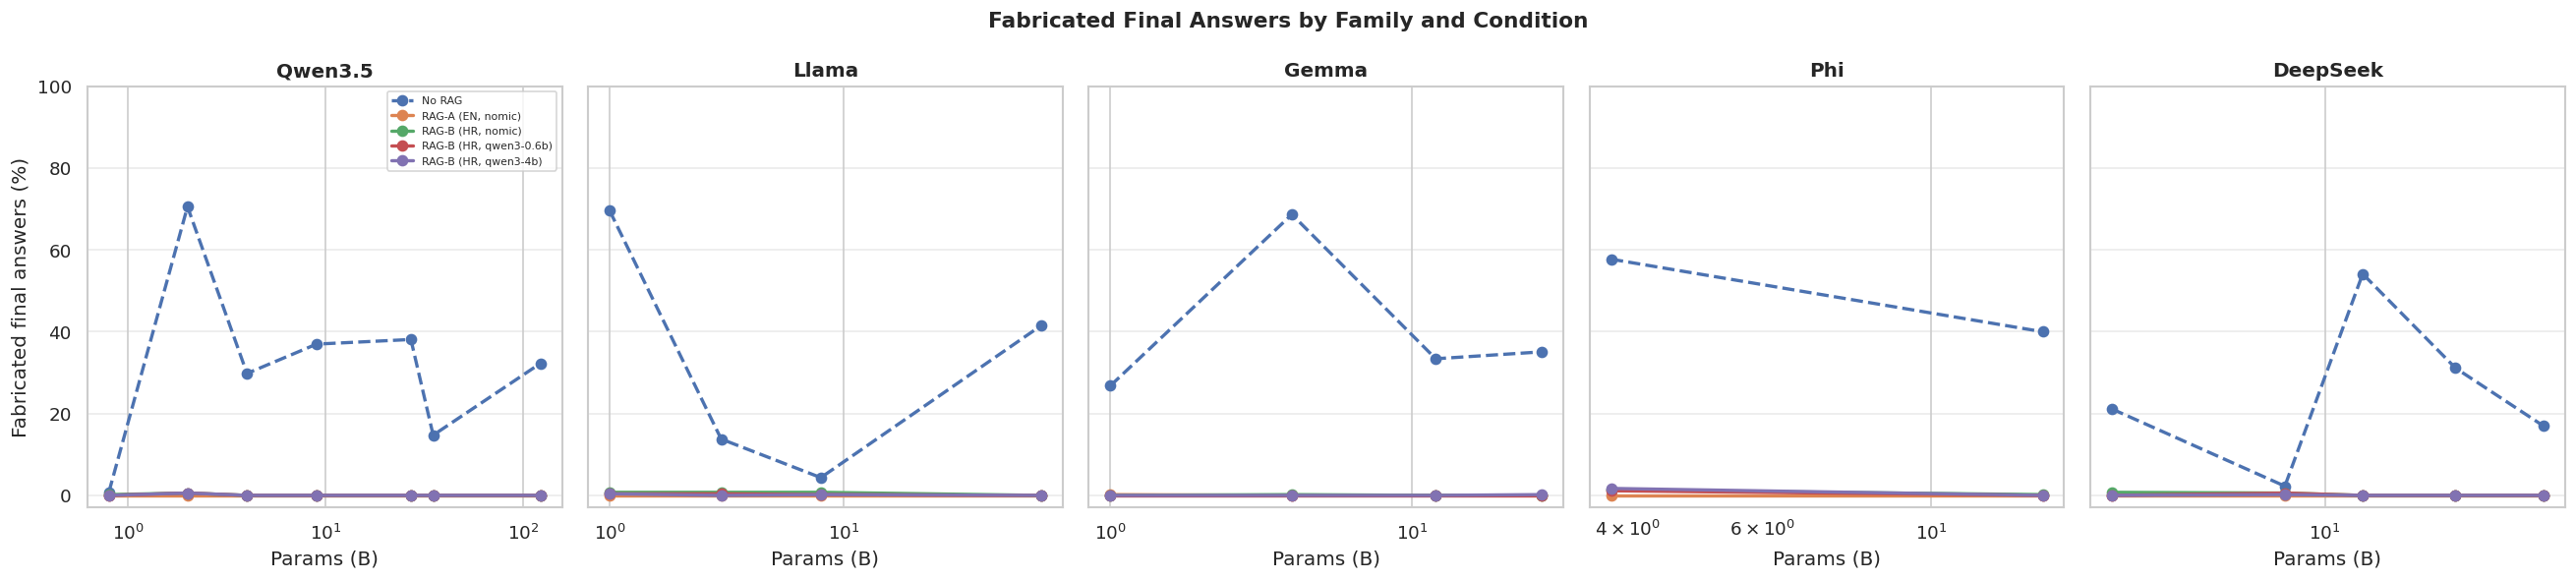

✓ fig2_fabrication.png / .pdf
Oznake y-osi: ['−10', '0', '10', '20', '30', '40', '50', '60', '−8', '−6', '−4', '−2', '0', '2', '4', '6']
Pravih minusa: 5


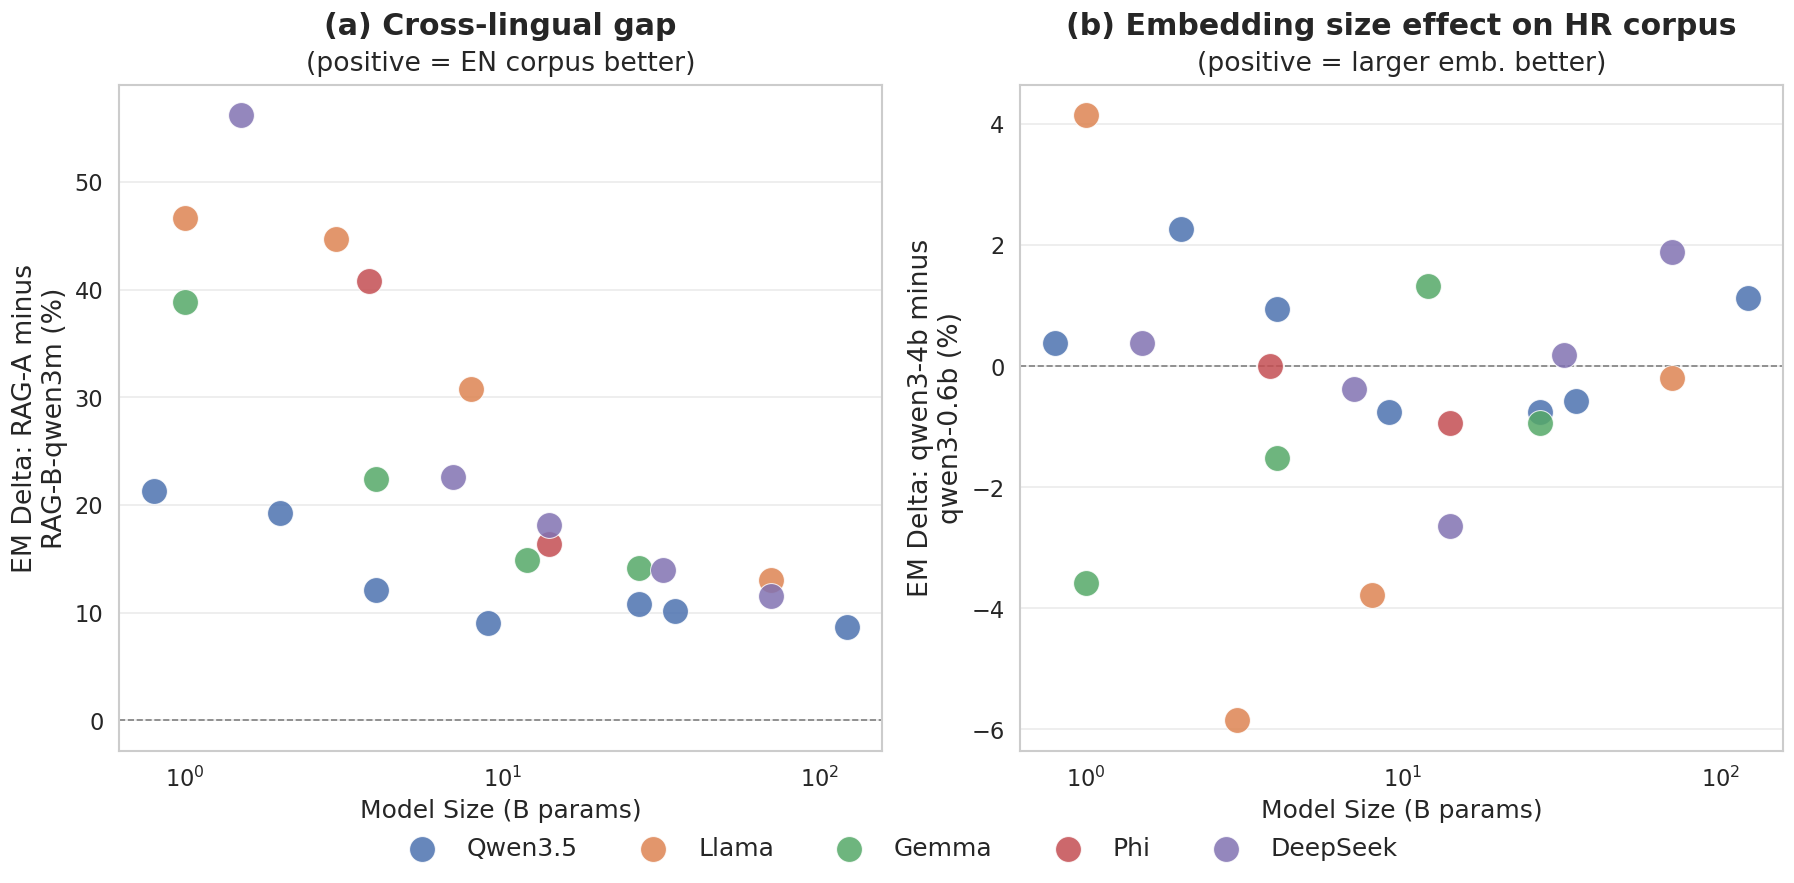

Oznake x-osi: ['−4', '−2', '0', '2', '4', '6', '8', '10']
Pravih minusa (U+2212): 2


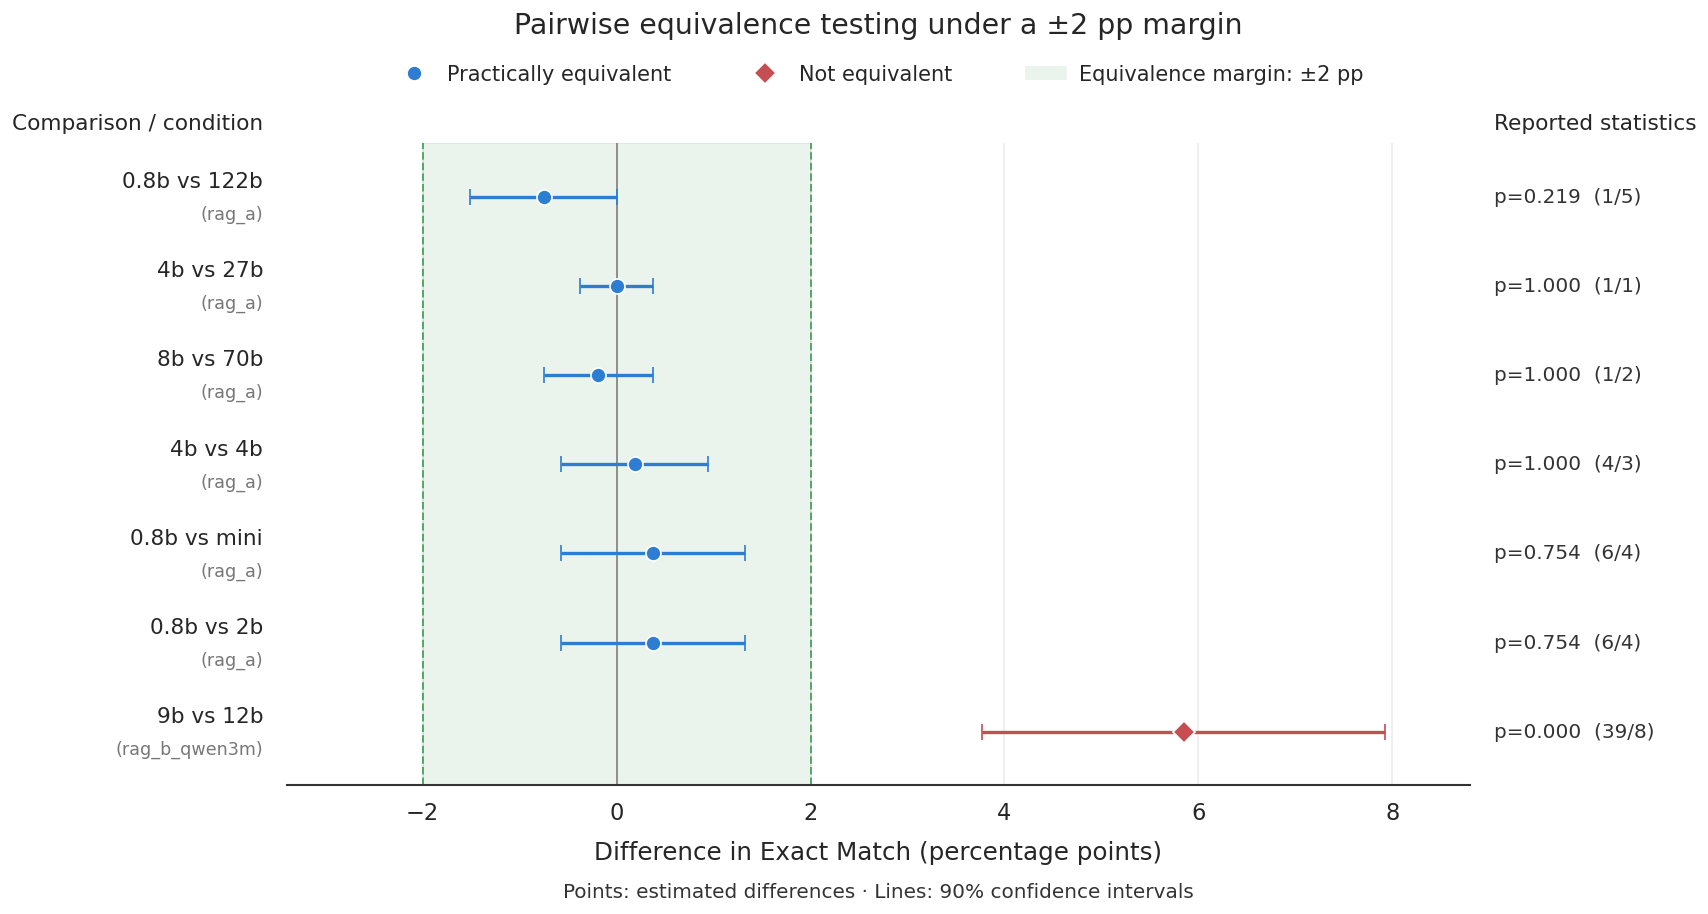

✓ fig6_equivalence.png / .pdf

Oznaka u zagradi uz p-vrijednost je broj nesukladnih parova (b/c).


In [39]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA P — Slika 2 (fabriciranje), Slika 3 (ablacija), Slika 6 (ekvivalentnost)
#
# Slika 2  iz outcome_taxonomy.csv  — prelazi s halucinacije na fabriciranje
# Slika 3  iz strict_em.csv         — ablacija Corpusa B, strogi EM
# Slika 6  iz equivalence_tests.csv — forest plot intervala pouzdanosti
#
# Preduvjet: izvršene ćelije K (strict_df), N (outcome_df), O (pair_df).
# ══════════════════════════════════════════════════════════════════════════════

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="muted")

# ── Učitaj ako nije u memoriji ───────────────────────────────────────────────
if "strict_df" not in dir():
    strict_df = pd.read_csv(f"{RESULTS_DIR}/strict_em.csv")
if "outcome_df" not in dir():
    outcome_df = pd.read_csv(f"{RESULTS_DIR}/outcome_taxonomy.csv")
if "pair_df" not in dir():
    pair_df = pd.read_csv(f"{RESULTS_DIR}/equivalence_tests.csv")

COND_COLORS = {
    "no_rag":       "#4C72B0",
    "rag_a":        "#DD8452",
    "rag_b_nomic":  "#55A868",
    "rag_b_qwen3s": "#C44E52",
    "rag_b_qwen3m": "#8172B2",
}
FAMILY_COLORS = {
    "Qwen3.5":  "#4C72B0", "Llama": "#DD8452", "Gemma": "#55A868",
    "Phi":      "#C44E52", "DeepSeek": "#8172B2",
}


def short_label(m):
    lbl = m.split(":")[-1] if ":" in m else m
    if lbl == "latest":
        lbl = "mini" if "mini" in m else "14b"
    return lbl


# ══════════════════════════════════════════════════════════════════════════════
# SLIKA 2 — Fabricirane konačne šifre po familiji i uvjetu
# ══════════════════════════════════════════════════════════════════════════════
def fab_value(model, cond):
    v = outcome_df[(outcome_df["model"] == model) &
                   (outcome_df["condition"] == cond)]["fabricated"].values
    return v[0] if len(v) else 0.0


fig, axes = plt.subplots(1, len(MODELS), figsize=(22, 5), sharey=True)
fig.suptitle("Fabricated Final Answers by Family and Condition",
             fontsize=13, fontweight="bold")

for ax, (family, family_models) in zip(axes, MODELS.items()):
    params = [MODEL_PARAMS.get(m, 0) for m in family_models]
    for cond in CONDITIONS:
        vals = [fab_value(m, cond) for m in family_models]
        ax.plot(params, vals, marker="o", label=COND_LABELS[cond],
                color=COND_COLORS[cond], linewidth=2, markersize=6,
                linestyle="--" if cond == "no_rag" else "-")
    ax.set_title(family, fontweight="bold")
    ax.set_xlabel("Params (B)")
    ax.set_xscale("log")
    ax.set_ylim(-3, 100)
    ax.yaxis.grid(True, alpha=0.4)

axes[0].set_ylabel("Fabricated final answers (%)")
axes[0].legend(fontsize=6.5)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig2_fabrication.png", bbox_inches="tight", dpi=300)
plt.savefig(f"{FIGURES_DIR}/fig2_fabrication.pdf", bbox_inches="tight")
plt.show()
print("✓ fig2_fabrication.png / .pdf")


# MDPI: negativne oznake na osi moraju koristiti pravi minus (U+2212), ne crticu.
# Oba konteksta vrijede samo unutar bloka i ne mijenjaju globalne postavke.
with sns.plotting_context("notebook", font_scale=1.23), \
     plt.rc_context({"axes.unicode_minus": True}):

    fig, axes = plt.subplots(1, 2, figsize=(15.2, 7.2))

    for ax, col, title, subtitle, ylab in [
        (axes[0], "gap_a_vs_b",
         "(a) Cross-lingual gap", "(positive = EN corpus better)",
         "EM Delta: RAG-A minus\nRAG-B-qwen3m (%)"),
        (axes[1], "emb_effect",
         "(b) Embedding size effect on HR corpus", "(positive = larger emb. better)",
         "EM Delta: qwen3-4b minus\nqwen3-0.6b (%)"),
    ]:
        for fam in MODELS:
            f = abl[abl["family"] == fam]
            ax.scatter(f["params"], f[col], label=fam, s=240,
                       color=FAMILY_COLORS.get(fam, "gray"),
                       alpha=0.85, edgecolors="white", linewidth=0.6, zorder=3)
        ax.axhline(0, color="gray", linestyle="--", linewidth=1)
        ax.set_xscale("log")
        ax.set_xlabel("Model Size (B params)", fontsize=15)
        ax.set_ylabel(ylab, fontsize=16)
        ax.set_title(title, fontweight="bold", fontsize=18, pad=30)
        ax.text(0.5, 1.012, subtitle, transform=ax.transAxes,
                ha="center", va="bottom", fontsize=16)
        ax.yaxis.grid(True, alpha=0.4)
        ax.xaxis.grid(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=15,
               frameon=False, bbox_to_anchor=(0.5, -0.04))
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/fig3_ablation_crosslingual.png",
                bbox_inches="tight", dpi=300)
    plt.savefig(f"{FIGURES_DIR}/fig3_ablation_crosslingual.pdf",
                bbox_inches="tight")

    # kontrola
    fig.canvas.draw()
    _ticks = [t.get_text() for ax in axes for t in ax.get_yticklabels()]
    print("Oznake y-osi:", _ticks)
    print("Pravih minusa:", sum(t.count("\u2212") for t in _ticks))

    plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# SLIKA 6 — Forest plot ekvivalentnosti
# ══════════════════════════════════════════════════════════════════════════════
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

MARGIN   = 2.0
C_EQUIV  = "#2D7DD2"
C_NOT    = "#C44E52"
C_BAND   = "#55A868"

pf = pair_df.copy().iloc[::-1].reset_index(drop=True)   # obrni za čitanje odozgo

# MDPI: negativne oznake na osi moraju koristiti pravi minus (U+2212), ne crticu.
# Oba konteksta vrijede samo unutar bloka i ne mijenjaju globalne postavke.
with sns.plotting_context("notebook", font_scale=1.23), \
     plt.rc_context({"axes.unicode_minus": True}):

    fig, ax = plt.subplots(figsize=(17.0, 8.3))
    fig.subplots_adjust(left=0.21, right=0.79, top=0.83, bottom=0.185)
    y = np.arange(len(pf))
    blend = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)

    # Pojas ekvivalentnosti
    ax.axvspan(-MARGIN, MARGIN, color=C_BAND, alpha=0.12, zorder=1)
    ax.axvline(0, color="gray", linewidth=1, zorder=2)
    for xv in (-MARGIN, MARGIN):
        ax.axvline(xv, color=C_BAND, linestyle="--", linewidth=1.2, zorder=2)

    for i, (_, r) in enumerate(pf.iterrows()):
        equiv  = bool(r["equivalent_at_margin"])
        col    = C_EQUIV if equiv else C_NOT
        marker = "o" if equiv else "D"
        ax.errorbar(r["diff_pp"], i,
                    xerr=[[r["diff_pp"] - r["ci90_lo"]], [r["ci90_hi"] - r["diff_pp"]]],
                    fmt=marker, color=col, ecolor=col, elinewidth=2.0,
                    capsize=5, capthick=2.0, markersize=9,
                    markeredgecolor="white", markeredgewidth=1, zorder=4)
        # lijevi stupac: par modela i uvjet
        ax.text(-0.02, i + 0.17,
                f"{short_label(r['model_a'])} vs {short_label(r['model_b'])}",
                transform=blend, ha="right", va="center", fontsize=13)
        ax.text(-0.02, i - 0.20, f"({r['condition']})",
                transform=blend, ha="right", va="center", fontsize=10.5, color="#777777")
        # desni stupac: statistika
        ax.text(1.02, i,
                f"p={r['mcnemar_p']:.3f}  ({int(r['discordant_b'])}/{int(r['discordant_c'])})",
                transform=blend, ha="left", va="center", fontsize=12, color="#333333")

    ax.set_yticks(y)
    ax.set_yticklabels([])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(pf) - 0.4)

    ax.set_xlim(-3.4, 8.8)
    ax.set_xlabel("Difference in Exact Match (percentage points)", labelpad=10)
    ax.xaxis.grid(True, alpha=0.35)
    ax.yaxis.grid(False)
    for s in ("left", "top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#333333")

    # naslovi stupaca
    ax.text(-0.02, 1.015, "Comparison / condition", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=13)
    ax.text(1.02, 1.015, "Reported statistics", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=13)

    # naslov i legenda
    fig.suptitle("Pairwise equivalence testing under a ±2 pp margin",
                 fontsize=17, y=0.962)
    handles = [
        Line2D([], [], marker="o", color=C_EQUIV, linestyle="none",
               markersize=9, markeredgecolor="white", label="Practically equivalent"),
        Line2D([], [], marker="D", color=C_NOT, linestyle="none",
               markersize=9, markeredgecolor="white", label="Not equivalent"),
        Patch(facecolor=C_BAND, alpha=0.12, label="Equivalence margin: ±2 pp"),
    ]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.928),
               ncol=3, frameon=False, fontsize=12.5, handletextpad=0.6,
               columnspacing=3.5)

    fig.text(0.5, 0.072,
             "Points: estimated differences · Lines: 90% confidence intervals",
             ha="center", fontsize=12, color="#333333")

    plt.savefig(f"{FIGURES_DIR}/fig6_equivalence.png", bbox_inches="tight", dpi=300)
    plt.savefig(f"{FIGURES_DIR}/fig6_equivalence.pdf", bbox_inches="tight")

    # kontrola
    fig.canvas.draw()
    _ticks = [t.get_text() for t in ax.get_xticklabels()]
    print("Oznake x-osi:", _ticks)
    print("Pravih minusa (U+2212):", sum(t.count("\u2212") for t in _ticks))

    plt.show()

print("✓ fig6_equivalence.png / .pdf")
print("\nOznaka u zagradi uz p-vrijednost je broj nesukladnih parova (b/c).")

In [37]:
import json
from pathlib import Path

KEYS = ["Reported statistics", "Comparison / condition",
        "Practically equivalent", "Equivalence margin"]

for root in (Path("."), Path.home()):
    for p in sorted(root.rglob("*.ipynb")):
        if ".ipynb_checkpoints" in str(p):
            continue
        try:
            nb = json.loads(p.read_text(encoding="utf-8", errors="replace"))
        except Exception:
            continue
        for i, c in enumerate(nb.get("cells", [])):
            src = "".join(c.get("source", []))
            found = [k for k in KEYS if k in src]
            if found:
                print(f"{p}  [ćelija {i}]  -> {found}")
    print(f"--- pretraženo: {root} ---")

--- pretraženo: . ---
--- pretraženo: /root ---


In [32]:
import json
from collections import defaultdict

with open("data/test_set.json", encoding="utf-8") as f:
    ts = json.load(f)

by_acc = defaultdict(list)
for q in ts:
    if q.get("q_type") != "lookup":
        continue
    a = q.get("answer")
    if isinstance(a, dict):
        by_acc[str(a.get("account_number", "")).strip()].append(q["question"])

dupes = {k: v for k, v in by_acc.items() if len(v) > 1}
print(f"Konta s više od jednog lookup pitanja: {len(dupes)}\n")
for acc, qs in sorted(dupes.items()):
    identical = len(set(qs)) == 1
    print(f"Konto {acc}  ({'isti tekst' if identical else 'različit tekst'})")
    for q in qs:
        print(f"   {q[:95]}")
    print()

texts = [q["question"] for q in ts if q.get("q_type") == "lookup"]
print(f"Lookup pitanja: {len(texts)},  jedinstvenih tekstova: {len(set(texts))}")

Konta s više od jednog lookup pitanja: 8

Konto 109  (različit tekst)
   What is the account code for Value adjustment of bank deposits Vrijednosno usklađenje depozita 
   What is the account code for and acc.?

Konto 500  (različit tekst)
   What is the account code for Operation I Pogon I?
   What is the account code for Material used in management and administrative overheads Materijal

Konto 501  (različit tekst)
   What is the account code for Operation II Pogon II?
   What is the account code for Wages and other costs of administration Plaće u troškovima uprave 

Konto 502  (različit tekst)
   What is the account code for Operation III Pogon III...?
   What is the account code for Depreciation used in management and administrative overheads Amort

Konto 505  (različit tekst)
   What is the account code for Direct production costs of goods (services)- working order Izravni
   What is the account code for Other costs related to the administration and selling Drugi troško

Konto 510

In [33]:
import json, re
with open("data/test_set.json", encoding="utf-8") as f:
    ts = json.load(f)

suspicious = []
for q in ts:
    if q.get("q_type") != "lookup":
        continue
    m = re.search(r"account code for (.+?)\?*$", q["question"])
    if not m:
        continue
    name = m.group(1).strip()
    if len(name) < 12 or name.lower().startswith(("and ", "etc", "itd")):
        suspicious.append((name, q["answer"].get("account_number")))

print(f"Sumnjivih lookup pitanja: {len(suspicious)}")
for n, a in suspicious:
    print(f"  {a}  →  {n!r}")

Sumnjivih lookup pitanja: 2
  109  →  'and acc.'
  512  →  'etc. Itd.'


In [34]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA Q — Jedinstveni izvor istine za sve brojke u tekstu
#
# Izračunava svaku tvrdnju koja se u radu navodi brojčano, iz konačnih podataka.
# Ispis je oblikovan tako da se može izravno usporediti s tekstom.
#
# Preduvjet: ćelija K (strict_df). Semantic similarity iz df.
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd

if "strict_df" not in dir():
    strict_df = pd.read_csv(f"{RESULTS_DIR}/strict_em.csv")

piv = strict_df.pivot_table(index="model", columns="condition",
                            values="em_strict", aggfunc="first")

print("=" * 78)
print("EXACT MATCH (strogi) — provjera svih tvrdnji iz teksta")
print("=" * 78)

for cond in CONDITIONS:
    if cond not in piv.columns:
        continue
    col = piv[cond]
    print(f"\n{cond}")
    print(f"  prosjek {col.mean():6.2f}   min {col.min():6.2f} ({col.idxmin()})"
          f"   max {col.max():6.2f} ({col.idxmax()})")

print("\n" + "-" * 78)
print("PROSJEČNE RAZLIKE MEĐU UVJETIMA")
print("-" * 78)
pairs = [("rag_b_qwen3s", "rag_b_nomic"), ("rag_b_qwen3m", "rag_b_qwen3s"),
         ("rag_b_qwen3m", "rag_b_nomic"), ("rag_a", "rag_b_qwen3m")]
for a, b in pairs:
    if a in piv.columns and b in piv.columns:
        d = (piv[a] - piv[b]).mean()
        sign = "porast" if d > 0 else "PAD"
        print(f"  {a} − {b:14s} : {d:+6.2f} pp   ({sign})")
        n_up = int((piv[a] > piv[b]).sum())
        print(f"      modela s porastom: {n_up}/22,  s padom: {22 - n_up}/22")

print("\n" + "-" * 78)
print("BROJANJE MODELA PO PRAGOVIMA POD RAG-A")
print("-" * 78)
ra = piv["rag_a"]
for thr in (92.0, 93.0, 94.0, 94.9, 95.0, 96.0, 97.0):
    n = int((ra > thr).sum())
    print(f"  > {thr:5.1f}% : {n:2d} modela")
print(f"\n  Raspon: {ra.min():.2f} – {ra.max():.2f}")
print(f"  Ispod 95.0%: {sorted(ra[ra <= 95.0].round(2).items(), key=lambda x: x[1])}")

print("\n" + "=" * 78)
print("SEMANTIC SIMILARITY — provjera smjera")
print("=" * 78)

sim = df.pivot_table(index="model", columns="condition",
                     values="sem_sim_desc", aggfunc="first")

for cond in CONDITIONS:
    if cond in sim.columns:
        print(f"  {cond:14s} prosjek {sim[cond].mean():.4f}")

print("\nUsporedba RAG-B uvjeta po modelu:")
n_nomic_higher_s = int((sim["rag_b_nomic"] > sim["rag_b_qwen3s"]).sum())
n_nomic_higher_m = int((sim["rag_b_nomic"] > sim["rag_b_qwen3m"]).sum())
print(f"  nomic > qwen3s : {n_nomic_higher_s}/22 modela")
print(f"  nomic > qwen3m : {n_nomic_higher_m}/22 modela")

print("\nUsporedba s No-RAG baseline:")
for cond in ["rag_a", "rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"]:
    if cond not in sim.columns:
        continue
    n_above = int((sim[cond] > sim["no_rag"]).sum())
    print(f"  {cond:14s} iznad baseline: {n_above:2d}/22 modela")

print("\n" + "!" * 78)
print("PROVJERA TVRDNJI IZ SECTION 6.6 I CAPTIONA SLIKE 4")
print("!" * 78)
claim_recovery = sim["rag_b_qwen3s"].mean() > sim["rag_b_nomic"].mean()
print(f"  'nomic najniži, oporavak pod multilingvalnima' : "
      f"{'TOČNO' if claim_recovery else 'NETOČNO'}")
all_above = all(int((sim[c] > sim["no_rag"]).sum()) == 22
                for c in ["rag_a", "rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"]
                if c in sim.columns)
print(f"  'svi RAG uvjeti iznad No-RAG baseline'          : "
      f"{'TOČNO' if all_above else 'NETOČNO'}")

out = pd.concat([piv.add_prefix("em_"), sim.add_prefix("sim_")], axis=1)
out.to_csv(f"{RESULTS_DIR}/final_numbers.csv")
print(f"\n✓ Saved: {RESULTS_DIR}/final_numbers.csv")

EXACT MATCH (strogi) — provjera svih tvrdnji iz teksta

no_rag
  prosjek   0.19   min   0.00 (deepseek-r1:1.5b)   max   0.75 (deepseek-r1:70b)

rag_a
  prosjek  94.20   min  78.30 (llama3.2:1b)   max  96.23 (deepseek-r1:32b)

rag_b_nomic
  prosjek  28.72   min  11.89 (gemma3:1b)   max  40.57 (qwen3.5:122b)

rag_b_qwen3s
  prosjek  72.06   min  27.55 (llama3.2:1b)   max  87.55 (qwen3.5:9b)

rag_b_qwen3m
  prosjek  71.64   min  31.70 (llama3.2:1b)   max  87.36 (qwen3.5:122b)

------------------------------------------------------------------------------
PROSJEČNE RAZLIKE MEĐU UVJETIMA
------------------------------------------------------------------------------
  rag_b_qwen3s − rag_b_nomic    : +43.34 pp   (porast)
      modela s porastom: 22/22,  s padom: 0/22
  rag_b_qwen3m − rag_b_qwen3s   :  -0.42 pp   (PAD)
      modela s porastom: 9/22,  s padom: 13/22
  rag_b_qwen3m − rag_b_nomic    : +42.92 pp   (porast)
      modela s porastom: 22/22,  s padom: 0/22
  rag_a − rag_b_qwen3m   : +

In [35]:
# ══════════════════════════════════════════════════════════════════════════════
# ĆELIJA R — Usklađivanje Fabrication i Context Adherence
#
# Za ISTE odgovore usporeduje: izdvojeni konacni konto, clanstvo u registru,
# i prisutnost u dohvacenom kontekstu. Utvrduje zasto 37.9% fabriciranih i
# 98.8% grounded ne stoje zajedno.
#
# Radi iz postojecih checkpointa — NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd
from collections import Counter

ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")


def extract_final(response):
    all_found = ANY_RE.findall(response or "")
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(response or "")
        if m:
            return m.group(1), all_found
    return (all_found[0] if all_found else None), all_found


# ── Provjera 1: je li kontekst podskup registra? ─────────────────────────────
with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", encoding="utf-8") as f:
    _cb = json.load(f)

CORPUS_B_VISIBLE = {}
context_numbers_all = set()
for doc in _cb:
    k = str(doc["kljuc"]).strip()
    vis = set(ANY_RE.findall(doc["text"]))
    vis.add(k)
    CORPUS_B_VISIBLE[k] = vis
    context_numbers_all |= vis

spurious = context_numbers_all - VALID_ACCOUNTS
print("PROVJERA 1 — je li kontekst podskup registra valjanih konta?")
print(f"  Brojeva izvucenih iz teksta Corpusa B : {len(context_numbers_all)}")
print(f"  Od toga NIJE u VALID_ACCOUNTS         : {len(spurious)}")
if spurious:
    print(f"  Primjeri: {sorted(spurious)[:25]}")
    print("  → kontekst NIJE podskup registra; odgovor moze biti")
    print("    istodobno grounded i fabricated.")
else:
    print("  → kontekst JEST podskup registra; uzrok je drugdje.")

# gdje se pojavljuju
if spurious:
    hits = Counter()
    for doc in _cb:
        for n in ANY_RE.findall(doc["text"]):
            if n in spurious:
                hits[n] += 1
    print("\n  Najcesci nevaljani brojevi u tekstu dokumenata:")
    for n, c in hits.most_common(10):
        ex = next(d["text"] for d in _cb if n in ANY_RE.findall(d["text"]))
        snippet = ex.replace("\n", " | ")[:110]
        print(f"    {n}  x{c:4d}   …{snippet}")

CORPUS_B_CONDS = {"rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"}


def visible_accounts(retrieved_ids, condition):
    vis = set()
    for rid in retrieved_ids:
        rid = str(rid).strip()
        if not rid:
            continue
        if condition in CORPUS_B_CONDS:
            vis |= CORPUS_B_VISIBLE.get(rid, {rid})
        else:
            vis.add(rid)
    return vis


# ── Provjera 2: unakrsna tablica za iste odgovore ───────────────────────────
print("\n" + "=" * 78)
print("PROVJERA 2 — unakrsna tablica na istim odgovorima")
print("=" * 78)

rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond == "no_rag" or cond not in all_results.get(model, {}):
            continue
        n = 0
        c = Counter()
        for r in all_results[model][cond]:
            if r.get("q_type") != "lookup":
                continue
            n += 1
            resp = r.get("response", "")
            proposed, all_found = extract_final(resp)
            ctx = visible_accounts(r.get("retrieved_ids", []), cond)

            if proposed is None:
                c["no_code"] += 1
                continue

            in_reg = proposed in VALID_ACCOUNTS
            in_ctx = proposed in ctx
            c[f"reg{int(in_reg)}_ctx{int(in_ctx)}"] += 1
            # grounded prema definiciji Context Adherence
            if all_found and not (set(all_found) - ctx):
                c["grounded"] += 1

        rows.append({
            "model": model, "condition": cond, "n": n,
            "no_code_pct":        round(c["no_code"] / n * 100, 2),
            "valid_in_ctx":       round(c["reg1_ctx1"] / n * 100, 2),
            "valid_not_in_ctx":   round(c["reg1_ctx0"] / n * 100, 2),
            "invalid_in_ctx":     round(c["reg0_ctx1"] / n * 100, 2),
            "invalid_not_in_ctx": round(c["reg0_ctx0"] / n * 100, 2),
            "grounded_all":       round(c["grounded"] / n * 100, 2),
        })

xdf = pd.DataFrame(rows)
cols = ["no_code_pct", "valid_in_ctx", "valid_not_in_ctx",
        "invalid_in_ctx", "invalid_not_in_ctx", "grounded_all"]
summ = xdf.groupby("condition")[cols].mean().round(2)
summ = summ.reindex([c for c in CONDITIONS if c in summ.index])
print(summ.to_string())
print()
print("  valid_in_ctx       konacni konto valjan I u kontekstu")
print("  invalid_in_ctx     konacni konto NIJE u registru ali JEST u kontekstu")
print("                     ← ovo objasnjava istodobno grounded i fabricated")
print("  grounded_all       udio SVIH odgovora kod kojih su sve šifre u kontekstu")
print("                     (nazivnik = svi odgovori, ne samo oni sa šifrom)")

xdf.to_csv(f"{RESULTS_DIR}/metric_reconciliation.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/metric_reconciliation.csv")

# ── Provjera 3: primjeri spornih slucajeva ──────────────────────────────────
print("\n" + "=" * 78)
print("PROVJERA 3 — primjeri: fabricated ALI grounded (rag_b_nomic)")
print("=" * 78)

shown = 0
for model in ALL_MODELS:
    if "rag_b_nomic" not in all_results.get(model, {}):
        continue
    for r in all_results[model]["rag_b_nomic"]:
        if r.get("q_type") != "lookup":
            continue
        resp = r.get("response", "")
        proposed, all_found = extract_final(resp)
        if proposed is None:
            continue
        ctx = visible_accounts(r.get("retrieved_ids", []), "rag_b_nomic")
        if proposed not in VALID_ACCOUNTS and proposed in ctx:
            print(f"\n[{model}]  predlozeno={proposed}")
            print(f"  Q: {r.get('question','')[:78]}")
            print(f"  A: {resp[:150]}")
            print(f"  u registru: NE    u kontekstu: DA")
            print(f"  dohvaceni kljucevi: {r.get('retrieved_ids', [])}")
            shown += 1
            break
    if shown >= 5:
        break
print(f"\n(prikazano {shown})")

# ── Provjera 4: vodece nule ─────────────────────────────────────────────────
print("\n" + "=" * 78)
print("PROVJERA 4 — vodece nule i format registra")
print("=" * 78)
lead = [a for a in VALID_ACCOUNTS if a.startswith("0")]
print(f"  Konta u registru s vodecom nulom: {len(lead)}   primjeri: {sorted(lead)[:8]}")
print(f"  Duljine zapisa u registru: {Counter(len(a) for a in VALID_ACCOUNTS)}")

PROVJERA 1 — je li kontekst podskup registra valjanih konta?
  Brojeva izvucenih iz teksta Corpusa B : 2467
  Od toga NIJE u VALID_ACCOUNTS         : 5
  Primjeri: ['2004', '2005', '2018', '2023', '390']
  → kontekst NIJE podskup registra; odgovor moze biti
    istodobno grounded i fabricated.

  Najcesci nevaljani brojevi u tekstu dokumenata:
    2018  x   2   …Konto: 0396 | Naziv: Akumulirana amortiz. 50% i 100% pretporeza od osob. automobila (n. v. veće od 400.000,00 
    2023  x   2   …Konto: 1411 | Naziv: Potraživanja za prirez iz plaća (do 31. 12. 2023.) | Razina: analiticki | Sintetički: 141
    2004  x   2   …Konto: 9301 | Naziv: Revalorizacijske pričuve iz razdoblja od 2001. do 2004. | Razina: analiticki | Sintetički
    390  x   1   …Konto: 9204 | Naziv: Pričuve u j.d.o.o. za povećanje t.k. (čl. 390. a) ZTD-a) | Razina: analiticki | Sintetičk
    2005  x   1   …Konto: 9402 | Naziv: Zadržani dobitak iz 2005. do 2011. | Razina: analiticki | Sintetički: 940 — Zadržani dobi

PROV

In [36]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA S — ISPRAVAK: registar valjanih konta + ponovni izracun klasifikacije
#
# Provjera R pokazala je da VALID_ACCOUNTS u ovom notebooku sadrzi samo 522
# troznamenkasta konta iz accounts.jsonl. Prosirenje na konta Corpusa B nikada
# nije usla u notebook 05. Posljedica: sva cetveroznamenkasta i peteroznamenkasta
# konta iz RRiF plana bila su oznacena kao fabricirana.
#
# Ova celija ispravlja registar i ponovno racuna klasifikaciju ishoda.
# Pokreni PRIJE celija N i R, ili umjesto izvorne celije koja gradi VALID_ACCOUNTS.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd
from collections import Counter

# ── 1. Ispravan registar ────────────────────────────────────────────────────
with open("accounts.jsonl", encoding="utf-8") as f:
    _raw = [json.loads(l) for l in f if l.strip()]

VALID_ACCOUNTS = set()
for d in _raw:
    a = json.loads(next(c for c in d["conversations"]
                        if c["role"] == "assistant")["content"])
    acc = str(a.get("account_number", "")).strip()
    if acc:
        VALID_ACCOUNTS.add(acc)
n_jsonl = len(VALID_ACCOUNTS)

with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", encoding="utf-8") as f:
    _corpus_b = json.load(f)

for doc in _corpus_b:
    k = str(doc["kljuc"]).strip()
    if k:
        VALID_ACCOUNTS.add(k)

VALID_ACCOUNTS.discard("")

print("ISPRAVLJENI REGISTAR")
print(f"  iz accounts.jsonl        : {n_jsonl}")
print(f"  iz Corpusa B             : {len(_corpus_b)}")
print(f"  ukupno jedinstvenih      : {len(VALID_ACCOUNTS)}")
print(f"  duljine zapisa           : {dict(Counter(len(a) for a in VALID_ACCOUNTS))}")
assert len(VALID_ACCOUNTS) > 2000, "Registar i dalje nije prosiren!"

# ── 2. Ponovni izracun klasifikacije ishoda ─────────────────────────────────
ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")

REFUSAL_RE = re.compile("|".join([
    r"\bno (?:information|account|code|entry|match|data)\b",
    r"\bnot (?:present|found|listed|available|included|specified)\b",
    r"\bcannot (?:be )?(?:find|found|determine|identif)",
    r"\bdoes not (?:contain|include|list|appear|specify)\b",
    r"\bis not (?:in|present|listed|available)\b",
    r"\bunable to\b", r"\bthere is no\b", r"\bno such\b",
]), re.IGNORECASE)


def extract_final(response):
    all_found = ANY_RE.findall(response or "")
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(response or "")
        if m:
            return m.group(1), all_found
    return (all_found[0] if all_found else None), all_found


def classify(response, expected):
    text = (response or "").strip()
    if not text:
        return "invalid_empty", False
    proposed, all_found = extract_final(text)
    mentions_invalid = any(n not in VALID_ACCOUNTS for n in all_found)
    if proposed is None:
        return ("abstention" if REFUSAL_RE.search(text) else "invalid_no_code"), False
    if proposed == expected:
        return "correct", mentions_invalid
    if proposed in VALID_ACCOUNTS:
        return "wrong_existing", mentions_invalid
    return "fabricated", True


CATEGORIES = ["correct", "wrong_existing", "fabricated",
              "abstention", "invalid_no_code", "invalid_empty"]


def outcome_profile(results):
    counts = {c: 0 for c in CATEGORIES}
    invalid_mentions = []
    n = 0
    for r in results:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue
        cat, has_inv = classify(r.get("response", ""), expected)
        counts[cat] += 1
        invalid_mentions.append(1 if has_inv else 0)
        n += 1
    if n == 0:
        return None
    out = {c: round(counts[c] / n * 100, 2) for c in CATEGORIES}
    out["any_invalid_mention"] = round(np.mean(invalid_mentions) * 100, 2)
    out["n"] = n
    return out


rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond not in all_results.get(model, {}):
            continue
        p = outcome_profile(all_results[model][cond])
        if p is None:
            continue
        p["model"], p["condition"] = model, cond
        p["family"] = next((f for f, ms in MODELS.items() if model in ms), "?")
        rows.append(p)

outcome_df = pd.DataFrame(rows)

print("\n" + "=" * 78)
print("ISPRAVLJENA KLASIFIKACIJA ISHODA (%)")
print("=" * 78)
summary = outcome_df.groupby("condition")[CATEGORIES + ["any_invalid_mention"]].mean().round(2)
summary = summary.reindex([c for c in CONDITIONS if c in summary.index])
print(summary.to_string())
print("\nZbroj kategorija (mora biti 100):")
print(summary[CATEGORIES].sum(axis=1).round(2).to_string())

print("\n=== Fabricirane konacne sifre po modelu (%) ===")
piv_fab = outcome_df.pivot_table(index=["family", "model"], columns="condition",
                                  values="fabricated", aggfunc="first")
piv_fab = piv_fab[[c for c in CONDITIONS if c in piv_fab.columns]]
print(piv_fab.round(2).to_string())

print("\n=== Suzdrzavanje po modelu (%) ===")
piv_abs = outcome_df.pivot_table(index=["family", "model"], columns="condition",
                                  values="abstention", aggfunc="first")
piv_abs = piv_abs[[c for c in CONDITIONS if c in piv_abs.columns]]
print(piv_abs.round(2).to_string())

outcome_df.to_csv(f"{RESULTS_DIR}/outcome_taxonomy.csv", index=False)
summary.to_csv(f"{RESULTS_DIR}/outcome_taxonomy_summary.csv")
print(f"\n✓ Saved (prepisano): {RESULTS_DIR}/outcome_taxonomy.csv")

print("\n" + "=" * 78)
print("KLJUCNE BROJKE ZA RAD")
print("=" * 78)
for cond in [c for c in CONDITIONS if c in summary.index]:
    r = summary.loc[cond]
    print(f"\n{cond}:")
    for k, lbl in [("correct", "tocan"), ("wrong_existing", "pogresan ali postojeci"),
                   ("fabricated", "nepostojeca sifra"), ("abstention", "suzdrzavanje"),
                   ("invalid_no_code", "bez sifre"), ("invalid_empty", "prazno"),
                   ("any_invalid_mention", "izmisljena sifra bilo gdje")]:
        print(f"  {lbl:28s} {r[k]:6.2f}%")


ISPRAVLJENI REGISTAR
  iz accounts.jsonl        : 522
  iz Corpusa B             : 2462
  ukupno jedinstvenih      : 2464
  duljine zapisa           : {3: 529, 4: 1546, 2: 79, 5: 259, 1: 10, 6: 41}

ISPRAVLJENA KLASIFIKACIJA ISHODA (%)
              correct  wrong_existing  fabricated  abstention  invalid_no_code  invalid_empty  any_invalid_mention
condition                                                                                                         
no_rag           0.19           53.52       33.63        0.66            12.00            0.0                34.18
rag_a           94.20            5.05        0.01        0.39             0.34            0.0                 0.01
rag_b_nomic     28.72           46.89        0.27       17.69             6.42            0.0                 0.30
rag_b_qwen3s    72.06           23.84        0.15        1.16             2.80            0.0                 0.19
rag_b_qwen3m    71.64           24.02        0.15        0.76             

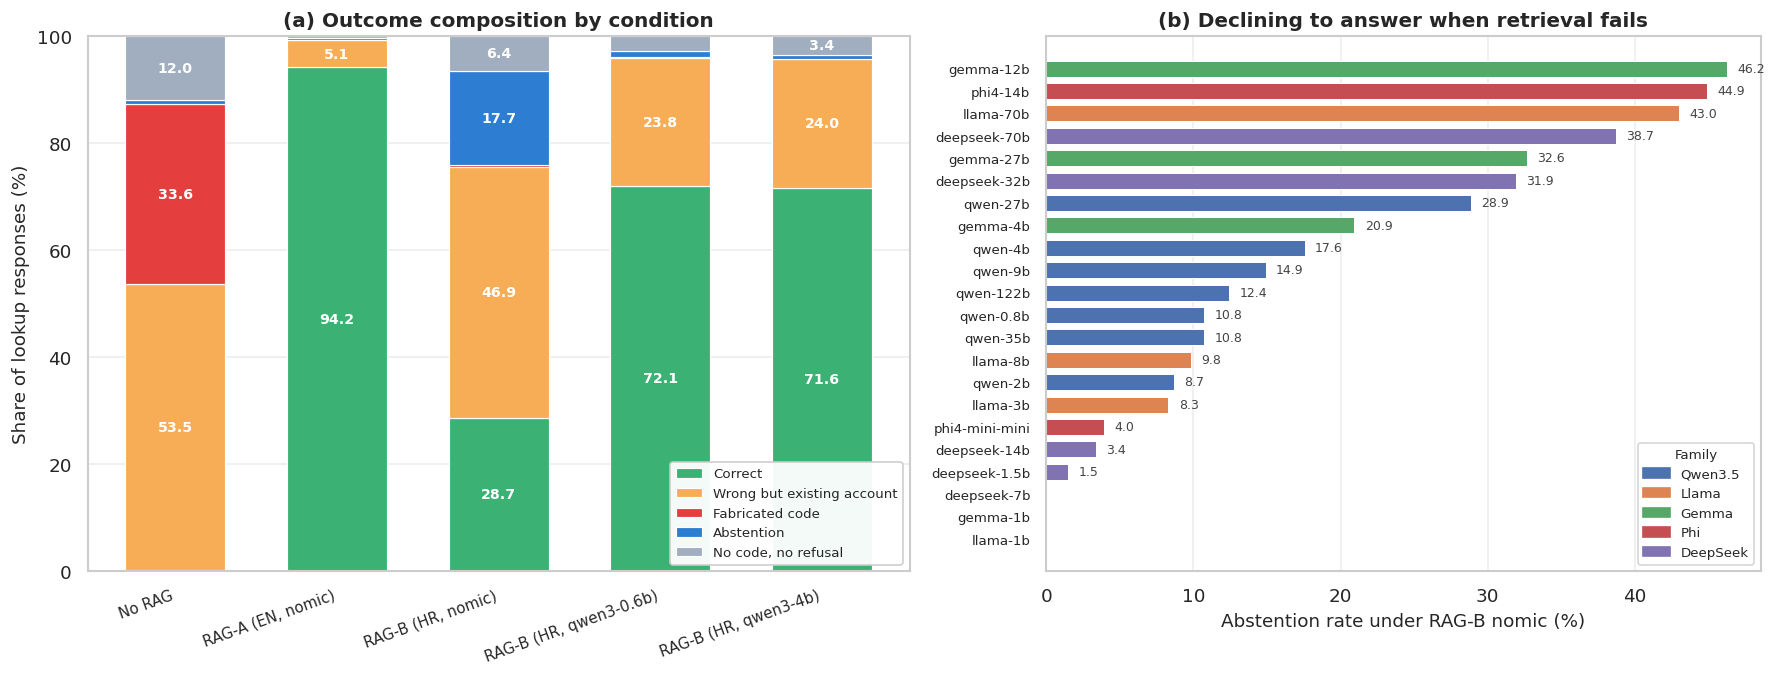

✓ fig2_outcomes.png / .pdf

Provjera udjela za caption:
  no_rag         correct=  0.2  wrong= 53.5  fabr=33.63  abst=  0.7
  rag_a          correct= 94.2  wrong=  5.1  fabr=0.01  abst=  0.4
  rag_b_nomic    correct= 28.7  wrong= 46.9  fabr=0.27  abst= 17.7
  rag_b_qwen3s   correct= 72.1  wrong= 23.8  fabr=0.15  abst=  1.2
  rag_b_qwen3m   correct= 71.6  wrong= 24.0  fabr=0.15  abst=  0.8


In [37]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA T — Slika 2: sastav ishoda po uvjetu (slozeni stupcasti prikaz)
#
# Zamjenjuje raniju Sliku 2 (linijski prikaz halucinacija po familiji), koja
# nakon ispravka registra vise nema sto pokazati — fabriciranje je pod svim
# RAG uvjetima ispod 0.3%.
#
# Panel (a): sastav ishoda po uvjetu, prosjek svih 22 modela
# Panel (b): suzdrzavanje po modelu pod rag_b_nomic, poredano
#
# Preduvjet: celija S (outcome_df s ispravnim registrom).
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="muted")

if "outcome_df" not in dir():
    outcome_df = pd.read_csv(f"{RESULTS_DIR}/outcome_taxonomy.csv")

CATEGORIES = ["correct", "wrong_existing", "fabricated",
              "abstention", "invalid_no_code", "invalid_empty"]

CAT_LABELS = {
    "correct":         "Correct",
    "wrong_existing":  "Wrong but existing account",
    "fabricated":      "Fabricated code",
    "abstention":      "Abstention",
    "invalid_no_code": "No code, no refusal",
    "invalid_empty":   "Empty response",
}

CAT_COLORS = {
    "correct":         "#3BB273",   # zelena
    "wrong_existing":  "#F6AD55",   # narancasta
    "fabricated":      "#E53E3E",   # crvena
    "abstention":      "#2D7DD2",   # plava
    "invalid_no_code": "#A0AEC0",   # siva
    "invalid_empty":   "#4A5568",   # tamnosiva
}

FAMILY_COLORS = {
    "Qwen3.5":  "#4C72B0", "Llama": "#DD8452", "Gemma": "#55A868",
    "Phi":      "#C44E52", "DeepSeek": "#8172B2",
}

summary = outcome_df.groupby("condition")[CATEGORIES].mean()
summary = summary.reindex([c for c in CONDITIONS if c in summary.index])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8),
                         gridspec_kw={"width_ratios": [1.15, 1]})

# ── Panel (a): sastav ishoda ────────────────────────────────────────────────
ax = axes[0]
x = np.arange(len(summary))
bottom = np.zeros(len(summary))

for cat in CATEGORIES:
    vals = summary[cat].values
    if vals.sum() < 0.05:          # preskoci kategorije bez ijednog udjela
        continue
    ax.bar(x, vals, 0.62, bottom=bottom,
           label=CAT_LABELS[cat], color=CAT_COLORS[cat],
           edgecolor="white", linewidth=0.7)
    # oznaci udjele iznad 3 %
    for xi, (v, b) in enumerate(zip(vals, bottom)):
        if v >= 3.0:
            ax.text(xi, b + v / 2, f"{v:.1f}", ha="center", va="center",
                    fontsize=8.5, color="white", fontweight="bold")
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels([COND_LABELS[c] for c in summary.index],
                   rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Share of lookup responses (%)", fontsize=11)
ax.set_ylim(0, 100)
ax.set_title("(a) Outcome composition by condition",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=8, loc="lower right", framealpha=0.95)
ax.yaxis.grid(True, alpha=0.35)
ax.xaxis.grid(False)

# ── Panel (b): suzdrzavanje pod rag_b_nomic ─────────────────────────────────
ax = axes[1]
abst = outcome_df[outcome_df["condition"] == "rag_b_nomic"][
    ["model", "family", "abstention"]].sort_values("abstention")


def short(m):
    lbl = m.split(":")[-1] if ":" in m else m
    if lbl == "latest":
        lbl = "mini" if "mini" in m else "14b"
    fam = m.split(":")[0].replace("3.5", "").replace("3.2", "").replace("3.1", "")
    fam = fam.replace("3.3", "").replace("-r1", "").replace("3", "")
    return f"{fam}-{lbl}"


y = np.arange(len(abst))
colors = [FAMILY_COLORS.get(f, "gray") for f in abst["family"]]
ax.barh(y, abst["abstention"].values, 0.72, color=colors,
        edgecolor="white", linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels([short(m) for m in abst["model"]], fontsize=8)
ax.set_xlabel("Abstention rate under RAG-B nomic (%)", fontsize=11)
ax.set_title("(b) Declining to answer when retrieval fails",
             fontsize=12, fontweight="bold")
ax.xaxis.grid(True, alpha=0.35)
ax.yaxis.grid(False)

for xi, v in enumerate(abst["abstention"].values):
    if v >= 1.0:
        ax.text(v + 0.7, xi, f"{v:.1f}", va="center", fontsize=7.5,
                color="#444444")

handles = [plt.Rectangle((0, 0), 1, 1, color=FAMILY_COLORS[f])
           for f in MODELS if f in FAMILY_COLORS]
ax.legend(handles, list(MODELS.keys()), fontsize=8,
          loc="lower right", title="Family", title_fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/fig2_outcomes.png", bbox_inches="tight", dpi=300)
plt.savefig(f"{FIGURES_DIR}/fig2_outcomes.pdf", bbox_inches="tight")
plt.show()
print("✓ fig2_outcomes.png / .pdf")

print("\nProvjera udjela za caption:")
for c in summary.index:
    r = summary.loc[c]
    print(f"  {c:14s} correct={r['correct']:5.1f}  wrong={r['wrong_existing']:5.1f}  "
          f"fabr={r['fabricated']:4.2f}  abst={r['abstention']:5.1f}")

In [38]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA U — Razdvajanje pogresaka dohvacanja od pogresaka odabira
#
# Rad tvrdi da su preostale pogreske pod RAG-om problem dohvacanja, a ne
# generiranja. Context Adherence to ne dokazuje: ona pokazuje da model ostaje
# unutar konteksta, ne i da iz njega ispravno bira.
#
# Ova celija za svaki netocan odgovor utvrduje je li tocan konto bio dostupan
# u dohvacenom kontekstu — ukljucujuci roditeljske oznake u tekstu dokumenata.
#
# Radi iz postojecih checkpointa — NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import numpy as np
import pandas as pd

ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")

with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", encoding="utf-8") as f:
    _cb = json.load(f)

CORPUS_B_VISIBLE = {}
for doc in _cb:
    k = str(doc["kljuc"]).strip()
    vis = set(ANY_RE.findall(doc["text"]))
    vis.add(k)
    CORPUS_B_VISIBLE[k] = vis

CORPUS_B_CONDS = {"rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"}


def visible_accounts(retrieved_ids, condition):
    """Sva konta koja model stvarno vidi, ukljucujuci roditelje u tekstu."""
    vis = set()
    for rid in retrieved_ids:
        rid = str(rid).strip()
        if not rid:
            continue
        if condition in CORPUS_B_CONDS:
            vis |= CORPUS_B_VISIBLE.get(rid, {rid})
        else:
            vis.add(rid)
    return vis


def extract_final(response):
    all_found = ANY_RE.findall(response or "")
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(response or "")
        if m:
            return m.group(1)
    return all_found[0] if all_found else None


def failure_profile(results, condition):
    """
    Cetiri medusobno iskljucive kategorije po lookup pitanju:
      available_correct    tocan konto dostupan, model ga naveo
      selection_failure    tocan konto DOSTUPAN, model naveo nesto drugo
      retrieval_failure    tocan konto NIJE dostupan, odgovor netocan
      recovered            tocan konto nije dostupan, a model ga ipak naveo
    """
    c = {"available_correct": 0, "selection_failure": 0,
         "retrieval_failure": 0, "recovered": 0}
    n = 0
    for r in results:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue
        n += 1

        ctx       = visible_accounts(r.get("retrieved_ids", []), condition)
        proposed  = extract_final(r.get("response", ""))
        available = expected in ctx
        correct   = proposed == expected

        if available and correct:
            c["available_correct"] += 1
        elif available and not correct:
            c["selection_failure"] += 1
        elif not available and correct:
            c["recovered"] += 1
        else:
            c["retrieval_failure"] += 1

    if n == 0:
        return None
    out = {k: round(v / n * 100, 2) for k, v in c.items()}
    out["availability"] = round((c["available_correct"] + c["selection_failure"]) / n * 100, 2)
    total_err = c["selection_failure"] + c["retrieval_failure"]
    out["selection_share_of_errors"] = (
        round(c["selection_failure"] / total_err * 100, 1) if total_err else None
    )
    out["n"] = n
    return out


rows = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        if cond == "no_rag" or cond not in all_results.get(model, {}):
            continue
        p = failure_profile(all_results[model][cond], cond)
        if p is None:
            continue
        p["model"], p["condition"] = model, cond
        p["family"] = next((f for f, ms in MODELS.items() if model in ms), "?")
        rows.append(p)

fail_df = pd.DataFrame(rows)

cols = ["availability", "available_correct", "selection_failure",
        "retrieval_failure", "recovered", "selection_share_of_errors"]

print("=" * 80)
print("RAZDVAJANJE POGRESAKA — prosjek svih 22 modela (%)")
print("=" * 80)
summary = fail_df.groupby("condition")[cols].mean().round(2)
summary = summary.reindex([c for c in CONDITIONS if c in summary.index])
print(summary.to_string())

print()
print("  availability              tocan konto bio u dohvacenom kontekstu")
print("  available_correct         dostupan I ispravno naveden")
print("  selection_failure         DOSTUPAN, ali model naveo nesto drugo  ← pogreska odabira")
print("  retrieval_failure         nije dostupan, odgovor netocan          ← pogreska dohvacanja")
print("  recovered                 nije dostupan, a model ga ipak naveo")
print("  selection_share_of_errors udio pogresaka odabira u svim pogreskama")

print("\n" + "=" * 80)
print("UDIO POGRESAKA ODABIRA PO MODELU I UVJETU (%)")
print("=" * 80)
piv = fail_df.pivot_table(index=["family", "model"], columns="condition",
                          values="selection_share_of_errors", aggfunc="first")
piv = piv[[c for c in CONDITIONS if c in piv.columns]]
print(piv.round(1).to_string())

fail_df.to_csv(f"{RESULTS_DIR}/failure_decomposition.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/failure_decomposition.csv")

print("\n" + "=" * 80)
print("RECENICE ZA RAD")
print("=" * 80)
for cond in [c for c in CONDITIONS if c in summary.index]:
    r = summary.loc[cond]
    print(f"\n{cond}:")
    print(f"  tocan konto dostupan u kontekstu : {r['availability']:.1f}%")
    print(f"  pogreske odabira                 : {r['selection_failure']:.1f}% svih pitanja")
    print(f"  pogreske dohvacanja              : {r['retrieval_failure']:.1f}% svih pitanja")
    print(f"  udio odabira u pogreskama        : {r['selection_share_of_errors']:.1f}%")

RAZDVAJANJE POGRESAKA — prosjek svih 22 modela (%)
              availability  available_correct  selection_failure  retrieval_failure  recovered  selection_share_of_errors
condition                                                                                                                
rag_a                97.36              94.19               3.17               2.62       0.02                      43.90
rag_b_nomic          43.48              28.70              14.78              56.50       0.02                      19.71
rag_b_qwen3s         91.70              72.06              19.64               8.30       0.00                      61.64
rag_b_qwen3m         92.64              71.64              21.00               7.36       0.00                      66.25

  availability              tocan konto bio u dohvacenom kontekstu
  available_correct         dostupan I ispravno naveden
  selection_failure         DOSTUPAN, ali model naveo nesto drugo  ← pogreska odabira
  retri

In [39]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA V — Osnovice bez LLM-a
#
# Odgovara na pitanje koliko generativni model doprinosi u odnosu na obicno
# pretrazivanje. Dvije osnovice:
#
#   1. STRING MATCH   — naziv iz pitanja usporeden s nazivima u korpusu,
#                       bez ikakvog dohvacanja i bez generiranja
#   2. RETRIEVAL-ONLY — vrati konto iz PRVOG dohvacenog dokumenta,
#                       bez generiranja
#
# Obje se racunaju na istih 530 lookup pitanja, uz isto postupanje s
# dvosmislenim nazivima. NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import difflib
import numpy as np
import pandas as pd

# ── Pitanja i tocni odgovori ────────────────────────────────────────────────
with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    test_set = json.load(f)

lookup_qs = []
for q in test_set:
    if q.get("q_type") != "lookup":
        continue
    a = q.get("answer")
    if not isinstance(a, dict):
        continue
    acc = str(a.get("account_number", "")).strip()
    if acc:
        lookup_qs.append({"question": q["question"], "expected": acc})

print(f"Lookup pitanja: {len(lookup_qs)}")

NAME_RE = re.compile(r"account code for\s+(.+?)\s*\?*\s*$", re.IGNORECASE)


def query_name(question):
    m = NAME_RE.search(question or "")
    return m.group(1).strip() if m else ""


# ── Korpus A: naziv → konto ─────────────────────────────────────────────────
with open("accounts.jsonl", encoding="utf-8") as f:
    _raw = [json.loads(l) for l in f if l.strip()]

corpus_a = {}
for d in _raw:
    a = json.loads(next(c for c in d["conversations"]
                        if c["role"] == "assistant")["content"])
    acc = str(a.get("account_number", "")).strip()
    eng = (a.get("english_name") or a.get("name") or "").strip()
    hrv = (a.get("croatian_name") or "").strip()
    if not acc:
        continue
    for variant in filter(None, [f"{eng} {hrv}".strip(), eng, hrv]):
        corpus_a.setdefault(variant.lower(), acc)

print(f"Korpus A, varijanti naziva: {len(corpus_a)}")

# ── Korpus B: naziv → konto ─────────────────────────────────────────────────
with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", encoding="utf-8") as f:
    _cb = json.load(f)

corpus_b = {}
for doc in _cb:
    k = str(doc["kljuc"]).strip()
    naziv = (doc["metadata"].get("naziv") or "").strip()
    if k and naziv:
        corpus_b.setdefault(naziv.lower(), k)

print(f"Korpus B, varijanti naziva: {len(corpus_b)}")


def string_match(name, corpus, cutoff=0.0):
    """Egzaktno podudaranje, pa najblize priblizno."""
    key = name.lower().strip()
    if key in corpus:
        return corpus[key], "exact"
    close = difflib.get_close_matches(key, corpus.keys(), n=1, cutoff=0.6)
    if close:
        return corpus[close[0]], "fuzzy"
    return None, "none"


# ── Osnovica 1: string match ────────────────────────────────────────────────
print("\nRacunam string-match osnovice…")
rows_sm = []
for corpus_name, corpus in [("Corpus A", corpus_a), ("Corpus B", corpus_b)]:
    hits, exact_hits = 0, 0
    for q in lookup_qs:
        name = query_name(q["question"])
        if not name:
            continue
        pred, how = string_match(name, corpus)
        if pred == q["expected"]:
            hits += 1
            if how == "exact":
                exact_hits += 1
    rows_sm.append({
        "baseline": f"String match ({corpus_name})",
        "accuracy": round(hits / len(lookup_qs) * 100, 2),
        "exact_only": round(exact_hits / len(lookup_qs) * 100, 2),
    })

sm_df = pd.DataFrame(rows_sm)
print(sm_df.to_string(index=False))


# ── Osnovica 2: samo dohvacanje, bez generiranja ────────────────────────────
CORPUS_B_CONDS = {"rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"}


def retrieval_only(results, condition):
    """
    Vrati konto iz PRVOG dohvacenog dokumenta. Za Corpus B dodatno probaj
    sintetickog roditelja (prve tri znamenke) jer su odgovori troznamenkasti.
    """
    hit_top1, hit_top1_parent, hit_any5 = 0, 0, 0
    n = 0
    for r in results:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        expected = str(gt.get("account_number", "")).strip()
        if not expected:
            continue
        n += 1
        ids = [str(x).strip() for x in r.get("retrieved_ids", []) if str(x).strip()]
        if not ids:
            continue

        if ids[0] == expected:
            hit_top1 += 1
        if condition in CORPUS_B_CONDS and ids[0][:3] == expected:
            hit_top1_parent += 1
        elif ids[0] == expected:
            hit_top1_parent += 1

        cands = set(ids)
        if condition in CORPUS_B_CONDS:
            cands |= {i[:3] for i in ids if len(i) > 3}
        if expected in cands:
            hit_any5 += 1

    if n == 0:
        return None
    return {
        "top1":         round(hit_top1 / n * 100, 2),
        "top1_parent":  round(hit_top1_parent / n * 100, 2),
        "any_of_5":     round(hit_any5 / n * 100, 2),
        "n": n,
    }


print("\nRacunam retrieval-only osnovice…")
rows_ro = []
ref_model = ALL_MODELS[0]
for cond in CONDITIONS:
    if cond == "no_rag" or cond not in all_results.get(ref_model, {}):
        continue
    m = retrieval_only(all_results[ref_model][cond], cond)
    if m:
        m["condition"] = cond
        rows_ro.append(m)

ro_df = pd.DataFrame(rows_ro)
print(ro_df[["condition", "top1", "top1_parent", "any_of_5"]].to_string(index=False))

# ── Usporedba s LLM-om ──────────────────────────────────────────────────────
print("\n" + "=" * 78)
print("USPOREDBA: osnovica bez LLM-a naspram najboljeg LLM-a")
print("=" * 78)

if "strict_df" not in dir():
    strict_df = pd.read_csv(f"{RESULTS_DIR}/strict_em.csv")

for _, r in ro_df.iterrows():
    cond = r["condition"]
    llm = strict_df[strict_df["condition"] == cond]["em_strict"]
    print(f"\n{cond}")
    print(f"  retrieval-only, top-1 dokument   : {r['top1_parent']:6.2f}%")
    print(f"  retrieval-only, bilo koji od 5   : {r['any_of_5']:6.2f}%")
    print(f"  LLM prosjek                      : {llm.mean():6.2f}%")
    print(f"  LLM najbolji                     : {llm.max():6.2f}%")
    print(f"  doprinos LLM-a (prosjek − top-1) : {llm.mean() - r['top1_parent']:+6.2f} pp")
    print(f"  doprinos LLM-a (najbolji − top-1): {llm.max() - r['top1_parent']:+6.2f} pp")

out = pd.concat([sm_df, ro_df], axis=0, ignore_index=True)
out.to_csv(f"{RESULTS_DIR}/nonllm_baselines.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/nonllm_baselines.csv")

Lookup pitanja: 530
Korpus A, varijanti naziva: 522
Korpus B, varijanti naziva: 2369

Racunam string-match osnovice…
               baseline  accuracy  exact_only
String match (Corpus A)     98.49       98.49
String match (Corpus B)     67.17        0.00

Racunam retrieval-only osnovice…
   condition  top1  top1_parent  any_of_5
       rag_a 92.64        92.64     97.36
 rag_b_nomic  8.30        25.66     43.21
rag_b_qwen3s 49.81        75.47     91.70
rag_b_qwen3m 45.47        76.42     92.26

USPOREDBA: osnovica bez LLM-a naspram najboljeg LLM-a

rag_a
  retrieval-only, top-1 dokument   :  92.64%
  retrieval-only, bilo koji od 5   :  97.36%
  LLM prosjek                      :  94.20%
  LLM najbolji                     :  96.23%
  doprinos LLM-a (prosjek − top-1) :  +1.56 pp
  doprinos LLM-a (najbolji − top-1):  +3.59 pp

rag_b_nomic
  retrieval-only, top-1 dokument   :  25.66%
  retrieval-only, bilo koji od 5   :  43.21%
  LLM prosjek                      :  28.72%
  LLM najbolji   

In [40]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA W — Nezavisno bodovanje opisnih odgovora + provjera jezicnog utjecaja
#
# Rad iznosi negativni transfer kao nalaz (6.5), a u ogranicenjima kaze da su
# usporedbe semanticke slicnosti pod Corpusom B neinterpretabilne (7.7).
# Oboje ne moze stajati.
#
# Ova celija ponovno boduje opisne odgovore enkoderom mxbai-embed-large, koji
# NIJE koristen ni u jednom uvjetu dohvacanja, i provjerava utjece li jezik
# odgovora na rezultat.
#
# Trosak: ~6.600 embeddinga (desetak minuta), cachirano.
# ══════════════════════════════════════════════════════════════════════════════

import json
import os
import random
import re
import numpy as np
import pandas as pd
import requests
from scipy.spatial.distance import cosine
from scipy.stats import pearsonr, spearmanr
from tqdm import tqdm

INDEP_ENCODER = "mxbai-embed-large"   # nikad koristen za dohvacanje
N_SAMPLE      = 60
SEED          = 42
CACHE_PATH    = f"{RESULTS_DIR}/indep_encoder_cache.json"

print(f"Nezavisni enkoder : {INDEP_ENCODER}")
print(f"Uzorak            : {N_SAMPLE} describe pitanja po modelu i uvjetu")
print("Ovaj enkoder nije koristen ni za Corpus A ni za Corpus B,")
print("pa je nezavisan u SVIM uvjetima, za razliku od qwen3-embedding:4b.\n")

# ── provjeri dostupnost ─────────────────────────────────────────────────────
_tags = requests.get(f"{OLLAMA_BASE_URL}/api/tags", timeout=10).json()
_avail = [m["name"] for m in _tags.get("models", [])]
if not any(INDEP_ENCODER in m for m in _avail):
    raise RuntimeError(
        f"{INDEP_ENCODER} nije dostupan. "
        f"Pokreni: docker exec -it ollama ollama pull {INDEP_ENCODER}")
print(f"✓ {INDEP_ENCODER} dostupan\n")


def _load():
    if os.path.exists(CACHE_PATH):
        with open(CACHE_PATH) as f:
            return json.load(f)
    return {}


def _save(c):
    with open(CACHE_PATH, "w") as f:
        json.dump(c, f)


cache = _load()
print(f"Cache: {len(cache)} embeddinga")


def embed(text):
    key = text[:300]
    if key in cache:
        return cache[key]
    r = requests.post(f"{OLLAMA_BASE_URL}/api/embeddings",
                      json={"model": INDEP_ENCODER, "prompt": text}, timeout=60)
    r.raise_for_status()
    cache[key] = r.json()["embedding"]
    return cache[key]


def sim(a, b):
    if not a or not b:
        return None
    try:
        return round(1 - cosine(embed(a), embed(b)), 4)
    except Exception:
        return None


# ── detekcija jezika odgovora ───────────────────────────────────────────────
HR_CHARS = set("čćžšđČĆŽŠĐ")
HR_WORDS = {"konto", "račun", "obveze", "potraživanja", "troškovi", "prihodi",
            "imovina", "kapital", "je", "za", "od", "koji", "prema", "ili"}
EN_WORDS = {"the", "account", "is", "for", "of", "and", "this", "with",
            "code", "which", "are", "that"}


def response_language(text):
    """Grubo: hr, en ili mixed."""
    if not text or not text.strip():
        return "empty"
    low = text.lower()
    toks = set(re.findall(r"[a-zšđčćž]+", low))
    hr_hits = len(toks & HR_WORDS) + (3 if any(c in HR_CHARS for c in text) else 0)
    en_hits = len(toks & EN_WORDS)
    if hr_hits >= 3 and en_hits >= 3:
        return "mixed"
    if hr_hits > en_hits:
        return "hr"
    return "en"


# ── fiksni uzorak, isti za sve modele i uvjete ──────────────────────────────
ref = ALL_MODELS[0]
all_desc = [r for r in all_results[ref]["rag_a"] if r.get("q_type") == "describe"]
random.seed(SEED)
sample_qs = {r["question"] for r in random.sample(all_desc, min(N_SAMPLE, len(all_desc)))}
print(f"Odabrano {len(sample_qs)} pitanja\n")

rows = []
for model in tqdm(ALL_MODELS, desc="Modeli", ncols=72):
    for cond in CONDITIONS:
        results = all_results.get(model, {}).get(cond)
        if not results:
            continue
        sims, langs = [], []
        for r in results:
            if r.get("q_type") != "describe" or r["question"] not in sample_qs:
                continue
            try:
                gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                     else r["ground_truth"]
            except Exception:
                continue
            gt_text = gt.get("english_name", gt.get("name", ""))
            resp = r.get("response", "")
            s = sim(resp, gt_text)
            if s is not None:
                sims.append(s)
                langs.append(response_language(resp))
        _save(cache)
        if not sims:
            continue

        nomic_row = df[(df["model"] == model) & (df["condition"] == cond)]
        rows.append({
            "model": model, "condition": cond,
            "family": next((f for f, ms in MODELS.items() if model in ms), "?"),
            "sim_nomic": nomic_row["sem_sim_desc"].values[0] if len(nomic_row) else None,
            "sim_indep": round(np.mean(sims), 4),
            "pct_hr":    round(langs.count("hr") / len(langs) * 100, 1),
            "pct_mixed": round(langs.count("mixed") / len(langs) * 100, 1),
            "n": len(sims),
        })

ind_df = pd.DataFrame(rows)

print("\n" + "=" * 78)
print("SEMANTICKA SLICNOST: nomic (rad) naspram nezavisnog enkodera")
print("=" * 78)
summ = ind_df.groupby("condition")[["sim_nomic", "sim_indep", "pct_hr", "pct_mixed"]].mean().round(4)
summ = summ.reindex([c for c in CONDITIONS if c in summ.index])
print(summ.to_string())

# ── prezivljava li negativni transfer? ──────────────────────────────────────
print("\n" + "=" * 78)
print("NEGATIVNI TRANSFER — usporedba s No-RAG baseline")
print("=" * 78)
piv_n = ind_df.pivot_table(index="model", columns="condition", values="sim_nomic")
piv_i = ind_df.pivot_table(index="model", columns="condition", values="sim_indep")

for cond in ["rag_a", "rag_b_nomic", "rag_b_qwen3s", "rag_b_qwen3m"]:
    if cond not in piv_i.columns:
        continue
    below_n = int((piv_n[cond] < piv_n["no_rag"]).sum())
    below_i = int((piv_i[cond] < piv_i["no_rag"]).sum())
    print(f"  {cond:14s} ispod baseline — nomic: {below_n:2d}/22   "
          f"nezavisni: {below_i:2d}/22")

print("\nPoredak RAG-B uvjeta (nomic korpus naspram multilingvalnih):")
for enc, piv in (("nomic", piv_n), ("nezavisni", piv_i)):
    if "rag_b_nomic" in piv.columns and "rag_b_qwen3m" in piv.columns:
        higher = int((piv["rag_b_nomic"] > piv["rag_b_qwen3m"]).sum())
        print(f"  {enc:10s}: rag_b_nomic visi od rag_b_qwen3m kod {higher}/22 modela")

valid = ind_df.dropna(subset=["sim_nomic", "sim_indep"])
if len(valid) > 3:
    pr, pp = pearsonr(valid["sim_nomic"], valid["sim_indep"])
    sr, sp = spearmanr(valid["sim_nomic"], valid["sim_indep"])
    print(f"\nSlaganje enkodera: Pearson r = {pr:.3f} (p={pp:.4f}), "
          f"Spearman rho = {sr:.3f} (p={sp:.4f}), n = {len(valid)}")

print("\n" + "=" * 78)
print("JEZIK ODGOVORA")
print("=" * 78)
print(ind_df.groupby("condition")[["pct_hr", "pct_mixed"]].mean().round(1).to_string())
print("\nAko je udio hrvatskih odgovora pod Corpusom B znatno visi,")
print("nizi rezultat moze odrazavati jezicnu razliku, a ne tocnost.")

ind_df.to_csv(f"{RESULTS_DIR}/independent_encoder.csv", index=False)
_save(cache)
print(f"\n✓ Saved: {RESULTS_DIR}/independent_encoder.csv")

Nezavisni enkoder : mxbai-embed-large
Uzorak            : 60 describe pitanja po modelu i uvjetu
Ovaj enkoder nije koristen ni za Corpus A ni za Corpus B,
pa je nezavisan u SVIM uvjetima, za razliku od qwen3-embedding:4b.

✓ mxbai-embed-large dostupan

Cache: 0 embeddinga
Odabrano 60 pitanja



Modeli: 100%|███████████████████████████| 22/22 [07:04<00:00, 19.30s/it]



SEMANTICKA SLICNOST: nomic (rad) naspram nezavisnog enkodera
              sim_nomic  sim_indep  pct_hr  pct_mixed
condition                                            
no_rag           0.5358     0.5786  0.0000    45.8318
rag_a            0.7184     0.7476  4.3909    37.0364
rag_b_nomic      0.6471     0.6982  5.3091    63.1773
rag_b_qwen3s     0.5001     0.5686  3.2591    34.9955
rag_b_qwen3m     0.5056     0.5490  2.5000    30.3091

NEGATIVNI TRANSFER — usporedba s No-RAG baseline
  rag_a          ispod baseline — nomic:  0/22   nezavisni:  0/22
  rag_b_nomic    ispod baseline — nomic:  0/22   nezavisni:  0/22
  rag_b_qwen3s   ispod baseline — nomic: 15/22   nezavisni: 11/22
  rag_b_qwen3m   ispod baseline — nomic: 16/22   nezavisni: 17/22

Poredak RAG-B uvjeta (nomic korpus naspram multilingvalnih):
  nomic     : rag_b_nomic visi od rag_b_qwen3m kod 22/22 modela
  nezavisni : rag_b_nomic visi od rag_b_qwen3m kod 22/22 modela

Slaganje enkodera: Pearson r = 0.932 (p=0.0000), Spearm

In [41]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA X — Provjera utjecaja nomic prefiksa na dohvacanje
#
# nomic-embed-text v1.5 sluzbeno trazi prefikse zadatka:
#   "search_document: " za dokumente,  "search_query: " za upite.
# U evaluaciji su izostavljeni. Ova celija gradi privremenu kolekciju
# Corpusa B S prefiksima i usporeduje kvalitetu dohvacanja.
#
# Trosak: ~3.000 embeddinga (desetak minuta). NEMA poziva LLM-ovima.
# ══════════════════════════════════════════════════════════════════════════════

import json
import numpy as np
import pandas as pd
import requests
import chromadb
from tqdm import tqdm

NOMIC = EMBED_MODELS["nomic"]
TMP_COLLECTION = "corpus_b_nomic_prefixed"
DOC_PREFIX   = "search_document: "
QUERY_PREFIX = "search_query: "

with open(f"{DATA_DIR}/corpus_b_rrif_documents.json", encoding="utf-8") as f:
    corpus_b = json.load(f)

seen, docs = set(), []
for d in corpus_b:
    if d["id"] not in seen:
        seen.add(d["id"])
        docs.append(d)

with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    test_set = json.load(f)

lookup_qs = [q for q in test_set
             if q.get("q_type") == "lookup" and isinstance(q.get("answer"), dict)]

print(f"Dokumenata: {len(docs)}   lookup pitanja: {len(lookup_qs)}")


def embed(text):
    r = requests.post(f"{OLLAMA_BASE_URL}/api/embeddings",
                      json={"model": NOMIC, "prompt": text}, timeout=60)
    r.raise_for_status()
    return r.json()["embedding"]


client   = chromadb.PersistentClient(path=CHROMA_DIR)
existing = [c.name for c in client.list_collections()]

if TMP_COLLECTION in existing and \
        client.get_collection(TMP_COLLECTION).count() == len(docs):
    coll = client.get_collection(TMP_COLLECTION)
    print(f"✓ Kolekcija s prefiksima vec postoji ({coll.count()} dok.)")
else:
    if TMP_COLLECTION in existing:
        client.delete_collection(TMP_COLLECTION)
    coll = client.create_collection(TMP_COLLECTION,
                                    metadata={"hnsw:space": "cosine"})
    B = 50
    for i in tqdm(range(0, len(docs), B), desc="Indeksiranje", ncols=70):
        batch = docs[i:i + B]
        ids, embs, texts, metas = [], [], [], []
        for d in batch:
            try:
                embs.append(embed(DOC_PREFIX + d["text"]))
                ids.append(d["id"])
                texts.append(d["text"])
                metas.append(d["metadata"])
            except Exception:
                pass
        if ids:
            coll.add(ids=ids, embeddings=embs, documents=texts, metadatas=metas)
    print(f"✓ Indeksirano: {coll.count()}")


def eval_retrieval(use_prefix, collection, k=5):
    """Recall@1, Recall@5, MRR — uz pripadnu vidljivost roditelja."""
    r1, r5, rr = [], [], []
    for q in tqdm(lookup_qs, desc="prefiks" if use_prefix else "bez prefiksa",
                  ncols=70, leave=False):
        expected = str(q["answer"].get("account_number", "")).strip()
        if not expected:
            continue
        text = (QUERY_PREFIX + q["question"]) if use_prefix else q["question"]
        vec  = embed(text)
        res  = collection.query(query_embeddings=[vec], n_results=k,
                                include=["metadatas"])
        keys = [str(m.get("kljuc", "")).strip() for m in res["metadatas"][0]]
        # sinteticki roditelj je takoder pogodak, kao u glavnoj analizi
        cands = []
        for kk in keys:
            cands.append(kk if kk == expected else (kk[:3] if len(kk) > 3 else kk))
        if expected in cands:
            rank = cands.index(expected) + 1
            r1.append(1 if rank == 1 else 0)
            r5.append(1)
            rr.append(1.0 / rank)
        else:
            r1.append(0); r5.append(0); rr.append(0.0)
    n = len(r1)
    return {"recall_at_1": round(np.mean(r1) * 100, 2),
            "recall_at_5": round(np.mean(r5) * 100, 2),
            "mrr":         round(np.mean(rr), 4), "n": n}


print("\nBez prefiksa (postojeca kolekcija)…")
base = eval_retrieval(False, client.get_collection("corpus_b_nomic"))
print("S prefiksima…")
pref = eval_retrieval(True, coll)

cmp = pd.DataFrame([
    {"configuration": "no prefixes (as evaluated)", **base},
    {"configuration": "with official prefixes",     **pref},
])

print("\n" + "=" * 70)
print("NOMIC NA CORPUSU B — utjecaj prefiksa")
print("=" * 70)
print(cmp[["configuration", "recall_at_1", "recall_at_5", "mrr"]].to_string(index=False))

d1 = pref["recall_at_1"] - base["recall_at_1"]
d5 = pref["recall_at_5"] - base["recall_at_5"]
print(f"\n  Recall@1 : {d1:+.2f} pp")
print(f"  Recall@5 : {d5:+.2f} pp")
print(f"  MRR      : {pref['mrr'] - base['mrr']:+.4f}")

print("\nZa usporedbu, multilingvalni enkoderi (iz glavne analize):")
print("  qwen3-0.6b  Recall@1 49.81   Recall@5 83.58")
print("  qwen3-4b    Recall@1 45.47   Recall@5 80.00")
print()
if pref["recall_at_5"] < 60:
    print("→ Prefiksi ne zatvaraju jaz prema multilingvalnim enkoderima.")
    print("  Nalaz o prednosti multilingvalnih enkodera ostaje.")
else:
    print("→ Prefiksi znatno mijenjaju sliku; nalaz treba preispitati.")

cmp.to_csv(f"{RESULTS_DIR}/nomic_prefix_test.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/nomic_prefix_test.csv")

Dokumenata: 2462   lookup pitanja: 530


Indeksiranje: 100%|███████████████████| 50/50 [01:18<00:00,  1.57s/it]


✓ Indeksirano: 2462

Bez prefiksa (postojeca kolekcija)…


S prefiksima…



NOMIC NA CORPUSU B — utjecaj prefiksa
             configuration  recall_at_1  recall_at_5    mrr
no prefixes (as evaluated)        13.21        22.64 0.1657
    with official prefixes        45.47        64.72 0.5279

  Recall@1 : +32.26 pp
  Recall@5 : +42.08 pp
  MRR      : +0.3622

Za usporedbu, multilingvalni enkoderi (iz glavne analize):
  qwen3-0.6b  Recall@1 49.81   Recall@5 83.58
  qwen3-4b    Recall@1 45.47   Recall@5 80.00

→ Prefiksi znatno mijenjaju sliku; nalaz treba preispitati.

✓ Saved: data/results/nomic_prefix_test.csv


In [42]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA Y — Tri dopune statistickoj analizi
#
#   1. SVIH 231 parova bez pretselekcije — uklanja odabir po zavisnoj varijabli
#   2. Holmova korekcija za tvrdnje o znacajnim razlikama
#   3. Exact Match koji prihvaca bilo koju valjanu sifru kod dvosmislenih naziva
#
# Radi iz postojecih checkpointa — NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import itertools
import numpy as np
import pandas as pd
from collections import defaultdict
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

EQUIV_MARGIN = 2.0
ALPHA        = 0.05

ACC = r"(\d{3,4})"
BOLD_RE    = re.compile(r"\*\*\s*" + ACC + r"\s*\*\*")
IS_RE      = re.compile(r"\bis\s+\**\s*" + ACC + r"\b", re.IGNORECASE)
CODE_RE    = re.compile(r"\bcode\b[^.\n]{0,40}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ACCOUNT_RE = re.compile(r"\baccount\b[^.\n]{0,25}?\**\s*" + ACC + r"\b", re.IGNORECASE)
ANY_RE     = re.compile(r"(?<!\d)\b" + ACC + r"\b(?!\d)")


def extract_final(resp):
    found = ANY_RE.findall(resp or "")
    for rx in (BOLD_RE, IS_RE, CODE_RE, ACCOUNT_RE):
        m = rx.search(resp or "")
        if m:
            return m.group(1)
    return found[0] if found else None


# ── Skup prihvatljivih sifri po nazivu (dvosmisleni nazivi) ─────────────────
with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    _ts = json.load(f)

name_to_acc = defaultdict(set)
for q in _ts:
    a = q.get("answer")
    if isinstance(a, dict):
        nm = (a.get("english_name") or a.get("name") or "").strip().lower()
        ac = str(a.get("account_number", "")).strip()
        if nm and ac:
            name_to_acc[nm].add(ac)

ACCEPTABLE = {n: accs for n, accs in name_to_acc.items() if len(accs) > 1}
amb_accounts = set().union(*ACCEPTABLE.values()) if ACCEPTABLE else set()
print(f"Dvosmislenih naziva: {len(ACCEPTABLE)}   pogodenih konta: {len(amb_accounts)}")


def vectors(model, condition):
    """Vraca (strogi EM, EM koji prihvaca bilo koju valjanu sifru)."""
    res = all_results.get(model, {}).get(condition)
    if not res:
        return None, None
    strict, tolerant = [], []
    for r in res:
        if r.get("q_type") != "lookup":
            continue
        try:
            gt = json.loads(r["ground_truth"]) if isinstance(r["ground_truth"], str) \
                 else r["ground_truth"]
        except Exception:
            continue
        exp = str(gt.get("account_number", "")).strip()
        if not exp:
            continue
        nm  = (gt.get("english_name") or gt.get("name") or "").strip().lower()
        ok  = ACCEPTABLE.get(nm, {exp})
        prop = extract_final(r.get("response", ""))
        strict.append(1 if prop == exp else 0)
        tolerant.append(1 if prop in ok else 0)
    return np.array(strict), np.array(tolerant)


# ── 1+2. Svih 231 parova pod RAG-A, s Holmovom korekcijom ───────────────────
print("\nRacunam svih 231 parova pod RAG-A (bez pretselekcije)…")
rows = []
for a, b in itertools.combinations(ALL_MODELS, 2):
    va, _ = vectors(a, "rag_a")
    vb, _ = vectors(b, "rag_a")
    if va is None or vb is None or len(va) != len(vb):
        continue
    n  = len(va)
    bb = int(np.sum((va == 1) & (vb == 0)))
    cc = int(np.sum((va == 0) & (vb == 1)))
    both_c = int(np.sum((va == 1) & (vb == 1)))
    both_w = int(np.sum((va == 0) & (vb == 0)))
    p = float(mcnemar([[both_c, bb], [cc, both_w]], exact=True).pvalue)

    diff = (va.mean() - vb.mean()) * 100
    # analiticki CI za razliku uparenih proporcija
    se = np.sqrt(max(bb + cc - (bb - cc) ** 2 / n, 0)) / n * 100
    z90 = 1.645
    lo, hi = diff - z90 * se, diff + z90 * se

    rows.append({
        "model_a": a, "model_b": b, "n": n,
        "em_a": round(va.mean() * 100, 2), "em_b": round(vb.mean() * 100, 2),
        "diff_pp": round(diff, 2), "discordant_b": bb, "discordant_c": cc,
        "p_raw": round(p, 5),
        "ci90_lo": round(lo, 2), "ci90_hi": round(hi, 2),
        "equivalent": (lo > -EQUIV_MARGIN) and (hi < EQUIV_MARGIN),
    })

allp = pd.DataFrame(rows)
rej, p_holm, _, _ = multipletests(allp["p_raw"], alpha=ALPHA, method="holm")
allp["p_holm"] = np.round(p_holm, 5)
allp["sig_holm"] = rej

n_tot = len(allp)
print("\n" + "=" * 74)
print("SVIH PAROVA POD RAG-A (bez pretselekcije)")
print("=" * 74)
print(f"  Ukupno usporedbi                      : {n_tot}")
print(f"  Ekvivalentnih pri ±{EQUIV_MARGIN} pp             : "
      f"{int(allp['equivalent'].sum())} ({allp['equivalent'].mean()*100:.1f}%)")
print(f"  Znacajnih, nekorigirano               : {int((allp['p_raw'] < ALPHA).sum())}")
print(f"  Znacajnih nakon Holmove korekcije     : {int(allp['sig_holm'].sum())}")
print(f"  Najveca apsolutna razlika             : {allp['diff_pp'].abs().max():.2f} pp")

print("\n  Osjetljivost na granicu:")
for m in (1.0, 2.0, 3.0, 5.0, 10.0):
    k = int(((allp["ci90_lo"] > -m) & (allp["ci90_hi"] < m)).sum())
    print(f"    ±{m:4.1f} pp : {k:3d}/{n_tot} ({k/n_tot*100:.1f}%)")

sig = allp[allp["sig_holm"]].sort_values("diff_pp", key=abs, ascending=False)
if len(sig):
    print("\n  Parovi znacajni nakon korekcije:")
    print(sig[["model_a", "model_b", "em_a", "em_b", "diff_pp",
               "p_raw", "p_holm"]].to_string(index=False))

allp.to_csv(f"{RESULTS_DIR}/all_pairs_rag_a.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/all_pairs_rag_a.csv")

# ── 3. EM koji prihvaca bilo koju valjanu sifru ─────────────────────────────
print("\n" + "=" * 74)
print("EXACT MATCH UZ PRIHVACANJE SVIH VALJANIH SIFRI")
print("=" * 74)

rows2 = []
for model in ALL_MODELS:
    for cond in CONDITIONS:
        s, t = vectors(model, cond)
        if s is None or len(s) == 0:
            continue
        rows2.append({
            "model": model, "condition": cond,
            "em_strict":    round(s.mean() * 100, 2),
            "em_tolerant":  round(t.mean() * 100, 2),
            "gain_pp":      round((t.mean() - s.mean()) * 100, 2),
        })

tol = pd.DataFrame(rows2)
summ = tol.groupby("condition")[["em_strict", "em_tolerant", "gain_pp"]].mean().round(2)
summ = summ.reindex([c for c in CONDITIONS if c in summ.index])
print(summ.to_string())

print("\n  Gornja granica utjecaja dvosmislenosti po uvjetu je stupac gain_pp.")

tol.to_csv(f"{RESULTS_DIR}/em_ambiguity_tolerant.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/em_ambiguity_tolerant.csv")

# ── Neovisnost uzorka ───────────────────────────────────────────────────────
print("\n" + "=" * 74)
print("STRUKTURA UZORKA")
print("=" * 74)
n_q = len(_ts)
n_lookup = sum(1 for q in _ts if q.get("q_type") == "lookup")
print(f"  Jedinstvenih evaluacijskih pitanja : {n_q}  (od toga lookup {n_lookup})")
print(f"  Model-uvjet kombinacija            : {len(ALL_MODELS)} x {len(CONDITIONS)} = "
      f"{len(ALL_MODELS)*len(CONDITIONS)}")
print(f"  Ukupno odgovora                    : {n_q * len(ALL_MODELS) * len(CONDITIONS):,}")
print("\n  Odgovori NISU nezavisni primjeri: istih 1.060 pitanja ponovljeno je")
print("  110 puta. Uparene usporedbe to uzimaju u obzir; ukupan broj odgovora")
print("  opisuje opseg izvodenja, ne velicinu uzorka.")

Dvosmislenih naziva: 8   pogodenih konta: 16

Racunam svih 231 parova pod RAG-A (bez pretselekcije)…

SVIH PAROVA POD RAG-A (bez pretselekcije)
  Ukupno usporedbi                      : 231
  Ekvivalentnih pri ±2.0 pp             : 136 (58.9%)
  Znacajnih, nekorigirano               : 79
  Znacajnih nakon Holmove korekcije     : 51
  Najveca apsolutna razlika             : 17.92 pp

  Osjetljivost na granicu:
    ± 1.0 pp :  65/231 (28.1%)
    ± 2.0 pp : 136/231 (58.9%)
    ± 3.0 pp : 157/231 (68.0%)
    ± 5.0 pp : 188/231 (81.4%)
    ±10.0 pp : 191/231 (82.7%)

  Parovi znacajni nakon korekcije:
         model_a          model_b  em_a  em_b  diff_pp   p_raw  p_holm
     llama3.2:1b     llama3.3:70b 78.30 96.23   -17.92 0.00000 0.00000
     llama3.2:1b  deepseek-r1:32b 78.30 96.23   -17.92 0.00000 0.00000
    qwen3.5:122b      llama3.2:1b 96.04 78.30    17.74 0.00000 0.00000
     qwen3.5:35b      llama3.2:1b 96.04 78.30    17.74 0.00000 0.00000
     llama3.2:1b       gemma3:27b 78.30 9

In [43]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA Z — Utjecaj nomic prefiksa na Corpus A
#
# Odlucuje opseg ponovnog pokretanja: mijenja li izostanak prefiksa i rezultate
# pod RAG-A, ili samo pod Corpusom B.
#
# Trosak: ~1.000 embeddinga (par minuta). NEMA poziva LLM-ovima.
# ══════════════════════════════════════════════════════════════════════════════

import json
import numpy as np
import pandas as pd
import requests
import chromadb
from tqdm import tqdm

NOMIC = EMBED_MODELS["nomic"]
TMP_A = "corpus_a_nomic_prefixed"
DOC_PREFIX, QUERY_PREFIX = "search_document: ", "search_query: "

# ── Corpus A dokumenti ──────────────────────────────────────────────────────
with open("accounts.jsonl", encoding="utf-8") as f:
    _raw = [json.loads(l) for l in f if l.strip()]

docs_a = {}
for d in _raw:
    a = json.loads(next(c for c in d["conversations"]
                        if c["role"] == "assistant")["content"])
    num = str(a.get("account_number", "")).strip()
    if not num or num in docs_a:
        continue
    eng = (a.get("english_name") or a.get("name") or "").strip()
    hrv = (a.get("croatian_name") or "").strip()
    parts = [f"Account number: {num}"]
    if eng: parts.append(f"English name: {eng}")
    if hrv: parts.append(f"Croatian name: {hrv}")
    docs_a[num] = {"id": f"account_{num}", "text": "\n".join(parts),
                   "metadata": {"account_number": num}}
docs_a = list(docs_a.values())

with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    _ts = json.load(f)
lookup_qs = [q for q in _ts
             if q.get("q_type") == "lookup" and isinstance(q.get("answer"), dict)]

print(f"Corpus A dokumenata: {len(docs_a)}   lookup pitanja: {len(lookup_qs)}")


def embed(t):
    r = requests.post(f"{OLLAMA_BASE_URL}/api/embeddings",
                      json={"model": NOMIC, "prompt": t}, timeout=60)
    r.raise_for_status()
    return r.json()["embedding"]


client   = chromadb.PersistentClient(path=CHROMA_DIR)
existing = [c.name for c in client.list_collections()]

if TMP_A in existing and client.get_collection(TMP_A).count() == len(docs_a):
    coll = client.get_collection(TMP_A)
    print(f"✓ Kolekcija vec postoji ({coll.count()} dok.)")
else:
    if TMP_A in existing:
        client.delete_collection(TMP_A)
    coll = client.create_collection(TMP_A, metadata={"hnsw:space": "cosine"})
    B = 50
    for i in tqdm(range(0, len(docs_a), B), desc="Indeksiranje", ncols=70):
        batch = docs_a[i:i + B]
        ids, embs, txts, mets = [], [], [], []
        for d in batch:
            try:
                embs.append(embed(DOC_PREFIX + d["text"]))
                ids.append(d["id"]); txts.append(d["text"]); mets.append(d["metadata"])
            except Exception:
                pass
        if ids:
            coll.add(ids=ids, embeddings=embs, documents=txts, metadatas=mets)
    print(f"✓ Indeksirano: {coll.count()}")


def evaluate(collection, use_prefix, k=5):
    r1, r5, rr = [], [], []
    for q in tqdm(lookup_qs, desc="prefiks" if use_prefix else "bez",
                  ncols=70, leave=False):
        exp = str(q["answer"].get("account_number", "")).strip()
        if not exp:
            continue
        text = (QUERY_PREFIX + q["question"]) if use_prefix else q["question"]
        res  = collection.query(query_embeddings=[embed(text)], n_results=k,
                                include=["metadatas"])
        keys = [str(m.get("account_number", "")).strip() for m in res["metadatas"][0]]
        if exp in keys:
            rank = keys.index(exp) + 1
            r1.append(1 if rank == 1 else 0); r5.append(1); rr.append(1 / rank)
        else:
            r1.append(0); r5.append(0); rr.append(0.0)
    return {"recall_at_1": round(np.mean(r1) * 100, 2),
            "recall_at_5": round(np.mean(r5) * 100, 2),
            "mrr": round(np.mean(rr), 4)}


print("\nBez prefiksa…")
base = evaluate(client.get_collection("corpus_a_nomic"), False)
print("S prefiksima…")
pref = evaluate(coll, True)

cmp = pd.DataFrame([{"configuration": "no prefixes (as evaluated)", **base},
                    {"configuration": "with official prefixes", **pref}])

print("\n" + "=" * 70)
print("NOMIC NA CORPUSU A — utjecaj prefiksa")
print("=" * 70)
print(cmp.to_string(index=False))
print(f"\n  Recall@1 : {pref['recall_at_1'] - base['recall_at_1']:+.2f} pp")
print(f"  Recall@5 : {pref['recall_at_5'] - base['recall_at_5']:+.2f} pp")

d5 = abs(pref["recall_at_5"] - base["recall_at_5"])
print()
if d5 < 1.0:
    print("→ Corpus A je prakticki nepromijenjen. Dovoljno je ponoviti")
    print("  samo uvjet rag_b_nomic (22 modela x 1.060 pitanja).")
else:
    print("→ I Corpus A se mijenja. Treba ponoviti i rag_a i rag_b_nomic")
    print("  (22 modela x 2 uvjeta x 1.060 pitanja).")

cmp.to_csv(f"{RESULTS_DIR}/nomic_prefix_corpus_a.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/nomic_prefix_corpus_a.csv")

Corpus A dokumenata: 522   lookup pitanja: 530


Indeksiranje: 100%|███████████████████| 11/11 [00:15<00:00,  1.42s/it]


✓ Indeksirano: 522

Bez prefiksa…


S prefiksima…



NOMIC NA CORPUSU A — utjecaj prefiksa
             configuration  recall_at_1  recall_at_5    mrr
no prefixes (as evaluated)        71.51        89.06 0.7850
    with official prefixes        96.79        98.49 0.9764

  Recall@1 : +25.28 pp
  Recall@5 : +9.43 pp

→ I Corpus A se mijenja. Treba ponoviti i rag_a i rag_b_nomic
  (22 modela x 2 uvjeta x 1.060 pitanja).

✓ Saved: data/results/nomic_prefix_corpus_a.csv


In [44]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA AA — Dijagnostika: odgovara li kolekcija zapisanim retrieved_ids
#
# Celija A je iz checkpointa dala Recall@1 = 92.64% za RAG-A.
# Celija Z je upitom nad istom kolekcijom dala 71.51%.
# Razlika nije moguca ako je kolekcija ista kao u trenutku evaluacije.
#
# Ova celija utvrduje je li kolekcija promijenjena, i zatim radi
# like-for-like usporedbu prefiksa na dvjema svjeze izgradenim kolekcijama.
# ══════════════════════════════════════════════════════════════════════════════

import json
import numpy as np
import pandas as pd
import requests
import chromadb
from tqdm import tqdm

NOMIC = EMBED_MODELS["nomic"]
DOC_P, QRY_P = "search_document: ", "search_query: "

client = chromadb.PersistentClient(path=CHROMA_DIR)


def embed(t, prefix=""):
    r = requests.post(f"{OLLAMA_BASE_URL}/api/embeddings",
                      json={"model": NOMIC, "prompt": prefix + t}, timeout=60)
    r.raise_for_status()
    return r.json()["embedding"]


# ── 1. Usporedi zapisane i sadasnje dohvate na istim pitanjima ─────────────
print("=" * 74)
print("1. ODGOVARA LI KOLEKCIJA ZAPISANIM DOHVATIMA?")
print("=" * 74)

ref_model = ALL_MODELS[0]
logged = [r for r in all_results[ref_model]["rag_a"] if r.get("q_type") == "lookup"][:25]
coll_a = client.get_collection("corpus_a_nomic")
print(f"Kolekcija corpus_a_nomic: {coll_a.count()} dokumenata\n")

match, mismatch = 0, 0
examples = []
for r in tqdm(logged, desc="Provjera", ncols=70, leave=False):
    q = r["question"]
    res = coll_a.query(query_embeddings=[embed(q)], n_results=5,
                       include=["metadatas"])
    live = [str(m.get("account_number", "")).strip() for m in res["metadatas"][0]]
    log  = [str(x).strip() for x in r.get("retrieved_ids", [])]
    if live == log:
        match += 1
    else:
        mismatch += 1
        if len(examples) < 4:
            examples.append((q[:60], log, live))

print(f"  Podudara se : {match}/{len(logged)}")
print(f"  Razlikuje   : {mismatch}/{len(logged)}")
if examples:
    print("\n  Primjeri razlike:")
    for q, log, live in examples:
        print(f"    {q}")
        print(f"      zapisano : {log}")
        print(f"      sada     : {live}")

if mismatch > len(logged) * 0.2:
    print("\n  → Kolekcija se PROMIJENILA nakon evaluacije.")
    print("    Zapisani retrieved_ids odrazavaju stanje u trenutku evaluacije;")
    print("    sadasnja kolekcija nije ista. Usporedba prefiksa iz celije Z")
    print("    NIJE bila like-for-like i njezin rezultat treba odbaciti.")
else:
    print("\n  → Kolekcija odgovara zapisanom stanju.")


# ── 2. Like-for-like: dvije svjeze kolekcije, ista izgradnja ───────────────
print("\n" + "=" * 74)
print("2. LIKE-FOR-LIKE USPOREDBA PREFIKSA")
print("=" * 74)

with open("accounts.jsonl", encoding="utf-8") as f:
    _raw = [json.loads(l) for l in f if l.strip()]

docs = {}
for d in _raw:
    a = json.loads(next(c for c in d["conversations"]
                        if c["role"] == "assistant")["content"])
    num = str(a.get("account_number", "")).strip()
    if not num or num in docs:
        continue
    eng = (a.get("english_name") or a.get("name") or "").strip()
    hrv = (a.get("croatian_name") or "").strip()
    parts = [f"Account number: {num}"]
    if eng: parts.append(f"English name: {eng}")
    if hrv: parts.append(f"Croatian name: {hrv}")
    docs[num] = {"id": f"account_{num}", "text": "\n".join(parts),
                 "metadata": {"account_number": num}}
docs = list(docs.values())
print(f"Dokumenata izgradeno iz izvora: {len(docs)}")

with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    _ts = json.load(f)
lookup_qs = [q for q in _ts
             if q.get("q_type") == "lookup" and isinstance(q.get("answer"), dict)]


def build(name, prefix):
    ex = [c.name for c in client.list_collections()]
    if name in ex and client.get_collection(name).count() == len(docs):
        print(f"  ✓ {name} vec postoji")
        return client.get_collection(name)
    if name in ex:
        client.delete_collection(name)
    c = client.create_collection(name, metadata={"hnsw:space": "cosine"})
    B = 50
    for i in tqdm(range(0, len(docs), B), desc=f"  {name}", ncols=70, leave=False):
        batch = docs[i:i + B]
        ids, embs, txts, mets = [], [], [], []
        for d in batch:
            try:
                embs.append(embed(d["text"], prefix))
                ids.append(d["id"]); txts.append(d["text"]); mets.append(d["metadata"])
            except Exception:
                pass
        if ids:
            c.add(ids=ids, embeddings=embs, documents=txts, metadatas=mets)
    print(f"  ✓ {name}: {c.count()} dok.")
    return c


print("\nGradim dvije svjeze kolekcije iz istog izvora:")
coll_plain = build("corpus_a_fresh_plain", "")
coll_pref  = build("corpus_a_fresh_prefixed", DOC_P)


def evaluate(collection, qprefix):
    r1, r5, rr = [], [], []
    for q in tqdm(lookup_qs, ncols=70, leave=False, desc="  eval"):
        exp = str(q["answer"].get("account_number", "")).strip()
        if not exp:
            continue
        res = collection.query(query_embeddings=[embed(q["question"], qprefix)],
                               n_results=5, include=["metadatas"])
        keys = [str(m.get("account_number", "")).strip() for m in res["metadatas"][0]]
        if exp in keys:
            rank = keys.index(exp) + 1
            r1.append(1 if rank == 1 else 0); r5.append(1); rr.append(1 / rank)
        else:
            r1.append(0); r5.append(0); rr.append(0.0)
    return {"recall_at_1": round(np.mean(r1) * 100, 2),
            "recall_at_5": round(np.mean(r5) * 100, 2),
            "mrr": round(np.mean(rr), 4)}


print("\nOcjenjujem…")
res_plain = evaluate(coll_plain, "")
res_pref  = evaluate(coll_pref,  QRY_P)

cmp = pd.DataFrame([
    {"configuration": "fresh, no prefixes", **res_plain},
    {"configuration": "fresh, with prefixes", **res_pref},
])
print("\n" + cmp.to_string(index=False))
print(f"\n  Recall@1 : {res_pref['recall_at_1'] - res_plain['recall_at_1']:+.2f} pp")
print(f"  Recall@5 : {res_pref['recall_at_5'] - res_plain['recall_at_5']:+.2f} pp")
print(f"\n  Za usporedbu, iz checkpointa (celija A): Recall@1 92.64  Recall@5 97.36")

cmp.to_csv(f"{RESULTS_DIR}/prefix_like_for_like.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/prefix_like_for_like.csv")


1. ODGOVARA LI KOLEKCIJA ZAPISANIM DOHVATIMA?
Kolekcija corpus_a_nomic: 522 dokumenata



  Podudara se : 0/25
  Razlikuje   : 25/25

  Primjeri razlike:
    What is the account code for Receivables for recoded but not
      zapisano : ['000', '002', '001', '066', '905']
      sada     : ['000', '001', '002', '122', '155']
    What is the account code for Receivables for repeated share 
      zapisano : ['001', '000', '134', '218', '921']
      sada     : ['001', '000', '134', '122', '155']
    What is the account code for Receivables for recoded but not
      zapisano : ['002', '000', '905', '001', '218']
      sada     : ['002', '000', '155', '122', '218']
    What is the account code for Receivables for stake in capita
      zapisano : ['003', '904', '910', '004', '000']
      sada     : ['003', '904', '155', '000', '910']

  → Kolekcija se PROMIJENILA nakon evaluacije.
    Zapisani retrieved_ids odrazavaju stanje u trenutku evaluacije;
    sadasnja kolekcija nije ista. Usporedba prefiksa iz celije Z
    NIJE bila like-for-like i njezin rezultat treba odbaciti.

2. LIKE-

  ✓ corpus_a_fresh_plain: 522 dok.


  ✓ corpus_a_fresh_prefixed: 522 dok.

Ocjenjujem…



       configuration  recall_at_1  recall_at_5    mrr
  fresh, no prefixes        96.04        98.49 0.9726
fresh, with prefixes        96.79        98.49 0.9764

  Recall@1 : +0.75 pp
  Recall@5 : +0.00 pp

  Za usporedbu, iz checkpointa (celija A): Recall@1 92.64  Recall@5 97.36

✓ Saved: data/results/prefix_like_for_like.csv


In [45]:
import pandas as pd

df_out = pd.read_csv(f"{RESULTS_DIR}/outcome_taxonomy.csv")

LABEL = {
    "qwen3.5:0.8b": "Qwen3.5-0.8B", "qwen3.5:2b": "Qwen3.5-2B",
    "qwen3.5:4b": "Qwen3.5-4B",     "qwen3.5:9b": "Qwen3.5-9B",
    "qwen3.5:27b": "Qwen3.5-27B",   "qwen3.5:35b": "Qwen3.5-35B",
    "qwen3.5:122b": "Qwen3.5-122B",
    "llama3.2:1b": "Llama3.2-1B",   "llama3.2:3b": "Llama3.2-3B",
    "llama3.1:8b": "Llama3.1-8B",   "llama3.3:70b": "Llama3.3-70B",
    "gemma3:1b": "Gemma3-1B",       "gemma3:4b": "Gemma3-4B",
    "gemma3:12b": "Gemma3-12B",     "gemma3:27b": "Gemma3-27B",
    "phi4-mini:latest": "Phi4-Mini","phi4:latest": "Phi4",
    "deepseek-r1:1.5b": "DeepSeek-R1-1.5B",
    "deepseek-r1:7b": "DeepSeek-R1-7B",
    "deepseek-r1:14b": "DeepSeek-R1-14B",
    "deepseek-r1:32b": "DeepSeek-R1-32B",
    "deepseek-r1:70b": "DeepSeek-R1-70B",
}

piv = df_out.pivot_table(index="model", columns="condition",
                         values="abstention", aggfunc="first")
piv = piv.reindex(ALL_MODELS)[[c for c in CONDITIONS if c in piv.columns]]

hdr = ["Model", "No-RAG", "RAG-A", "RAG-B nomic",
       "RAG-B qwen3s", "RAG-B qwen3m"]
print("\t".join(hdr))
for m in ALL_MODELS:
    if m not in piv.index:
        continue
    vals = [f"{piv.loc[m, c]:.1f}" if c in piv.columns else "—"
            for c in CONDITIONS]
    print("\t".join([LABEL.get(m, m)] + vals))

Model	No-RAG	RAG-A	RAG-B nomic	RAG-B qwen3s	RAG-B qwen3m
Qwen3.5-0.8B	0.0	0.8	10.8	0.8	0.6
Qwen3.5-2B	1.3	0.0	8.7	1.5	1.1
Qwen3.5-4B	5.5	0.0	17.6	1.1	0.9
Qwen3.5-9B	0.2	0.2	14.9	0.4	0.2
Qwen3.5-27B	1.7	0.0	28.9	1.9	1.3
Qwen3.5-35B	0.6	0.0	10.8	1.1	1.3
Qwen3.5-122B	3.0	0.0	12.4	0.8	0.4
Llama3.2-1B	0.6	0.0	0.0	0.0	0.0
Llama3.2-3B	0.0	0.8	8.3	0.4	0.6
Llama3.1-8B	0.0	0.4	9.8	0.4	0.4
Llama3.3-70B	0.0	0.9	43.0	2.8	1.5
Gemma3-1B	0.0	0.0	0.0	0.0	0.0
Gemma3-4B	0.0	0.0	20.9	0.9	0.4
Gemma3-12B	0.2	0.9	46.2	3.2	1.5
Gemma3-27B	0.4	0.9	32.6	2.1	0.9
Phi4-Mini	0.8	0.8	4.0	0.6	0.0
Phi4	0.2	1.1	44.9	3.8	3.0
DeepSeek-R1-1.5B	0.0	1.1	1.5	0.8	0.9
DeepSeek-R1-7B	0.2	0.2	0.0	0.0	0.0
DeepSeek-R1-14B	0.0	0.4	3.4	0.0	0.0
DeepSeek-R1-32B	0.0	0.2	31.9	1.3	0.8
DeepSeek-R1-70B	0.0	0.0	38.7	1.7	0.9


In [46]:
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA AB — Kakav je stvarni oblik upita
#
# Odjeljak 3.1 navodi pitanja na engleskom, odjeljak 6.8 spominje engleske
# nazive spojene s hrvatskima. Ova celija utvrduje sto je tocno i proizvodi
# tablicu s nekoliko stvarnih primjera: izvorno pitanje, tekst poslan
# embedding modelu, i tekst koristen u osnovici bez LLM-a.
# ══════════════════════════════════════════════════════════════════════════════

import json
import re
import pandas as pd

with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    ts = json.load(f)

lookup   = [q for q in ts if q.get("q_type") == "lookup"]
describe = [q for q in ts if q.get("q_type") == "describe"]

HR_CHARS = set("čćžšđČĆŽŠĐ")
NAME_RE  = re.compile(r"account code for\s+(.+?)\s*\?*\s*$", re.IGNORECASE)


def has_croatian(text):
    return any(c in HR_CHARS for c in (text or ""))


# ── 1. Koliko pitanja sadrzi hrvatski tekst ────────────────────────────────
lk_hr = sum(1 for q in lookup if has_croatian(q["question"]))
ds_hr = sum(1 for q in describe if has_croatian(q["question"]))

print("=" * 74)
print("SADRZE LI PITANJA HRVATSKI TEKST")
print("=" * 74)
print(f"  lookup   : {lk_hr}/{len(lookup)}  ({lk_hr/len(lookup)*100:.1f}%)")
print(f"  describe : {ds_hr}/{len(describe)}  ({ds_hr/len(describe)*100:.1f}%)")

# Neki hrvatski nazivi nemaju dijakritike, pa provjeri i preklapanje
# engleskog i hrvatskog naziva iz ground trutha
both = 0
for q in lookup:
    a = q.get("answer") or {}
    eng = (a.get("english_name") or a.get("name") or "").strip()
    hrv = (a.get("croatian_name") or "").strip()
    if eng and hrv and eng in q["question"] and hrv in q["question"]:
        both += 1
print(f"\n  lookup pitanja koja sadrze I engleski I hrvatski naziv iz")
print(f"  ground trutha: {both}/{len(lookup)}  ({both/len(lookup)*100:.1f}%)")

# ── 2. Tablica primjera ────────────────────────────────────────────────────
print("\n" + "=" * 74)
print("PRIMJERI — tri oblika teksta")
print("=" * 74)

rows = []
picks = [q for q in lookup if has_croatian(q["question"])][:3]
picks += [q for q in lookup if not has_croatian(q["question"])][:2]
picks += describe[:2]

for q in picks:
    a = q.get("answer") or {}
    m = NAME_RE.search(q["question"])
    baseline_text = m.group(1).strip() if m else "(n/a — describe question)"
    rows.append({
        "type": q["q_type"],
        "account": str(a.get("account_number", "")),
        "original question / sent to embedding model": q["question"],
        "text used in string-matching baseline": baseline_text,
    })

ex = pd.DataFrame(rows)
for _, r in ex.iterrows():
    print(f"\n[{r['type']}]  konto {r['account']}")
    print(f"  izvorno pitanje = tekst poslan enkoderu:")
    print(f"    {r['original question / sent to embedding model']}")
    print(f"  tekst u osnovici za podudaranje naziva:")
    print(f"    {r['text used in string-matching baseline']}")

ex.to_csv(f"{RESULTS_DIR}/query_form_examples.csv", index=False)
print(f"\n✓ Saved: {RESULTS_DIR}/query_form_examples.csv")

# ── 3. Sto je tocno islo enkoderu i osnovici ───────────────────────────────
print("\n" + "=" * 74)
print("STO JE POSLANO KOJEM SUSTAVU")
print("=" * 74)
print("  Embedding model (svi RAG uvjeti) : cijelo pitanje, doslovno,")
print("                                     ukljucujuci 'What is the account")
print("                                     code for ...?'")
print("  String-matching osnovica         : samo dio naziva, izdvojen")
print("                                     regexom nakon 'account code for'")
print("  LLM                              : cijelo pitanje u prompt sabloni")
print()
print("  Nijedan sustav nije dobio podatke koje drugi nisu imali; razlika je")
print("  samo u tome sto osnovica odbacuje nosivu frazu pitanja.")

SADRZE LI PITANJA HRVATSKI TEKST
  lookup   : 330/530  (62.3%)
  describe : 0/530  (0.0%)

  lookup pitanja koja sadrze I engleski I hrvatski naziv iz
  ground trutha: 0/530  (0.0%)

PRIMJERI — tri oblika teksta

[lookup]  konto 000
  izvorno pitanje = tekst poslan enkoderu:
    What is the account code for Receivables for recoded but not paid in capital in joint-stock company (analytics by Potraživanja za upisani a neuplaćeni dionički kapital (analitika po upisnicima)?
  tekst u osnovici za podudaranje naziva:
    Receivables for recoded but not paid in capital in joint-stock company (analytics by Potraživanja za upisani a neuplaćeni dionički kapital (analitika po upisnicima)

[lookup]  konto 001
  izvorno pitanje = tekst poslan enkoderu:
    What is the account code for Receivables for repeated share issues for recoded but not paid capital (analytics Potraživanja iz ponovljene emisije dionica za upisane a neuplaćene svote?
  tekst u osnovici za podudaranje naziva:
    Receivables for

In [47]:
"""Provjera prekidanja DeepSeek R1 odgovora u svim checkpointima.
Pokretanje:  python check_deepseek_truncation.py  putanja/do/checkpointa/
"""
import json, re, sys, glob, os

CODE = re.compile(r'(?<!\d)\d{3,4}(?!\d)')
folder = sys.argv[1] if len(sys.argv) > 1 else '.'

print(f"{'datoteka':45} {'tip':8} {'n':>4} {'<think>':>7} {'</think>':>8} "
      f"{'pre-len':>7} {'kod u 1. retku':>14} {'pre!=post':>9} {'bez interp.':>11}")
for path in sorted(glob.glob(os.path.join(folder, '*deepseek*.json'))):
    rows = json.load(open(path, encoding='utf-8'))
    for qt in ('lookup', 'describe'):
        s = [x for x in rows if x['q_type'] == qt]
        if not s:
            continue
        resp = [x['response'] or '' for x in s]
        op = sum('<think>' in t for t in resp)
        cl = sum('</think>' in t for t in resp)
        pre = sorted(len(t.split('</think>')[0]) for t in resp if '</think>' in t)
        pre_med = pre[len(pre) // 2] if pre else 0
        first_line = sum(bool(CODE.search(t.split('\n')[0])) for t in resp)
        differ = 0
        for t in resp:
            if '</think>' in t:
                a, b = t.split('</think>', 1)
                ca, cb = CODE.findall(a), CODE.findall(b)
                if ca and cb and ca[0] != cb[0]:
                    differ += 1
        no_punct = sum(t.rstrip()[-1:] not in '.!?*)' for t in resp if t.strip())
        print(f"{os.path.basename(path):45} {qt:8} {len(s):4} {op:7} {cl:8} "
              f"{pre_med:7} {first_line:14} {differ:9} {no_punct:11}")

datoteka                                      tip         n <think> </think> pre-len kod u 1. retku pre!=post bez interp.


In [49]:
import json, re, glob, os

CODE = re.compile(r'(?<!\d)\d{3,4}(?!\d)')
folder = '/data/results/'

print(f"{'datoteka':45} {'tip':8} {'n':>4} {'<think>':>7} {'</think>':>8} "
      f"{'pre-len':>7} {'kod u 1. retku':>14} {'pre!=post':>9} {'bez interp.':>11}")
for path in sorted(glob.glob(os.path.join(folder, '**', '*deepseek*.json'), recursive=True)):
    rows = json.load(open(path, encoding='utf-8'))
    for qt in ('lookup', 'describe'):
        resp = [x['response'] or '' for x in rows if x['q_type'] == qt]
        if not resp:
            continue
        op = sum('<think>' in t for t in resp)
        cl = sum('</think>' in t for t in resp)
        pre = sorted(len(t.split('</think>')[0]) for t in resp if '</think>' in t)
        pre_med = pre[len(pre) // 2] if pre else 0
        first_line = sum(bool(CODE.search(t.split('\n')[0])) for t in resp)
        differ = 0
        for t in resp:
            if '</think>' in t:
                a, b = t.split('</think>', 1)
                ca, cb = CODE.findall(a), CODE.findall(b)
                if ca and cb and ca[0] != cb[0]:
                    differ += 1
        no_punct = sum(t.rstrip()[-1:] not in '.!?*)' for t in resp if t.strip())
        print(f"{os.path.basename(path):45} {qt:8} {len(resp):4} {op:7} {cl:8} "
              f"{pre_med:7} {first_line:14} {differ:9} {no_punct:11}")

datoteka                                      tip         n <think> </think> pre-len kod u 1. retku pre!=post bez interp.


In [52]:
import os, glob
print(os.path.exists('/data/results/'))
print(os.listdir('/data/results/')[:30])
print(glob.glob('/data/results/**/*.json', recursive=True)[:30])

False


FileNotFoundError: [Errno 2] No such file or directory: '/data/results/'

In [53]:
import glob, os
print(os.getcwd())
hits = glob.glob('/**/deepseek-r1_14b_rag_a*.json', recursive=True)
print(hits)

/workspace


KeyboardInterrupt: 

In [54]:
import glob
print(glob.glob('/workspace/**/*deepseek*.json', recursive=True))

['/workspace/data/results/deepseek-r1_70b_rag_b_nomic.json', '/workspace/data/results/deepseek-r1_32b_rag_b_nomic.json', '/workspace/data/results/deepseek-r1_14b_rag_b_nomic.json', '/workspace/data/results/deepseek-r1_14b_no_rag.json', '/workspace/data/results/deepseek-r1_32b_rag_b_qwen3m.json', '/workspace/data/results/deepseek-r1_14b_rag_b_qwen3m.json', '/workspace/data/results/deepseek-r1_7b_no_rag.json', '/workspace/data/results/deepseek-r1_1_5b_rag_b_nomic.json', '/workspace/data/results/deepseek-r1_14b_rag_a.json', '/workspace/data/results/deepseek-r1_32b_no_rag.json', '/workspace/data/results/deepseek-r1_70b_no_rag.json', '/workspace/data/results/deepseek-r1_1_5b_rag_b_qwen3s.json', '/workspace/data/results/deepseek-r1_32b_rag_a.json', '/workspace/data/results/deepseek-r1_1_5b_no_rag.json', '/workspace/data/results/deepseek-r1_1_5b_rag_a.json', '/workspace/data/results/deepseek-r1_7b_rag_b_qwen3m.json', '/workspace/data/results/deepseek-r1_70b_rag_b_qwen3s.json', '/workspace/dat

In [55]:
import json, re, glob, os

CODE = re.compile(r'(?<!\d)\d{3,4}(?!\d)')
folder = '/workspace/data/results/'

print(f"{'datoteka':45} {'tip':8} {'n':>4} {'<think>':>7} {'</think>':>8} "
      f"{'pre-len':>7} {'kod u 1. retku':>14} {'pre!=post':>9} {'bez interp.':>11}")
for path in sorted(glob.glob(os.path.join(folder, '*deepseek*.json'))):
    rows = json.load(open(path, encoding='utf-8'))
    for qt in ('lookup', 'describe'):
        resp = [x['response'] or '' for x in rows if x['q_type'] == qt]
        if not resp:
            continue
        op = sum('<think>' in t for t in resp)
        cl = sum('</think>' in t for t in resp)
        pre = sorted(len(t.split('</think>')[0]) for t in resp if '</think>' in t)
        pre_med = pre[len(pre) // 2] if pre else 0
        first_line = sum(bool(CODE.search(t.split('\n')[0])) for t in resp)
        differ = 0
        for t in resp:
            if '</think>' in t:
                a, b = t.split('</think>', 1)
                ca, cb = CODE.findall(a), CODE.findall(b)
                if ca and cb and ca[0] != cb[0]:
                    differ += 1
        no_punct = sum(t.rstrip()[-1:] not in '.!?*)' for t in resp if t.strip())
        print(f"{os.path.basename(path):45} {qt:8} {len(resp):4} {op:7} {cl:8} "
              f"{pre_med:7} {first_line:14} {differ:9} {no_punct:11}")

datoteka                                      tip         n <think> </think> pre-len kod u 1. retku pre!=post bez interp.
deepseek-r1_14b_no_rag.json                   lookup    530       0        0       0            440         0          10
deepseek-r1_14b_no_rag.json                   describe  530       0        0       0            530         0           3
deepseek-r1_14b_rag_a.json                    lookup    530       0      339      92            522         0         396
deepseek-r1_14b_rag_a.json                    describe  530       0        3     177            530         0           5
deepseek-r1_14b_rag_b_nomic.json              lookup    530       0       57     101            446         0         329
deepseek-r1_14b_rag_b_nomic.json              describe  530       0        1     221            530         0           5
deepseek-r1_14b_rag_b_qwen3m.json             lookup    530       0      141     104            497         0         264
deepseek-r1_14b_rag_b_qw

In [56]:
import glob, json, re
for nb in glob.glob('/workspace/**/*.ipynb', recursive=True):
    src = json.load(open(nb, encoding='utf-8'))
    for i, c in enumerate(src.get('cells', [])):
        txt = ''.join(c.get('source', []))
        if re.search(r'\b509\b|6\.5\s*%|incomplete', txt):
            print(nb, 'ćelija', i)
            print(txt[:600], '\n---')

/workspace/02_build_vectordb.ipynb ćelija 10
---
## 🗄️ Izgradnja ChromaDB vektorske baze

Svaki dokument se šalje u Ollama embedding model, a rezultirajući vektor
sprema se u ChromaDB persistent bazu na disku.

**Napomena:** Za 509 dokumenata ovo traje otprilike 2–5 minuta, ovisno o GPU-u.
Pokreni jednom — sljedeći put notebook samo učita postojeću bazu.
 
---


In [60]:
import json, glob, re

STARI = '/workspace/data/results_old/'     # mapa sa starim checkpointima
NEDOSTAJU = {'608', '766'}                 # ← upišite stvarnih 13 šifri

registry = set(json.load(open('/workspace/data/rrif_codes.json')))  # 2462 + 522 šifri
CODE = re.compile(r'(?<!\d)\d{3,6}(?!\d)')

fab = tot = fab_miss = tot_miss = 0
for path in glob.glob(STARI + '*rag_a*.json'):
    for x in json.load(open(path, encoding='utf-8')):
        if x['q_type'] != 'lookup':
            continue
        gt = json.loads(x['ground_truth'])['account_number']
        codes = CODE.findall(x['response'] or '')
        is_fab = bool(codes) and codes[0] not in registry
        tot += 1; fab += is_fab
        if gt in NEDOSTAJU:
            tot_miss += 1; fab_miss += is_fab

print(f'fabrikacija ukupno: {100*fab/tot:.2f}% ({fab}/{tot})')
print(f'fabrikacija na nedostajućim kontima: {100*fab_miss/tot_miss:.1f}% ({fab_miss}/{tot_miss})')
print(f'udio nedostajućih u ukupnoj fabrikaciji: {100*fab_miss/fab:.0f}%')

FileNotFoundError: [Errno 2] No such file or directory: '/workspace/data/rrif_codes.json'

In [61]:
import glob, os
for f in sorted(glob.glob('/workspace/data/**/*', recursive=True)):
    if os.path.isfile(f):
        print(f, os.path.getsize(f))
    else:
        print(f + '/')

/workspace/data/chroma_db/
/workspace/data/chroma_db/41bd1398-e172-42a3-882a-338c3ef8f29b/
/workspace/data/chroma_db/41bd1398-e172-42a3-882a-338c3ef8f29b/data_level0.bin 321200
/workspace/data/chroma_db/41bd1398-e172-42a3-882a-338c3ef8f29b/header.bin 100
/workspace/data/chroma_db/41bd1398-e172-42a3-882a-338c3ef8f29b/length.bin 400
/workspace/data/chroma_db/41bd1398-e172-42a3-882a-338c3ef8f29b/link_lists.bin 0
/workspace/data/chroma_db/53719cb5-aa4a-4826-9716-a88629c5794b/
/workspace/data/chroma_db/53719cb5-aa4a-4826-9716-a88629c5794b/data_level0.bin 6424000
/workspace/data/chroma_db/53719cb5-aa4a-4826-9716-a88629c5794b/header.bin 100
/workspace/data/chroma_db/53719cb5-aa4a-4826-9716-a88629c5794b/index_metadata.pickle 75660
/workspace/data/chroma_db/53719cb5-aa4a-4826-9716-a88629c5794b/length.bin 8000
/workspace/data/chroma_db/53719cb5-aa4a-4826-9716-a88629c5794b/link_lists.bin 17724
/workspace/data/chroma_db/5377a0bb-3e84-4617-81e5-825955e39c43/
/workspace/data/chroma_db/5377a0bb-3e84-

In [62]:
import pandas as pd
for f in ['metric_reconciliation.csv', 'final_numbers.csv', 'hallucination_table.csv']:
    print('='*20, f)
    print(pd.read_csv('/workspace/data/results/' + f).to_string())

==================== metric_reconciliation.csv
               model     condition    n  no_code_pct  valid_in_ctx  valid_not_in_ctx  invalid_in_ctx  invalid_not_in_ctx  grounded_all
0       qwen3.5:0.8b         rag_a  530         0.94         99.06              0.00            0.00                0.00         99.06
1       qwen3.5:0.8b   rag_b_nomic  530        15.47         84.34              0.00            0.19                0.00         84.15
2       qwen3.5:0.8b  rag_b_qwen3s  530         3.58         96.42              0.00            0.00                0.00         96.42
3       qwen3.5:0.8b  rag_b_qwen3m  530         2.83         97.17              0.00            0.00                0.00         97.17
4         qwen3.5:2b         rag_a  530         0.00        100.00              0.00            0.00                0.00        100.00
5         qwen3.5:2b   rag_b_nomic  530        10.19         89.06              0.19            0.00                0.57         89.06
6       

In [63]:
import pandas as pd
print(pd.read_csv('/workspace/data/results/outcome_taxonomy_summary.csv').to_string())
t = pd.read_csv('/workspace/data/results/outcome_taxonomy.csv')
print(t[t.condition == 'no_rag'].to_string())

      condition  correct  wrong_existing  fabricated  abstention  invalid_no_code  invalid_empty  any_invalid_mention
0        no_rag     0.19           53.52       33.63        0.66            12.00            0.0                34.18
1         rag_a    94.20            5.05        0.01        0.39             0.34            0.0                 0.01
2   rag_b_nomic    28.72           46.89        0.27       17.69             6.42            0.0                 0.30
3  rag_b_qwen3s    72.06           23.84        0.15        1.16             2.80            0.0                 0.19
4  rag_b_qwen3m    71.64           24.02        0.15        0.76             3.43            0.0                 0.16
     correct  wrong_existing  fabricated  abstention  invalid_no_code  invalid_empty  any_invalid_mention    n             model condition    family
0       0.00           27.92        0.75        0.00            71.32            0.0                 1.13  530      qwen3.5:0.8b    no_rag   Qw

In [64]:
import json

test = json.load(open('/workspace/data/test_set.json', encoding='utf-8'))
cb   = json.load(open('/workspace/data/corpus_b_rrif_documents.json', encoding='utf-8'))

print('test_set:', type(test), len(test))
print(json.dumps(test[0] if isinstance(test, list) else test, ensure_ascii=False, indent=1)[:700])
print('\ncorpus_b:', type(cb), len(cb))
first = cb[0] if isinstance(cb, list) else next(iter(cb.items()))
print(json.dumps(first, ensure_ascii=False, indent=1)[:700])

ck = json.load(open('/workspace/data/results/qwen3_5_9b_rag_b_qwen3s.json', encoding='utf-8'))
print('\nretrieved_ids primjer:', ck[0]['retrieved_ids'])

test_set: <class 'list'> 1060
{
 "question": "What is the account code for Receivables for recoded but not paid in capital in joint-stock company (analytics by Potraživanja za upisani a neuplaćeni dionički kapital (analitika po upisnicima)?",
 "answer": {
  "account_number": "000",
  "name": "Receivables for recoded but not paid in capital in joint-stock company (analytics by Potraživanja za upisani a neuplaćeni dionički kapital (analitika po upisnicima)",
  "croatian_name": ""
 },
 "answer_raw": "{\"account_number\": \"000\", \"name\": \"Receivables for recoded but not paid in capital in joint-stock company (analytics by Potraživanja za upisani a neuplaćeni dionički kapital (analitika po upisnicima)\", \"croatian_name\"

corpus_b: <class 'list'> 2462
{
 "id": "rrif_10000",
 "kljuc": "10000",
 "razina": "subanaliticki",
 "text": "Konto: 10000\nNaziv: Zagreb, Vlaška 68, HRVATSKA Telefon: 01/4699-760, pretplata Internet: www.rrif.hr E-pošta: rrif@rrif.hr\nRazina: subanaliticki\nSintetičk

In [65]:
import json, random, requests, statistics

RES        = '/workspace/data/results/'
OLLAMA     = 'http://localhost:11434'        # prilagodite adresi svog servera
TOKENIZERS = ['qwen3.5:0.8b', 'llama3.2:1b', 'gemma3:1b']
SAMPLE     = 150
random.seed(0)

SYS = ("You are an accounting expert specializing in the Croatian\n"
       "Chart of Accounts (Hrvatski racunski plan).\n\n")
RAG_HEAD = "Use only the following context to answer the question accurately.\n\nCONTEXT:\n"
TAIL_RAG = "\nQUESTION:\n{q}\n\nAnswer concisely and accurately based only on the context above."
TAIL_NO  = "\nQUESTION:\n{q}\n\nAnswer concisely and accurately."

# ---- dokumenti korpusa A: iz test_set.json, predložak iz odjeljka 3.2
test = json.load(open('/workspace/data/test_set.json', encoding='utf-8'))
docs_a = {}
for x in test:
    gt = x['ground_truth']
    gt = json.loads(gt) if isinstance(gt, str) else gt
    n = str(gt['account_number'])
    docs_a[n] = (f"Account number: {n}\n"
                 f"English name: {gt.get('name','')}\n"
                 f"Croatian name: {gt.get('croatian_name','')}")

# ---- dokumenti korpusa B
cb = json.load(open('/workspace/data/corpus_b_rrif_documents.json', encoding='utf-8'))
records = cb if isinstance(cb, list) else list(cb.values())

def build_b(r):
    for k in ('text', 'document', 'content', 'page_content'):
        if isinstance(r.get(k), str):
            return r[k]
    rows = [('Konto', r.get('konto') or r.get('account') or r.get('id')),
            ('Naziv', r.get('naziv') or r.get('name')),
            ('Razina', r.get('razina') or r.get('level')),
            ('Sinteticki', r.get('sinteticki') or r.get('synthetic')),
            ('Skupina', r.get('skupina') or r.get('group'))]
    return '\n'.join(f'{k}: {v}' for k, v in rows if v)

docs_b = {}
for r in records:
    key = r.get('konto') or r.get('account') or r.get('id') or r.get('key')
    if key is not None:
        docs_b[str(key)] = build_b(r)

print(f'korpus A: {len(docs_a)} dok.,  korpus B: {len(docs_b)} dok.')

# ---- sastavljanje prompta
def make_prompt(question, ids, docs):
    if not ids:
        return SYS + TAIL_NO.format(q=question)
    block = '\n\n'.join(f'[{i}] {docs.get(str(d), "")}'
                        for i, d in enumerate(ids, 1))
    return SYS + RAG_HEAD + block + '\n' + TAIL_RAG.format(q=question)

CONDS = {'no_rag':       ('qwen3_5_9b_no_rag.json',       None),
         'rag_a':        ('qwen3_5_9b_rag_a.json',        docs_a),
         'rag_b_nomic':  ('qwen3_5_9b_rag_b_nomic.json',  docs_b),
         'rag_b_qwen3s': ('qwen3_5_9b_rag_b_qwen3s.json', docs_b),
         'rag_b_qwen3m': ('qwen3_5_9b_rag_b_qwen3m.json', docs_b)}

# ---- točno brojanje tokena preko Ollame (prompt_eval_count)
def n_tokens(model, prompt):
    r = requests.post(f'{OLLAMA}/api/chat', json={
        'model': model,
        'messages': [{'role': 'user', 'content': prompt}],
        'stream': False,
        'options': {'num_predict': 1, 'temperature': 0}}, timeout=300)
    return r.json().get('prompt_eval_count')

print(f'\n{"uvjet":14} {"tokenizer":14} {"n":>4} {"mean":>7} {"median":>7} {"max":>6}')
for cond, (fname, docs) in CONDS.items():
    rows = json.load(open(RES + fname, encoding='utf-8'))
    sample = random.sample(rows, min(SAMPLE, len(rows)))
    prompts = [make_prompt(x['question'],
                           x.get('retrieved_ids') if docs else None,
                           docs or {}) for x in sample]
    for model in TOKENIZERS:
        try:
            counts = [c for c in (n_tokens(model, p) for p in prompts) if c]
        except Exception as e:
            print(f'{cond:14} {model:14} greška: {e}')
            break
        if counts:
            print(f'{cond:14} {model:14} {len(counts):4} '
                  f'{statistics.mean(counts):7.0f} '
                  f'{statistics.median(counts):7.0f} {max(counts):6}')

KeyError: 'ground_truth'

In [66]:
import json, random, requests, statistics

RES        = '/workspace/data/results/'
OLLAMA     = 'http://localhost:11434'        # prilagodite
TOKENIZERS = ['qwen3.5:0.8b', 'llama3.2:1b', 'gemma3:1b']
SAMPLE     = 150
random.seed(0)

SYS = ("You are an accounting expert specializing in the Croatian\n"
       "Chart of Accounts (Hrvatski racunski plan).\n\n")
RAG_HEAD = "Use only the following context to answer the question accurately.\n\nCONTEXT:\n"
TAIL_RAG = "\nQUESTION:\n{q}\n\nAnswer concisely and accurately based only on the context above."
TAIL_NO  = "\nQUESTION:\n{q}\n\nAnswer concisely and accurately."

test = json.load(open('/workspace/data/test_set.json', encoding='utf-8'))
docs_a = {}
for x in test:
    a = x['answer']
    n = str(a['account_number'])
    docs_a[n] = (f"Account number: {n}\n"
                 f"English name: {a.get('name','')}\n"
                 f"Croatian name: {a.get('croatian_name','')}")

cb = json.load(open('/workspace/data/corpus_b_rrif_documents.json', encoding='utf-8'))
docs_b = {str(r['kljuc']): r['text'] for r in cb}

print(f'korpus A: {len(docs_a)} dok.,  korpus B: {len(docs_b)} dok.')

def make_prompt(question, ids, docs):
    if not ids:
        return SYS + TAIL_NO.format(q=question)
    block = '\n\n'.join(f'[{i}] {docs.get(str(d), "")}'
                        for i, d in enumerate(ids, 1))
    return SYS + RAG_HEAD + block + '\n' + TAIL_RAG.format(q=question)

CONDS = {'no_rag':       ('qwen3_5_9b_no_rag.json',       None),
         'rag_a':        ('qwen3_5_9b_rag_a.json',        docs_a),
         'rag_b_nomic':  ('qwen3_5_9b_rag_b_nomic.json',  docs_b),
         'rag_b_qwen3s': ('qwen3_5_9b_rag_b_qwen3s.json', docs_b),
         'rag_b_qwen3m': ('qwen3_5_9b_rag_b_qwen3m.json', docs_b)}

def n_tokens(model, prompt):
    r = requests.post(f'{OLLAMA}/api/chat', json={
        'model': model,
        'messages': [{'role': 'user', 'content': prompt}],
        'stream': False,
        'options': {'num_predict': 1, 'temperature': 0}}, timeout=300)
    return r.json().get('prompt_eval_count')

# provjera pokrivenosti prije mjerenja
for cond, (fname, docs) in CONDS.items():
    if not docs:
        continue
    rows = json.load(open(RES + fname, encoding='utf-8'))
    ids = {str(d) for x in rows for d in (x.get('retrieved_ids') or [])}
    miss = ids - docs.keys()
    print(f'{cond}: {len(ids)} jedinstvenih id, nepokriveno {len(miss)}',
          sorted(miss)[:8])

print(f'\n{"uvjet":14} {"tokenizer":14} {"n":>4} {"mean":>7} {"median":>7} {"max":>6}')
for cond, (fname, docs) in CONDS.items():
    rows = json.load(open(RES + fname, encoding='utf-8'))
    sample = random.sample(rows, min(SAMPLE, len(rows)))
    prompts = [make_prompt(x['question'],
                           x.get('retrieved_ids') if docs else None,
                           docs or {}) for x in sample]
    for model in TOKENIZERS:
        try:
            counts = [c for c in (n_tokens(model, p) for p in prompts) if c]
        except Exception as e:
            print(f'{cond:14} {model:14} greška: {e}')
            break
        if counts:
            print(f'{cond:14} {model:14} {len(counts):4} '
                  f'{statistics.mean(counts):7.0f} '
                  f'{statistics.median(counts):7.0f} {max(counts):6}')

korpus A: 522 dok.,  korpus B: 2462 dok.
rag_a: 522 jedinstvenih id, nepokriveno 0 []
rag_b_nomic: 1465 jedinstvenih id, nepokriveno 0 []
rag_b_qwen3s: 1561 jedinstvenih id, nepokriveno 0 []
rag_b_qwen3m: 1532 jedinstvenih id, nepokriveno 0 []

uvjet          tokenizer         n    mean  median    max
no_rag         qwen3.5:0.8b   greška: HTTPConnectionPool(host='localhost', port=11434): Max retries exceeded with url: /api/chat (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7c1b04682a80>: Failed to establish a new connection: [Errno 111] Connection refused'))
rag_a          qwen3.5:0.8b   greška: HTTPConnectionPool(host='localhost', port=11434): Max retries exceeded with url: /api/chat (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7c1b055862d0>: Failed to establish a new connection: [Errno 111] Connection refused'))
rag_b_nomic    qwen3.5:0.8b   greška: HTTPConnectionPool(host='localhost', port=11434): Max retries exceeded 

In [67]:
import glob, json, re
for nb in glob.glob('/workspace/**/*.ipynb', recursive=True):
    for c in json.load(open(nb, encoding='utf-8')).get('cells', []):
        txt = ''.join(c.get('source', []))
        for m in re.finditer(r'https?://[^\s\'"]+:11434|OLLAMA[_A-Z]*\s*=\s*[\'"][^\'"]+', txt):
            print(nb.split('/')[-1], '|', m.group(0))

J03_build_vectordb_corpus_b.ipynb | OLLAMA_BASE_URL = "http://100.119.36.113:11434
J04_evaluate.ipynb | OLLAMA_BASE_URL = "http://100.119.36.113:11434
J04_evaluate.ipynb | http://100.119.36.113:11434
J05_analyze.ipynb | OLLAMA_BASE_URL = "http://100.119.36.113:11434
J02_build_vectordb_corpus_a.ipynb | OLLAMA_BASE_URL = "http://100.119.36.113:11434
J02_build_vectordb_corpus_a.ipynb | http://100.119.36.113:11434
02_build_vectordb.ipynb | OLLAMA_BASE_URL  = "http://100.119.36.113:11434
04_analyze.ipynb | OLLAMA_BASE_URL = "http://100.119.36.113:11434
03_evaluate.ipynb | OLLAMA_BASE_URL  = "http://100.119.36.113:11434
01_analyze_dataset.ipynb | OLLAMA_BASE_URL = "http://100.119.36.113:11434
Untitled2.ipynb | OLLAMA_URL = "http://100.119.36.113:11434
Untitled2.ipynb | OLLAMA_URL = "http://100.119.36.113:11434


In [68]:
import requests
print([m['name'] for m in requests.get(f'{OLLAMA}/api/tags', timeout=10).json()['models']][:10])

ConnectionError: HTTPConnectionPool(host='localhost', port=11434): Max retries exceeded with url: /api/tags (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7c1b046849b0>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [69]:
import glob, json, re
for nb in glob.glob('/workspace/**/*.ipynb', recursive=True):
    for i, c in enumerate(json.load(open(nb, encoding='utf-8')).get('cells', [])):
        txt = ''.join(c.get('source', []))
        if 'top-5' in txt or 'top5' in txt or 'any_of_top' in txt or 'nonllm' in txt:
            print('---', nb.split('/')[-1], 'ćelija', i)
            print(txt[:1000])

--- J05_analyze.ipynb ćelija 56
# ══════════════════════════════════════════════════════════════════════════════
# CELIJA V — Osnovice bez LLM-a
#
# Odgovara na pitanje koliko generativni model doprinosi u odnosu na obicno
# pretrazivanje. Dvije osnovice:
#
#   1. STRING MATCH   — naziv iz pitanja usporeden s nazivima u korpusu,
#                       bez ikakvog dohvacanja i bez generiranja
#   2. RETRIEVAL-ONLY — vrati konto iz PRVOG dohvacenog dokumenta,
#                       bez generiranja
#
# Obje se racunaju na istih 530 lookup pitanja, uz isto postupanje s
# dvosmislenim nazivima. NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import difflib
import numpy as np
import pandas as pd

# ── Pitanja i tocni odgovori ────────────────────────────────────────────────
with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    test_set = json.load(f)

lookup_qs = []
for q in test_set:
    if q.get("q_t

In [70]:
import json
src = json.load(open('/workspace/J05_analyze.ipynb', encoding='utf-8'))
print(''.join(src['cells'][56]['source']))

# ══════════════════════════════════════════════════════════════════════════════
# CELIJA V — Osnovice bez LLM-a
#
# Odgovara na pitanje koliko generativni model doprinosi u odnosu na obicno
# pretrazivanje. Dvije osnovice:
#
#   1. STRING MATCH   — naziv iz pitanja usporeden s nazivima u korpusu,
#                       bez ikakvog dohvacanja i bez generiranja
#   2. RETRIEVAL-ONLY — vrati konto iz PRVOG dohvacenog dokumenta,
#                       bez generiranja
#
# Obje se racunaju na istih 530 lookup pitanja, uz isto postupanje s
# dvosmislenim nazivima. NEMA poziva Ollami.
# ══════════════════════════════════════════════════════════════════════════════

import re
import json
import difflib
import numpy as np
import pandas as pd

# ── Pitanja i tocni odgovori ────────────────────────────────────────────────
with open(f"{DATA_DIR}/test_set.json", encoding="utf-8") as f:
    test_set = json.load(f)

lookup_qs = []
for q in test_set:
    if q.get("q_type") != "lookup":
        conti

In [71]:
import chromadb, pypdf
print(chromadb.__version__, pypdf.__version__)

1.5.9 6.13.1
